# VETRIX CUSTORMER SEGMENTION PROJECT

#### Install Packages

In [91]:
%pip install pandas pyarrow duckdb
%pip install --upgrade sqlalchemy
%pip install python-dotenv
%pip install "psycopg[binary]"

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import Libraries
from pathlib import Path
import json
import pyarrow.parquet as pq
import pyarrow.dataset as ds
import duckdb
import json
import pandas as pd
import numpy as np
import zipfile
from collections import Counter
from collections import Counter
import os 
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

### Read the README and generation.json

In [4]:
from pathlib import Path
import json

ROOT = Path.cwd().parent                          # veltrix-segmentation/
base = ROOT / "data" / "raw" / "veltrix_medium"

print(base.exists())                              # should print True
print((base / "README.md").read_text(encoding="utf-8"))

with open(base / "generation_log.json") as f:
    print(json.dumps(json.load(f), indent=2)[:2000])

True
# Veltrix synthetic dataset

Synthetic data for **Veltrix Customer and Buyer Segmentation: A Case Study**. Veltrix is a made-up UK estate agency and new-homes developer, and none of the data describes real people. Customers have pseudonymous IDs plus SHA-256 hashes of their email and phone (no raw contact details). Money is in GBP. The data covers 1 January 2023 to 30 September 2026.

## What's in the package

| File | Contents |
|---|---|
| `veltrix_medium_parquet.zip` | **Main project dataset** (Medium scale): 100,000 base customers, about 19.1M rows, Parquet (zstd) |
| `veltrix_small_csv.zip` | Small scale (10,000 customers, about 2M rows) as CSV, for testing the pipeline, Excel and Power BI |
| `veltrix_generate.py` | The generator. Use `--seed 42` (the default) to rebuild exactly the same data |
| `validate.py` | Checks keys, consistency and realism with DuckDB |
| `recoverability_check.py` | Clustering baseline scored against the answer key. **Run this only after Phase 4** |

### Make an inventory of all the tables

In [5]:
import pyarrow.parquet as pq
import pyarrow.dataset as ds

rows = []
for p in sorted(base.glob("*.parquet")):
    pf = pq.ParquetFile(p)
    rows.append({
        "table": p.stem,
        "rows": pf.metadata.num_rows,
        "cols": pf.metadata.num_columns,
        "size_mb": round(p.stat().st_size / 1e6, 2),
    })

# folders (partitioned datasets)
for d in sorted(x for x in base.iterdir() if x.is_dir() and not x.name.startswith("_")):
    dataset = ds.dataset(d, format="parquet")
    rows.append({
        "table": d.name,
        "rows": dataset.count_rows(),
        "cols": len(dataset.schema.names),
        "size_mb": round(sum(f.stat().st_size for f in d.rglob("*.parquet")) / 1e6, 2),
    })

import pandas as pd
pd.DataFrame(rows)

,table,rows,cols,size_mb
0,agents,300,6,0.01
1,campaign_responses,808953,5,6.11
2,campaigns,270,10,0.01
3,customers,102000,19,7.63
4,interactions,532789,8,5.02
5,leads,95804,11,1.51
6,locations,36,9,0.01
7,payments,106199,10,0.77
8,properties,16667,19,0.44
9,site_visits,233593,6,1.44


### Load everything into a dictionary

In [6]:
tables = {p.stem: pd.read_parquet(p) for p in base.glob("*.parquet")}

# partitioned folders
for name in ["property_views", "web_sessions"]:
    tables[name] = pd.read_parquet(base / name)

list(tables.keys())

['agents',
 'campaigns',
 'campaign_responses',
 'customers',
 'interactions',
 'leads',
 'locations',
 'payments',
 'properties',
 'site_visits',
 'transactions',
 'property_views',
 'web_sessions']

### Profile each table

In [96]:
for name, df in tables.items():
    print(f"\n=== {name} === {df.shape}")
    print(df.dtypes.to_string())
    print(df.head(3).to_string())


=== agents === (300, 6)
agent_id                  object
team                      object
branch                    object
seniority                 object
hire_date                 object
propertymark_qualified      bool
     agent_id          team            branch seniority   hire_date  propertymark_qualified
0  VLX-A00001  London Sales  London (Croydon)    Senior  2005-02-17                    True
1  VLX-A00002  London Sales  London (Croydon)    Junior  2020-11-30                   False
2  VLX-A00003  London Sales  London (Croydon)    Senior  2006-07-05                    True

=== campaigns === (270, 10)
campaign_id                 object
campaign_name               object
channel                     object
theme                       object
objective                   object
planned_audience            object
target_segment      string[python]
start_date                  object
end_date                    object
spend_gbp                  float64
        campaign_id           

### Check data quality per table

In [97]:
def quick_profile(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulls": df.isna().sum(),
        "null_%": (df.isna().mean() * 100).round(1),
        "unique": df.nunique(),
    })

quick_profile(tables["leads"])

,dtype,nulls,null_%,unique
lead_id,object,0,0.0,95804
customer_id,object,0,0.0,61030
agent_id,object,0,0.0,300
lead_source,object,0,0.0,28
campaign_id,string,64378,67.2,270
intent,object,0,0.0,2
lead_stage,object,0,0.0,7
lost_reason,object,21045,22.0,11
created_date,datetime64[ms],0,0.0,95748
closed_date,object,4380,4.6,1364


#### Set up Duckdb

In [4]:
import duckdb
from pathlib import Path

con = duckdb.connect()

# Set your Parquet data directory
data_folder = Path("../data/raw/veltrix_medium")

print("Folder exists:", data_folder.exists())

Folder exists: True


#### Query Data with DuckDB

In [8]:
con = duckdb.connect()

con.sql("""
    SELECT *
    FROM '../data/raw/veltrix_medium/web_sessions/**/*.parquet'
    LIMIT 5
""").df()

,session_id,customer_id,session_start,device,ip_country,traffic_source,pages_viewed,duration_sec
0,VLX-S0000100001,None,2023-01-01 00:00:51,Mobile,GB,Property portal referral,5,386
1,VLX-S0000100002,None,2023-01-01 00:17:54,Mobile,GB,Direct,4,192
2,VLX-S0000100003,None,2023-01-01 00:27:32,Mobile,GB,Paid search,11,315
3,VLX-S0000100004,None,2023-01-01 00:33:18,Mobile,GB,Organic search,21,492
4,VLX-S0000100005,None,2023-01-01 01:04:09,Mobile,CA,Organic search,2,133


In [100]:
# find all parquet files
parquet_files = list(data_folder.rglob("*.parquet"))

for file in parquet_files:
    print(file.name)

agents.parquet
campaigns.parquet
campaign_responses.parquet
customers.parquet
interactions.parquet
leads.parquet
locations.parquet
payments.parquet
properties.parquet
site_visits.parquet
transactions.parquet
part-00000.parquet
part-00001.parquet
part-00002.parquet
part-00003.parquet
part-00004.parquet
part-00005.parquet
part-00006.parquet
part-00007.parquet
part-00008.parquet
part-00000.parquet
part-00001.parquet
part-00002.parquet
part-00003.parquet
part-00004.parquet
part-00005.parquet
part-00006.parquet
part-00007.parquet
part-00008.parquet
_answer_key_customer_persona.parquet


In [101]:
for file in parquet_files:

    table_name = file.stem

    file_path = str(file.resolve()).replace("\\", "/")

    con.execute(f"""
        CREATE OR REPLACE VIEW "{table_name}" AS
        SELECT *
        FROM read_parquet('{file_path}')
    """)

    print(f"Created view: {table_name}")

Created view: agents
Created view: campaigns
Created view: campaign_responses
Created view: customers
Created view: interactions
Created view: leads
Created view: locations
Created view: payments
Created view: properties
Created view: site_visits
Created view: transactions
Created view: part-00000
Created view: part-00001
Created view: part-00002
Created view: part-00003
Created view: part-00004
Created view: part-00005
Created view: part-00006
Created view: part-00007
Created view: part-00008
Created view: part-00000
Created view: part-00001
Created view: part-00002
Created view: part-00003
Created view: part-00004
Created view: part-00005
Created view: part-00006
Created view: part-00007
Created view: part-00008
Created view: _answer_key_customer_persona


In [102]:
# Count all table rows
for file in parquet_files:
    table_name = file.stem
    count = con.execute(f'SELECT COUNT(*) FROM "{table_name}"').fetchone()[0]
    print(f"{table_name}: {count:,} rows")

agents: 300 rows
campaigns: 270 rows
campaign_responses: 808,953 rows
customers: 102,000 rows
interactions: 532,789 rows
leads: 95,804 rows
locations: 36 rows
payments: 106,199 rows
properties: 16,667 rows
site_visits: 233,593 rows
transactions: 16,665 rows
part-00000: 250,000 rows
part-00001: 250,000 rows
part-00002: 250,000 rows
part-00003: 250,000 rows
part-00004: 250,000 rows
part-00005: 250,000 rows
part-00006: 250,000 rows
part-00007: 250,000 rows
part-00008: 3,460 rows
part-00000: 250,000 rows
part-00001: 250,000 rows
part-00002: 250,000 rows
part-00003: 250,000 rows
part-00004: 250,000 rows
part-00005: 250,000 rows
part-00006: 250,000 rows
part-00007: 250,000 rows
part-00008: 3,460 rows
_answer_key_customer_persona: 102,000 rows


### Find how tables connect

In [103]:
from collections import defaultdict

id_map = defaultdict(list)
for name, df in tables.items():
    for col in df.columns:
        if col.endswith("_id") or col == "id":
            id_map[col].append(name)

for col, tbls in id_map.items():
    print(f"{col:20} -> {tbls}")

agent_id             -> ['agents', 'interactions', 'leads']
campaign_id          -> ['campaigns', 'campaign_responses', 'leads']
response_id          -> ['campaign_responses']
customer_id          -> ['campaign_responses', 'customers', 'leads', 'transactions', 'web_sessions']
interaction_id       -> ['interactions']
lead_id              -> ['interactions', 'leads', 'site_visits', 'transactions']
location_id          -> ['locations', 'properties']
payment_id           -> ['payments']
transaction_id       -> ['payments', 'transactions']
property_id          -> ['properties', 'site_visits', 'transactions', 'property_views']
visit_id             -> ['site_visits']
view_id              -> ['property_views']
session_id           -> ['property_views', 'web_sessions']


### Covert Parquet Data to CSV

In [104]:
####---- Define Csv Directory
# Project root
ROOT = Path.cwd().parent

# Parquet input folder
PARQUET_DIR = ROOT / "data" / "raw" / "veltrix_medium"

# CSV output folder
CSV_DIR = ROOT / "data" / "csv" / "veltrix_medium"

# Create output folder if it does not exist
CSV_DIR.mkdir(parents=True, exist_ok=True)

print("Parquet folder:", PARQUET_DIR)
print("CSV folder:", CSV_DIR)

Parquet folder: c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\data\raw\veltrix_medium
CSV folder: c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\data\csv\veltrix_medium


In [105]:
# Convert all Parquet files and Parquet folders to CSV
# Folders that contain multiple Parquet files
folders = ["web_sessions", "property_views"]

con = duckdb.connect()

# Build a list of conversion jobs: (table_name, parquet_source, source_label)
jobs = []

# 1) Individual Parquet files
parquet_files = sorted(PARQUET_DIR.glob("*.parquet"))
for f in parquet_files:
    jobs.append((f.stem, str(f), f.name))

# 2) Folders of Parquet files
for t in folders:
    folder = PARQUET_DIR / t
    part_files = list(folder.glob("*.parquet"))
    if not part_files:
        print(f"Warning: no Parquet files found in folder: {t}")
        continue
    jobs.append((t, str(folder / "*.parquet"), f"{t}/ ({len(part_files)} files)"))

if not jobs:
    raise FileNotFoundError(f"No Parquet files or folders found in: {PARQUET_DIR}")

# Store conversion results
conversion_log = []

for table_name, source, source_label in jobs:

    csv_file = CSV_DIR / f"{table_name}.csv"

    # Convert Parquet to CSV (union_by_name handles slightly different schemas across parts)
    con.execute("""
        COPY (
            SELECT *
            FROM read_parquet(?, union_by_name = true)
        )
        TO ?
        (HEADER, DELIMITER ',');
    """, [source, str(csv_file)])

    # Count records
    row_count = con.execute(
        "SELECT COUNT(*) FROM read_parquet(?, union_by_name = true)",
        [source]
    ).fetchone()[0]

    conversion_log.append({
        "table_name": table_name,
        "parquet_file": source_label,
        "csv_file": csv_file.name,
        "rows_exported": row_count,
        "status": "Success"
    })

# Display conversion results
conversion_df = pd.DataFrame(conversion_log)
display(conversion_df)

# con.close()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,table_name,parquet_file,csv_file,rows_exported,status
0,agents,agents.parquet,agents.csv,300,Success
1,campaign_responses,campaign_responses.parquet,campaign_responses.csv,808953,Success
2,campaigns,campaigns.parquet,campaigns.csv,270,Success
3,customers,customers.parquet,customers.csv,102000,Success
4,interactions,interactions.parquet,interactions.csv,532789,Success
5,leads,leads.parquet,leads.csv,95804,Success
6,locations,locations.parquet,locations.csv,36,Success
7,payments,payments.parquet,payments.csv,106199,Success
8,properties,properties.parquet,properties.csv,16667,Success
9,site_visits,site_visits.parquet,site_visits.csv,233593,Success


In [106]:
# save conversion log
LOG_FILE = CSV_DIR / "parquet_to_csv_conversion_log.csv"

conversion_df.to_csv(LOG_FILE, index=False)

print("Conversion log saved:", LOG_FILE)
print("Total tables converted:", len(conversion_df))
print(
    "Total records exported:",
    conversion_df["rows_exported"].sum()
)

Conversion log saved: c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\data\csv\veltrix_medium\parquet_to_csv_conversion_log.csv
Total tables converted: 13
Total records exported: 19079873


#### Data Quality Audits

In [107]:
# Define Source tables
con = duckdb.connect()

data_folder = Path("../data/raw/veltrix_medium")
CSV_DIR = data_folder.parent.parent / "csv" / "veltrix_medium"   # same as your conversion cell

tables = [
    "agents",
    "campaigns",
    "campaign_responses",
    "customers",
    "interactions",
    "leads",
    "locations",
    "payments",
    "properties",
    "site_visits",
    "transactions",
    "property_views",
    "web_sessions"
]

# Tables stored as folders of Parquet files, loaded from CSV below
csv_tables = ["web_sessions", "property_views"]

# Create a view for every available Parquet table
for table in tables:
    if table in csv_tables:
        continue

    file_path = data_folder / f"{table}.parquet"

    if file_path.exists():
        path = str(file_path.resolve()).replace("\\", "/")

        con.execute(f"""
            CREATE OR REPLACE VIEW "{table}" AS
            SELECT * FROM read_parquet('{path}')
        """)

        print(f"Loaded: {table}")
    else:
        print(f"NOT FOUND: {table}")

# Create views for the folder-based tables from the converted CSVs
for t in csv_tables:
    csv_path = (CSV_DIR / f"{t}.csv").resolve().as_posix()

    if (CSV_DIR / f"{t}.csv").exists():
        con.execute(f"""
            CREATE OR REPLACE VIEW "{t}" AS
            SELECT * FROM read_csv_auto('{csv_path}')
        """)
        print(f"Loaded (CSV): {t}")
    else:
        print(f"NOT FOUND (CSV): {t}")

Loaded: agents
Loaded: campaigns
Loaded: campaign_responses
Loaded: customers
Loaded: interactions
Loaded: leads
Loaded: locations
Loaded: payments
Loaded: properties
Loaded: site_visits
Loaded: transactions
Loaded (CSV): web_sessions
Loaded (CSV): property_views


In [108]:
####----Defining Primary and Secondary keys
PRIMARY_KEYS = {
    "agents": "agent_id",
    "campaigns": "campaign_id",
    "campaign_responses": "response_id",
    "customers": "customer_id",
    "interactions": "interaction_id",
    "leads": "lead_id",
    "locations": "location_id",
    "payments": "payment_id",
    "properties": "property_id",
    "site_visits": "visit_id",
    "transactions": "transaction_id",
    "property_views": "view_id",
    "web_sessions": "session_id"
}

FOREIGN_KEYS = [
    ("leads", "customer_id", "customers", "customer_id"),
    ("leads", "agent_id", "agents", "agent_id"),
    ("properties", "location_id", "locations", "location_id"),
    ("interactions", "lead_id", "leads", "lead_id"),
    ("site_visits", "lead_id", "leads", "lead_id"),
    ("property_views", "session_id", "web_sessions", "session_id"),
    ("property_views", "property_id", "properties", "property_id"),
    ("web_sessions", "customer_id", "customers", "customer_id"),
    ("transactions", "customer_id", "customers", "customer_id"),
    ("payments", "transaction_id", "transactions", "transaction_id"),
    ("campaign_responses", "campaign_id", "campaigns", "campaign_id"),
    ("campaign_responses", "customer_id", "customers", "customer_id")
]

# check table structure
schema = con.execute("""
    SELECT
        table_name,
        column_name,
        data_type,
        is_nullable
    FROM information_schema.columns
    WHERE table_name IN (
        'agents', 'campaigns', 'campaign_responses',
        'customers', 'interactions', 'leads',
        'locations', 'payments', 'properties',
        'site_visits', 'transactions',
        'property_views', 'web_sessions'
    )
    ORDER BY table_name, ordinal_position
""").df()

display(schema)

,table_name,column_name,data_type,is_nullable
0,agents,agent_id,VARCHAR,YES
1,agents,team,VARCHAR,YES
2,agents,branch,VARCHAR,YES
3,agents,seniority,VARCHAR,YES
4,agents,hire_date,DATE,YES
...,...,...,...,...
125,web_sessions,device,VARCHAR,YES
126,web_sessions,ip_country,VARCHAR,YES
127,web_sessions,traffic_source,VARCHAR,YES
128,web_sessions,pages_viewed,BIGINT,YES


In [109]:
# Audit Primary keys
for table, pk in PRIMARY_KEYS.items():

    # Check missing primary keys
    null_count = con.execute(f"""
        SELECT COUNT(*)
        FROM "{table}"
        WHERE "{pk}" IS NULL
    """).fetchone()[0]

    # Check duplicate primary keys
    duplicate_count = con.execute(f"""
        SELECT COALESCE(SUM(n - 1), 0)
        FROM (
            SELECT COUNT(*) AS n
            FROM "{table}"
            WHERE "{pk}" IS NOT NULL
            GROUP BY "{pk}"
            HAVING COUNT(*) > 1
        ) duplicates
    """).fetchone()[0]

    print(f"\nTABLE: {table}")
    print(f"Missing {pk}: {null_count}")
    print(f"Duplicate {pk}: {duplicate_count}")


TABLE: agents
Missing agent_id: 0
Duplicate agent_id: 0

TABLE: campaigns
Missing campaign_id: 0
Duplicate campaign_id: 0

TABLE: campaign_responses
Missing response_id: 0
Duplicate response_id: 0

TABLE: customers
Missing customer_id: 0
Duplicate customer_id: 0

TABLE: interactions
Missing interaction_id: 0
Duplicate interaction_id: 0

TABLE: leads
Missing lead_id: 0
Duplicate lead_id: 0

TABLE: locations
Missing location_id: 0
Duplicate location_id: 0

TABLE: payments
Missing payment_id: 0
Duplicate payment_id: 0

TABLE: properties
Missing property_id: 0
Duplicate property_id: 0

TABLE: site_visits
Missing visit_id: 0
Duplicate visit_id: 0

TABLE: transactions
Missing transaction_id: 0
Duplicate transaction_id: 0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


TABLE: property_views
Missing view_id: 0
Duplicate view_id: 0

TABLE: web_sessions
Missing session_id: 0
Duplicate session_id: 0


In [110]:
#####--- query Nul data
null_results = []

for table in tables:

    columns = con.execute(f"""
        SELECT column_name
        FROM information_schema.columns
        WHERE table_name = '{table}'
        ORDER BY ordinal_position
    """).fetchall()

    for (column,) in columns:

        count = con.execute(f"""
            SELECT COUNT(*)
            FROM "{table}"
            WHERE "{column}" IS NULL
        """).fetchone()[0]

        if count > 0:
            null_results.append({
                "table": table,
                "column": column,
                "null_count": count
            })

null_df = pd.DataFrame(null_results)

display(null_df)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,table,column,null_count
0,campaigns,target_segment,270
1,customers,phone_sha256,28918
2,customers,gender,11156
3,customers,age_band,28096
4,customers,occupation_sector,27378
5,customers,uk_region_of_residence,9596
6,customers,stated_budget_gbp,51986
7,customers,stated_rent_budget_pcm_gbp,88939
8,interactions,response_time_min,245622
9,leads,campaign_id,64378


In [111]:
####---- Account for the orphan foreign keys
orphan_results = []

for child, fk, parent, pk in FOREIGN_KEYS:

    orphan_count = con.execute(f"""
        SELECT COUNT(*)
        FROM "{child}" AS c
        WHERE c."{fk}" IS NOT NULL
          AND NOT EXISTS (
              SELECT 1
              FROM "{parent}" AS p
              WHERE p."{pk}" = c."{fk}"
          )
    """).fetchone()[0]

    orphan_results.append({
        "child_table": child,
        "foreign_key": fk,
        "parent_table": parent,
        "parent_key": pk,
        "orphan_count": orphan_count
    })

orphan_df = pd.DataFrame(orphan_results)

display(orphan_df)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,child_table,foreign_key,parent_table,parent_key,orphan_count
0,leads,customer_id,customers,customer_id,0
1,leads,agent_id,agents,agent_id,0
2,properties,location_id,locations,location_id,0
3,interactions,lead_id,leads,lead_id,0
4,site_visits,lead_id,leads,lead_id,0
5,property_views,session_id,web_sessions,session_id,0
6,property_views,property_id,properties,property_id,0
7,web_sessions,customer_id,customers,customer_id,0
8,transactions,customer_id,customers,customer_id,0
9,payments,transaction_id,transactions,transaction_id,0


In [112]:
orphan_count = con.execute("""
    SELECT COUNT(*) AS orphan_count
    FROM leads AS c
    WHERE c.customer_id IS NOT NULL
      AND NOT EXISTS (
          SELECT 1
          FROM customers AS p
          WHERE p.customer_id = c.customer_id
      )
""").fetchone()[0]

print("Total orphan leads:", orphan_count)

Total orphan leads: 0


#### Query Numerical Ranges

In [114]:
numeric_results = []

numeric_types = [
    "INTEGER", "BIGINT", "SMALLINT", "TINYINT",
    "DOUBLE", "FLOAT", "REAL", "DECIMAL",
    "HUGEINT", "UBIGINT", "UINTEGER"
]

for table in tables:

    columns = schema[schema["table_name"] == table]

    for _, row in columns.iterrows():

        column = row["column_name"]
        dtype = row["data_type"].upper()

        if any(t in dtype for t in numeric_types):

            # Do not apply non-negative checks to IDs or coordinates
            if "id" in column.lower() or column.lower() in [
                "latitude", "longitude", "lat", "long"
            ]:
                continue

            negative_count = con.execute(f"""
                SELECT COUNT(*)
                FROM "{table}"
                WHERE "{column}" < 0
            """).fetchone()[0]

            if negative_count > 0:
                numeric_results.append({
                    "table": table,
                    "column": column,
                    "negative_count": negative_count
                })

numeric_df = pd.DataFrame(numeric_results)

display(numeric_df)

,table,column,negative_count
0,payments,amount_gbp,4
1,transactions,discount_pct,3426


In [115]:
range_results = []

for table, rules in RANGE_RULES.items():
    cols = con.execute(f'DESCRIBE "{table}"').df()["column_name"].tolist()

    for column, (minimum, maximum) in rules.items():
        if column not in cols:
            range_results.append({
                "table": table, "column": column,
                "minimum": minimum, "maximum": maximum,
                "invalid_count": None, "status": "Column not found"
            })
            continue

        invalid_count = con.execute(f"""
            SELECT COUNT(*)
            FROM "{table}"
            WHERE "{column}" IS NOT NULL
              AND ("{column}" < {minimum} OR "{column}" > {maximum})
        """).fetchone()[0]

        range_results.append({
            "table": table, "column": column,
            "minimum": minimum, "maximum": maximum,
            "invalid_count": invalid_count,
            "status": "Pass" if invalid_count == 0 else "Issue"
        })

range_df = pd.DataFrame(range_results)
display(range_df)

,table,column,minimum,maximum,invalid_count,status
0,properties,bedrooms,0,20,0.0,Pass
1,properties,bathrooms,0,20,NaN,Column not found
2,properties,property_price,0,100000000,NaN,Column not found
3,leads,budget,0,100000000,NaN,Column not found


#### Query Dates and Timestamps

In [116]:
date_results = []

for table in tables:

    columns = schema[schema["table_name"] == table]

    for _, row in columns.iterrows():

        column = row["column_name"]
        dtype = row["data_type"].upper()

        is_date_type = (
            "DATE" in dtype or
            "TIMESTAMP" in dtype
        )

        is_date_text = (
            dtype in ["VARCHAR", "TEXT"]
            and any(word in column.lower()
                    for word in ["date", "time", "_at"])
        )

        if is_date_type or is_date_text:

            invalid_count = 0

            if is_date_text:
                invalid_count = con.execute(f"""
                    SELECT COUNT(*)
                    FROM "{table}"
                    WHERE "{column}" IS NOT NULL
                      AND TRIM(CAST("{column}" AS VARCHAR)) <> ''
                      AND TRY_CAST("{column}" AS TIMESTAMP) IS NULL
                """).fetchone()[0]

            future_count = con.execute(f"""
                SELECT COUNT(*)
                FROM "{table}"
                WHERE TRY_CAST("{column}" AS TIMESTAMP)
                      > CURRENT_TIMESTAMP
            """).fetchone()[0]

            date_results.append({
                "table": table,
                "column": column,
                "invalid_dates": invalid_count,
                "future_dates": future_count
            })

date_df = pd.DataFrame(date_results)

display(date_df)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,table,column,invalid_dates,future_dates
0,agents,hire_date,0,0
1,campaigns,start_date,0,0
2,campaigns,end_date,0,0
3,campaign_responses,response_time,0,0
4,customers,first_contact_date,0,0
5,customers,created_at,0,0
6,interactions,interaction_time,0,0
7,leads,created_date,0,0
8,leads,closed_date,0,0
9,payments,due_date,0,4466


In [117]:
####----> Inspect date sequence
display(
    schema[
        schema["column_name"].str.contains(
            "date|time|created|updated|converted",
            case=False,
            regex=True
        )
    ]
)

,table_name,column_name,data_type,is_nullable
4,agents,hire_date,DATE,YES
10,campaign_responses,response_time,TIMESTAMP,YES
18,campaigns,start_date,DATE,YES
19,campaigns,end_date,DATE,YES
37,customers,first_contact_date,DATE,YES
39,customers,created_at,TIMESTAMP,YES
45,interactions,interaction_time,TIMESTAMP,YES
46,interactions,response_time_min,BIGINT,YES
56,leads,created_date,TIMESTAMP,YES
57,leads,closed_date,DATE,YES


#### Data quality Summary 

In [118]:
audit_results = []

# Primary key issues
for table, pk in PRIMARY_KEYS.items():

    missing = con.execute(f"""
        SELECT COUNT(*)
        FROM "{table}"
        WHERE "{pk}" IS NULL
    """).fetchone()[0]

    duplicates = con.execute(f"""
        SELECT COALESCE(SUM(n - 1), 0)
        FROM (
            SELECT COUNT(*) AS n
            FROM "{table}"
            WHERE "{pk}" IS NOT NULL
            GROUP BY "{pk}"
            HAVING COUNT(*) > 1
        ) d
    """).fetchone()[0]

    audit_results.extend([
        {
            "table": table,
            "column": pk,
            "check": "Primary key nulls",
            "issue_count": missing
        },
        {
            "table": table,
            "column": pk,
            "check": "Duplicate primary keys",
            "issue_count": duplicates
        }
    ])

# Null issues
for _, row in null_df.iterrows():
    audit_results.append({
        "table": row["table"],
        "column": row["column"],
        "check": "Null values",
        "issue_count": row["null_count"]
    })

# Orphan issues
for _, row in orphan_df.iterrows():
    audit_results.append({
        "table": row["child_table"],
        "column": row["foreign_key"],
        "check": "Orphan foreign keys",
        "issue_count": row["orphan_count"]
    })

# Negative numeric values
for _, row in numeric_df.iterrows():
    audit_results.append({
        "table": row["table"],
        "column": row["column"],
        "check": "Negative numeric values - review",
        "issue_count": row["negative_count"]
    })

# Explicit range issues
for _, row in range_df.iterrows():
    audit_results.append({
        "table": row["table"],
        "column": row["column"],
        "check": "Out of allowed range",
        "issue_count": row["invalid_count"]
    })

# Date issues
for _, row in date_df.iterrows():

    audit_results.extend([
        {
            "table": row["table"],
            "column": row["column"],
            "check": "Invalid date values",
            "issue_count": row["invalid_dates"]
        },
        {
            "table": row["table"],
            "column": row["column"],
            "check": "Future dates",
            "issue_count": row["future_dates"]
        }
    ])

audit_df = pd.DataFrame(audit_results)

# Keep only actual issues
audit_df = audit_df[audit_df["issue_count"] > 0]

display(audit_df)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,table,column,check,issue_count
26,campaigns,target_segment,Null values,270.0
27,customers,phone_sha256,Null values,28918.0
28,customers,gender,Null values,11156.0
29,customers,age_band,Null values,28096.0
30,customers,occupation_sector,Null values,27378.0
31,customers,uk_region_of_residence,Null values,9596.0
32,customers,stated_budget_gbp,Null values,51986.0
33,customers,stated_rent_budget_pcm_gbp,Null values,88939.0
34,interactions,response_time_min,Null values,245622.0
35,leads,campaign_id,Null values,64378.0


##### Data Quality report

In [119]:
# Create output folder
output_folder = Path("../Results/data_quality")
output_folder.mkdir(parents=True, exist_ok=True)

# Save detailed issue report
audit_df.to_csv(
    output_folder / "veltrix_data_quality_issues.csv",
    index=False
)

# Summary by table
summary = (
    audit_df.groupby("table")["issue_count"]
    .sum()
    .reset_index(name="total_issues")
)

display(summary)

summary.to_csv(
    output_folder / "veltrix_data_quality_summary.csv",
    index=False
)

print("Data quality audit completed.")
print("Total issues:", audit_df["issue_count"].sum())



,table,total_issues
0,campaigns,270.0
1,customers,246069.0
2,interactions,245622.0
3,leads,89803.0
4,payments,12237.0
5,properties,63730.0
6,transactions,44617.0
7,web_sessions,500865.0


Data quality audit completed.
Total issues: 1203213.0


# `Profile categorical columns: lead-source spellings, country labels, budget outliers and typos`

### 1. Profile Categorical coulumns

In [121]:
# Create a separate DuckDB cursor
con = con.cursor()

# Inspect the leads schema
leads_schema = con.execute(
    "DESCRIBE leads"
).df()

display(leads_schema)

,column_name,column_type,null,key,default,extra
0,lead_id,VARCHAR,YES,None,None,None
1,customer_id,VARCHAR,YES,None,None,None
2,agent_id,VARCHAR,YES,None,None,None
3,lead_source,VARCHAR,YES,None,None,None
4,campaign_id,VARCHAR,YES,None,None,None
5,intent,VARCHAR,YES,None,None,None
6,lead_stage,VARCHAR,YES,None,None,None
7,lost_reason,VARCHAR,YES,None,None,None
8,created_date,TIMESTAMP,YES,None,None,None
9,closed_date,DATE,YES,None,None,None


#### Profile Lead source spelling

In [124]:
lead_source_profile = con.sql("""
    SELECT
        lead_source,
        COUNT(*) AS total_records
    FROM leads
    GROUP BY lead_source
    ORDER BY total_records DESC
""").df()

display(lead_source_profile)

,lead_source,total_records
0,Rightmove,22202
1,Zoopla,11329
2,Veltrix website,10845
3,Referral,5972
4,Google Ads,5695
5,Email newsletter,5622
6,Facebook,4784
7,TikTok,4481
8,OnTheMarket,4005
9,Instagram,3809


In [ ]:
# Identify variations caused by spaces, capitalisation and leading/trailing whitespace.
lead_source_variations = con.sql("""
    SELECT
        lead_source,
        LOWER(TRIM(lead_source)) AS normalised_source,
        COUNT(*) AS total_records
    FROM leads
    GROUP BY lead_source, LOWER(TRIM(lead_source))
    ORDER BY normalised_source, total_records DESC
""").df()

display(lead_source_variations)

,lead_source,normalised_source,total_records
0,Branch walk-in,branch walk-in,2630
1,Email newsletter,email newsletter,5622
2,Facebook,facebook,4784
3,FB,fb,629
4,Google,google,363
5,Google Ads,google ads,5695
6,google ads,google ads,367
7,Insta,insta,542
8,Instagram,instagram,3809
9,On The Market,on the market,272


#### 3. Profile Country label

In [128]:
country_profile = con.execute("""
    SELECT
        'leads_linked_to_customers' AS source_table,
        p.country_of_residence AS country,
        COUNT(*) AS total_records
    FROM leads AS l
    INNER JOIN customers AS p
        ON l.customer_id = p.customer_id
    GROUP BY p.country_of_residence

    UNION ALL

    SELECT
        'customers' AS source_table,
        country_of_residence AS country,
        COUNT(*) AS total_records
    FROM customers
    GROUP BY country_of_residence

    ORDER BY source_table, total_records DESC
""").df()

display(country_profile)

,source_table,country,total_records
0,customers,United Kingdom,64406
1,customers,UK,14124
2,customers,England,7435
3,customers,Great Britain,3664
4,customers,U.K.,2775
5,customers,Hong Kong,1306
6,customers,United Arab Emirates,1064
7,customers,India,863
8,customers,Nigeria,787
9,customers,Singapore,771


#### 4. Identify Categrical columns

In [131]:
categorical_columns = con.sql("""
    SELECT
        table_name,
        column_name,
        data_type
    FROM information_schema.columns
    WHERE table_name IN (
        'agents', 'campaigns', 'campaign_responses',
        'customers', 'interactions', 'leads',
        'locations', 'payments', 'properties',
        'site_visits', 'transactions',
        'property_views', 'web_sessions'
    )
    AND data_type IN ('VARCHAR', 'TEXT')
    ORDER BY table_name, column_name
""").df()

display(categorical_columns)

,table_name,column_name,data_type
0,agents,agent_id,VARCHAR
1,agents,branch,VARCHAR
2,agents,seniority,VARCHAR
3,agents,team,VARCHAR
4,campaign_responses,campaign_id,VARCHAR
...,...,...,...
79,web_sessions,customer_id,VARCHAR
80,web_sessions,device,VARCHAR
81,web_sessions,ip_country,VARCHAR
82,web_sessions,session_id,VARCHAR


In [132]:
####-----> Profile Unique Values frequencies
categorical_profile = []

for _, row in categorical_columns.iterrows():

    table = row["table_name"]
    column = row["column_name"]

    result = con.execute(f"""
        SELECT
            CAST("{column}" AS VARCHAR) AS category,
            COUNT(*) AS frequency
        FROM "{table}"
        GROUP BY 1
        ORDER BY frequency DESC
    """).df()

    for _, item in result.iterrows():
        categorical_profile.append({
            "table": table,
            "column": column,
            "category": item["category"],
            "frequency": item["frequency"]
        })

categorical_profile_df = pd.DataFrame(categorical_profile)

display(categorical_profile_df)

,table,column,category,frequency
0,agents,agent_id,VLX-A00005,1
1,agents,agent_id,VLX-A00006,1
2,agents,agent_id,VLX-A00010,1
3,agents,agent_id,VLX-A00014,1
4,agents,agent_id,VLX-A00015,1
...,...,...,...,...
21722162,web_sessions,traffic_source,Direct,248986
21722163,web_sessions,traffic_source,Organic social,185291
21722164,web_sessions,traffic_source,Paid search,158912
21722165,web_sessions,traffic_source,Email,155094


#### 5. Identify Budget Outliers

In [133]:
budget_columns = con.sql("""
    SELECT
        table_name,
        column_name,
        data_type
    FROM information_schema.columns
    WHERE LOWER(column_name) LIKE '%budget%'
    ORDER BY table_name, column_name
""").df()

display(budget_columns)

,table_name,column_name,data_type
0,customers,stated_budget_gbp,BIGINT
1,customers,stated_rent_budget_pcm_gbp,BIGINT


In [136]:
budget_summary = con.sql("""
    SELECT 'stated_budget_gbp' AS budget_column,
           COUNT(*)                        AS total_records,
           COUNT(stated_budget_gbp)        AS non_null_budgets,
           MIN(stated_budget_gbp)          AS minimum_budget,
           MAX(stated_budget_gbp)          AS maximum_budget,
           ROUND(AVG(stated_budget_gbp), 2) AS average_budget,
           MEDIAN(stated_budget_gbp)       AS median_budget,
           ROUND(STDDEV(stated_budget_gbp), 2) AS standard_deviation
    FROM customers

    UNION ALL

    SELECT 'stated_rent_budget_pcm_gbp',
           COUNT(*),
           COUNT(stated_rent_budget_pcm_gbp),
           MIN(stated_rent_budget_pcm_gbp),
           MAX(stated_rent_budget_pcm_gbp),
           ROUND(AVG(stated_rent_budget_pcm_gbp), 2),
           MEDIAN(stated_rent_budget_pcm_gbp),
           ROUND(STDDEV(stated_rent_budget_pcm_gbp), 2)
    FROM customers
""").df()

display(budget_summary)

,budget_column,total_records,non_null_budgets,minimum_budget,maximum_budget,average_budget,median_budget,standard_deviation
0,stated_budget_gbp,102000,50014,110,11650000,372166.43,305000.0,276507.65
1,stated_rent_budget_pcm_gbp,102000,13061,450,53400,1838.15,1500.0,1467.42


In [ ]:
#####-----> Identifying Null stated Budgets

con.sql("""
    SELECT customer_id, stated_budget_gbp
    FROM customers
    WHERE stated_budget_gbp IS NOT NULL
    ORDER BY stated_budget_gbp DESC
    LIMIT 10
""").df()

,customer_id,stated_budget_gbp
0,VLX-C00211848,11650000
1,VLX-C00121960,10550000
2,VLX-C00154969,10500000
3,VLX-C00152628,9200000
4,VLX-C00139856,9200000
5,VLX-C00299565,8550000
6,VLX-C00192381,8450000
7,VLX-C00066269,8000000
8,VLX-C00018894,6800000
9,VLX-C00134944,6650000


##### Handling Budget Outliers using the IQR Method

In [139]:
budget_outliers = con.sql("""
    WITH lead_budgets AS (
        SELECT
            l.lead_id,
            l.customer_id,
            c.stated_budget_gbp AS budget
        FROM leads l
        JOIN customers c ON l.customer_id = c.customer_id
        WHERE c.stated_budget_gbp IS NOT NULL
    ),
    statistics AS (
        SELECT
            QUANTILE_CONT(budget, 0.25) AS q1,
            QUANTILE_CONT(budget, 0.75) AS q3
        FROM lead_budgets
    )
    SELECT
        b.lead_id,
        b.customer_id,
        b.budget,
        s.q1,
        s.q3,
        s.q3 - s.q1                AS iqr,
        s.q1 - 1.5 * (s.q3 - s.q1) AS lower_bound,
        s.q3 + 1.5 * (s.q3 - s.q1) AS upper_bound
    FROM lead_budgets b
    CROSS JOIN statistics s
    WHERE b.budget < s.q1 - 1.5 * (s.q3 - s.q1)
       OR b.budget > s.q3 + 1.5 * (s.q3 - s.q1)
    ORDER BY b.budget DESC
""").df()

display(budget_outliers)

,lead_id,customer_id,budget,q1,q3,iqr,lower_bound,upper_bound
0,VLX-L000053018,VLX-C00211848,11650000,195000.0,415000.0,220000.0,-135000.0,745000.0
1,VLX-L000026246,VLX-C00121960,10550000,195000.0,415000.0,220000.0,-135000.0,745000.0
2,VLX-L000027125,VLX-C00121960,10550000,195000.0,415000.0,220000.0,-135000.0,745000.0
3,VLX-L000061948,VLX-C00139856,9200000,195000.0,415000.0,220000.0,-135000.0,745000.0
4,VLX-L000018389,VLX-C00299565,8550000,195000.0,415000.0,220000.0,-135000.0,745000.0
...,...,...,...,...,...,...,...,...
2511,VLX-L000056469,VLX-C00146287,750000,195000.0,415000.0,220000.0,-135000.0,745000.0
2512,VLX-L000092444,VLX-C00261303,750000,195000.0,415000.0,220000.0,-135000.0,745000.0
2513,VLX-L000080155,VLX-C00102253,750000,195000.0,415000.0,220000.0,-135000.0,745000.0
2514,VLX-L000089394,VLX-C00100643,750000,195000.0,415000.0,220000.0,-135000.0,745000.0


In [141]:
top_budgets = con.sql("""
    SELECT
        l.lead_id,
        l.customer_id,
        c.stated_budget_gbp AS budget
    FROM leads l
    JOIN customers c ON l.customer_id = c.customer_id
    WHERE c.stated_budget_gbp IS NOT NULL
    ORDER BY c.stated_budget_gbp DESC
    LIMIT 30
""").df()

display(top_budgets)

,lead_id,customer_id,budget
0,VLX-L000053018,VLX-C00211848,11650000
1,VLX-L000026246,VLX-C00121960,10550000
2,VLX-L000027125,VLX-C00121960,10550000
3,VLX-L000061948,VLX-C00139856,9200000
4,VLX-L000018389,VLX-C00299565,8550000
5,VLX-L000099685,VLX-C00066269,8000000
6,VLX-L000100928,VLX-C00066269,8000000
7,VLX-L000040188,VLX-C00018894,6800000
8,VLX-L000053395,VLX-C00018894,6800000
9,VLX-L000047260,VLX-C00062690,5550000


In [142]:
#####-----> Query budget frequencies
budget_frequency = con.sql("""
    SELECT
        stated_budget_gbp AS budget,
        COUNT(*) AS frequency
    FROM customers
    WHERE stated_budget_gbp IS NOT NULL
    GROUP BY stated_budget_gbp
    ORDER BY frequency DESC, budget DESC
""").df()

display(budget_frequency)

,budget,frequency
0,235000,826
1,230000,826
2,200000,822
3,205000,821
4,220000,806
...,...,...
449,165,1
450,155,1
451,120,1
452,115,1


In [143]:
# Query budgets over 100M
extreme_budgets = con.sql("""
    SELECT
        l.lead_id,
        l.customer_id,
        c.stated_budget_gbp AS budget
    FROM leads l
    JOIN customers c ON l.customer_id = c.customer_id
    WHERE c.stated_budget_gbp > 100000000
    ORDER BY c.stated_budget_gbp DESC
""").df()

display(extreme_budgets)

,lead_id,customer_id,budget


In [144]:
#####-----> query Invalid budgets
non_numeric_budgets = con.sql("""
    SELECT
        customer_id,
        'stated_budget_gbp' AS budget_column,
        stated_budget_gbp AS budget,
        TRY_CAST(stated_budget_gbp AS DOUBLE) AS budget_numeric
    FROM customers
    WHERE stated_budget_gbp IS NOT NULL
      AND TRIM(CAST(stated_budget_gbp AS VARCHAR)) <> ''
      AND TRY_CAST(stated_budget_gbp AS DOUBLE) IS NULL

    UNION ALL

    SELECT
        customer_id,
        'stated_rent_budget_pcm_gbp',
        stated_rent_budget_pcm_gbp,
        TRY_CAST(stated_rent_budget_pcm_gbp AS DOUBLE)
    FROM customers
    WHERE stated_rent_budget_pcm_gbp IS NOT NULL
      AND TRIM(CAST(stated_rent_budget_pcm_gbp AS VARCHAR)) <> ''
      AND TRY_CAST(stated_rent_budget_pcm_gbp AS DOUBLE) IS NULL
""").df()

print(len(non_numeric_budgets))
display(non_numeric_budgets)

0


,customer_id,budget_column,budget,budget_numeric


#### 7. Create a lead-source and country standardisation mapping

In [ ]:
#####------> Lead_source mapping
lead_source_mapping = con.sql("""
    SELECT
        lead_source AS original_value,
        LOWER(TRIM(lead_source)) AS cleaned_value,
        COUNT(*) AS frequency
    FROM leads
    WHERE lead_source IS NOT NULL
    GROUP BY 1, 2
    ORDER BY cleaned_value
""").df()

display(lead_source_mapping)

,original_value,cleaned_value,frequency
0,Branch walk-in,branch walk-in,2630
1,Email newsletter,email newsletter,5622
2,Facebook,facebook,4784
3,FB,fb,629
4,Google,google,363
5,Google Ads,google ads,5695
6,google ads,google ads,367
7,Insta,insta,542
8,Instagram,instagram,3809
9,On The Market,on the market,272


In [147]:
#####-----> Country Labels
country_mapping = con.sql("""
    SELECT
        country_of_residence AS original_value,
        UPPER(TRIM(country_of_residence)) AS cleaned_value,
        COUNT(*) AS frequency
    FROM customers
    WHERE country_of_residence IS NOT NULL
    GROUP BY 1, 2
    ORDER BY cleaned_value, frequency DESC
""").df()

display(country_mapping)

,original_value,cleaned_value,frequency
0,Canada,CANADA,545
1,China,CHINA,711
2,England,ENGLAND,7435
3,Great Britain,GREAT BRITAIN,3664
4,HK,HK,358
5,Hong Kong,HONG KONG,1306
6,Hong Kong SAR,HONG KONG SAR,198
7,India,INDIA,863
8,KSA,KSA,53
9,Mainland China,MAINLAND CHINA,100


##### Create Explicit Mapping Variations

In [151]:
LEAD_SOURCE_MAP = {
      # Property portals
    "rightmove": "Rightmove",
    "right move": "Rightmove",
    "rightmove.co.uk": "Rightmove",
    "zoopla": "Zoopla.co.uk",
    "zoopla.co.uk": "Zoopla.co.uk",
    "onthemarket": "OnTheMarket",
    "on the market": "OnTheMarket",
    "otm": "OnTheMarket",

    # Website and digital advertising
    "veltrix website": "Veltrix.co.uk",
    "veltrix.co.uk": "Veltrix.co.uk",
    "website": "Veltrix.co.uk",
    "google ads": "Google",
    "google": "Google",

    # Social media
    "facebook": "Facebook",
    "fb": "Facebook",
    "instagram": "Instagram",
    "insta": "Instagram",
    "tiktok": "TikTok",
    "wechat": "Direct Chats",

    # Direct and offline sources
    "referral": "Referral",
    "branch walk-in": "Walk-in",
    "walk-in": "Walk-in",
    "email newsletter": "Email",

    # Partnership sources
    "overseas agent partner": "International Agent Partner",
    "relocation partner": "Relocation Partner",

}

COUNTRY_MAP = {
    'United Kingdom': 'United Kingdom',
'UK': 'United Kingdom',	
'England': 'United Kingdom',	
'Great Britain': 'United Kingdom',	
'U.K.': 'United Kingdom',		
'Hong Kong': 'Hong Kong SAR',	
'United Arab Emirates': 'United Arab Emirates',	
'India': 'India',	
'Nigeria': 'Nigeria',	
'Singapore': 'Singapore',	
'China': 'China',	
'United States': 'United States',	
'Canada': 'Canada',	
'UAE': 'United Arab Emirates',
'USA': 'United States',	
'HK': 'Hong Kong SAR',	
'Malaysia': 'Malaysia',	
'Saudi Arabia': 'Saudi Arabia',	
'Qatar': 'Quatar',	
'Hong Kong SAR': 'Hong Kong SAR',	
'US': 'United States',	
'Mainland China': 'China',	
'U.A.E.': 'United Arab Emirates',		
'PRC': 'China',	
'SG': 'Singapore',	
'KSA': 'Saudi Arabia'
}

# =========================================
# STANDARDISE TEXT
# =========================================

def standardise_text(value):

    if pd.isna(value):
        return None

    return " ".join(
        str(value).strip().lower().split()
    )


# =========================================
# STANDARDISE LEAD SOURCE
# =========================================

def standardise_lead_source(value):

    cleaned = standardise_text(value)

    if cleaned is None:
        return None

    return LEAD_SOURCE_MAP.get(
        cleaned,
        "Other / Unmapped"
    )
    
    # =========================================
# STANDARDISE COUNTRY MAP
# =========================================

def standardise_country_map(value):

    cleaned = standardise_text(value)

    if cleaned is None:
        return None

    return COUNTRY_MAP.get(
        cleaned,
        "Other / Unmapped"
    )

In [ ]:
### Test Mappings
test_sources = [
    "Right Move",
    "RightMove",
    "rightmove",
    "Zoopla",
    "zoopla",
    "Google Ads",
    "google ads",
    "FB",
    "Insta",
    "On The Market",
    "OTM",
    "Branch walk-in",
   ]

test_results = pd.DataFrame({
    "original_source": test_sources,
    "standardised_source": [
        standardise_lead_source(x)
        for x in test_sources
    ]
})

display(test_results)

,original_source,standardised_source
0,Right Move,Rightmove
1,RightMove,Rightmove
2,rightmove,Rightmove
3,Zoopla,Zoopla.co.uk
4,zoopla,Zoopla.co.uk
5,Google Ads,Google
6,google ads,Google
7,FB,Facebook
8,Insta,Instagram
9,On The Market,OnTheMarket


##### Export Profile Results

In [154]:
output = Path("../Results/data_quality")
output.mkdir(parents=True, exist_ok=True)

categorical_profile_df.to_csv(
    output / "categorical_profile.csv", index=False
)

lead_source_profile.to_csv(
    output / "lead_source_profile.csv", index=False
)

country_profile.to_csv(
    output / "country_profile.csv", index=False
)

budget_summary.to_csv(
    output / "budget_summary.csv", index=False
)

budget_outliers.to_csv(
    output / "budget_outliers.csv", index=False
)

print("Categorical profiling completed.")

Categorical profiling completed.


# Data Cleaning

In [157]:
#####------> Inspect customer Columns
customer_schema = con.execute("""
DESCRIBE main.customers
""").df()

display(customer_schema)

,column_name,column_type,null,key,default,extra
0,customer_id,VARCHAR,YES,None,None,None
1,email_sha256,VARCHAR,YES,None,None,None
2,phone_sha256,VARCHAR,YES,None,None,None
3,customer_type,VARCHAR,YES,None,None,None
4,gender,VARCHAR,YES,None,None,None
5,age_band,VARCHAR,YES,None,None,None
6,occupation_sector,VARCHAR,YES,None,None,None
7,country_of_residence,VARCHAR,YES,None,None,None
8,is_overseas,BOOLEAN,YES,None,None,None
9,uk_region_of_residence,VARCHAR,YES,None,None,None


In [160]:
# 1. Inspect customer columns
customer_columns = con.execute("""
    DESCRIBE main.customers
""").df()["column_name"].tolist()

# 2. Define actual column names
id_col = "customer_id"
email_col = "email_sha256"
phone_col = "phone_sha256"

print("Customer ID:", id_col)
print("Hashed email:", email_col)
print("Hashed phone:", phone_col)

# 3. Check that required columns exist
required_columns = [id_col, email_col, phone_col]

missing_columns = [
    col for col in required_columns
    if col not in customer_columns
]

if missing_columns:
    raise ValueError(f"Missing customer columns: {missing_columns}")

# 4. Find duplicate customers
duplicate_query = """
    WITH customer_matches AS (
        SELECT
            customer_id,
            NULLIF(LOWER(TRIM(email_sha256)), '') AS email_key,
            NULLIF(LOWER(TRIM(phone_sha256)), '') AS phone_key
        FROM main.customers
    ),

    duplicate_counts AS (
        SELECT
            *,
            CASE
                WHEN email_key IS NOT NULL
                THEN COUNT(*) OVER (PARTITION BY email_key)
                ELSE 0
            END AS email_match_count,

            CASE
                WHEN phone_key IS NOT NULL
                THEN COUNT(*) OVER (PARTITION BY phone_key)
                ELSE 0
            END AS phone_match_count

        FROM customer_matches
    )

    SELECT
        customer_id,
        email_key,
        phone_key,
        email_match_count,
        phone_match_count,

        CASE
            WHEN email_match_count > 1
             AND phone_match_count > 1
                THEN 'Same hashed email and phone'

            WHEN email_match_count > 1
                THEN 'Same hashed email'

            WHEN phone_match_count > 1
                THEN 'Same hashed phone'
        END AS duplicate_reason

    FROM duplicate_counts

    WHERE email_match_count > 1
       OR phone_match_count > 1

    ORDER BY duplicate_reason, customer_id
"""

duplicate_customers = con.execute(duplicate_query).df()

display(duplicate_customers)

print("Total duplicate customer records:", len(duplicate_customers))

Customer ID: customer_id
Hashed email: email_sha256
Hashed phone: phone_sha256


,customer_id,email_key,phone_key,email_match_count,phone_match_count,duplicate_reason
0,VLX-C00010096,7900ab66548b136b5f27b395740f7ce8ff2a2c14683acb...,None,2,0,Same hashed email
1,VLX-C00010522,0330931ac8b3e1989eba62b6e4db132bb1d89865dc6e25...,None,2,0,Same hashed email
2,VLX-C00010979,07b51e03bc349d455af3dbe75acaf3828a77451edd4774...,None,2,0,Same hashed email
3,VLX-C00011135,29ad4d8a38ca77e2a112b24a5fd1bbc7323f9f9cd544f8...,0bb9e67604a34b5a21f4773d435205ba30e10c300d1e2d...,2,1,Same hashed email
4,VLX-C00011290,a2ad13f69f8f71cca94d046a7d1ab25f0392ccb8c99732...,968b4f8bd78eecd825fc879389e1cca284e1d230d11971...,2,1,Same hashed email
...,...,...,...,...,...,...
2849,VLX-C00313871,aa68a69a18df3af5035ca1d239e653e352b3c75ab81de4...,cc820e6e2cd20eacf38a22cdba8ddccf0f3d86f2f63374...,1,2,Same hashed phone
2850,VLX-C00315202,456075f3bf430e671ec87febbaeb9d2ae30fe25892aefa...,ba3be9e823182fa7cad7eff629cc911ee684030791db21...,1,2,Same hashed phone
2851,VLX-C00315444,6a4bf035fa44fb306a63c81d565033d5de903c0917e572...,0c104db0ac331fe14fa9adb14295ac8b49bb8b047f2c06...,1,2,Same hashed phone
2852,VLX-C00315535,15330d51f5696eb0027044b0a0c9aab6ae6a5c417eaed0...,3734715f9d13c3bdd767aff484d0e33a6c3991853cb430...,1,2,Same hashed phone


Total duplicate customer records: 2854


In [161]:
#### summarize duplicates
if not duplicate_customers.empty:

    duplicate_summary = (
        duplicate_customers
        .groupby("duplicate_reason")
        .agg(
            duplicate_records=("customer_id", "count"),
            unique_customers=("customer_id", "nunique")
        )
        .reset_index()
    )

    display(duplicate_summary)

else:
    print("No duplicate customers found.")

,duplicate_reason,duplicate_records,unique_customers
0,Same hashed email,1402,1402
1,Same hashed email and phone,804,804
2,Same hashed phone,648,648


In [164]:
# Find customers sharing the same hashed email

if email_col:
    email_duplicates = con.sql(f"""
        SELECT
            "{email_col}" AS matching_email_hash,
            COUNT(*) AS customer_count,
            STRING_AGG(
                CAST(customer_id AS VARCHAR), ', '
            ) AS customer_ids
        FROM main.customers
        WHERE "{email_col}" IS NOT NULL
          AND TRIM(CAST("{email_col}" AS VARCHAR)) <> ''
        GROUP BY "{email_col}"
        HAVING COUNT(*) > 1
        ORDER BY customer_count DESC
    """).df()

    display(email_duplicates)

else:
    print("Email hash column was not found.")

,matching_email_hash,customer_count,customer_ids
0,6ec1886421086546d47ec9fa0ee06541d112107a3e3177...,2,"VLX-C00194333, VLX-C00042405"
1,1f4dc86a966091f4f200f38b6eb1a16ae483fadc439442...,2,"VLX-C00017342, VLX-C00236086"
2,e4c46c2cd4d6d3447df0689761ef6e6ee13a51ce004a95...,2,"VLX-C00092502, VLX-C00236161"
3,fe22144fef81a319e14c1c3130dad57c41569bd2035487...,2,"VLX-C00115808, VLX-C00033988"
4,b85d3a22d6955d98ef792ac8ab3ab19d7ed6548770a57a...,2,"VLX-C00044766, VLX-C00109654"
...,...,...,...
1098,d5915e74b0beedd54d28464ef9afe6aebfe86f46c35756...,2,"VLX-C00230115, VLX-C00183764"
1099,9d9e13add6b33f12b9489fa4f86f1cb2cf4ba426371a6c...,2,"VLX-C00180363, VLX-C00068492"
1100,eb7b587bd71d5f93dcf450b1fad1f735732a046739e956...,2,"VLX-C00130359, VLX-C00189212"
1101,098a7a2c1d6424d1d2f95457fc13e5e0eb21d3afecbb65...,2,"VLX-C00106518, VLX-C00255852"


In [ ]:
#####------> Identify customers with same phone number
if phone_col:
    phone_duplicates = con.sql(f"""
        SELECT
            "{phone_col}" AS matching_phone_hash,
            COUNT(*) AS customer_count,
            STRING_AGG(
                CAST(customer_id AS VARCHAR), ', '
            ) AS customer_ids
        FROM main.customers
        WHERE "{phone_col}" IS NOT NULL
          AND TRIM(CAST("{phone_col}" AS VARCHAR)) <> ''
        GROUP BY "{phone_col}"
        HAVING COUNT(*) > 1
        ORDER BY customer_count DESC
    """).df()

    display(phone_duplicates)

else:
    print("Phone hash column was not found.")

,matching_phone_hash,customer_count,customer_ids
0,87eafeceac7cb809ad65df3024603ffd4117a54b017a3b...,2,"VLX-C00248328, VLX-C00248870"
1,96b39a5d2ecad1ca8116fbb6704c2f47ba05c754f30335...,2,"VLX-C00232870, VLX-C00266904"
2,7a9f9c79687586a4590e3168aa5c2317e09452b5383cc9...,2,"VLX-C00303233, VLX-C00212199"
3,3576d98d4c70f42bfc8f0cc3e39cd0c3ada7123398fef9...,2,"VLX-C00168055, VLX-C00014646"
4,3288bd87829d3f10b278aa14a542e542bd14080f107649...,2,"VLX-C00265525, VLX-C00150014"
...,...,...,...
721,188e689cec1fbf27f0aa0c3beee72a477e2c7bcb482df7...,2,"VLX-C00150164, VLX-C00295668"
722,52da19ed4a7326432862d46537abc2b40cb8e277235e62...,2,"VLX-C00127796, VLX-C00128484"
723,ba3be9e823182fa7cad7eff629cc911ee684030791db21...,2,"VLX-C00315202, VLX-C00138842"
724,ce05aef111c2c7703ec9633e12d8d7e06292646b15be3b...,2,"VLX-C00266414, VLX-C00195195"


In [174]:
# Save the duplicate customer report

REPORT_DIR = ROOT / "Results" / "reports" / "phase1"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

duplicate_customers.to_csv(
    REPORT_DIR / "duplicate_customer_candidates.csv",
    index=False
)

duplicate_summary.to_csv(
    REPORT_DIR / "duplicate_customer_summary.csv",
    index=False
)

print("Duplicate reports saved successfully.")

Duplicate reports saved successfully.


#### Query customer with same email and phone

In [ ]:
# Get actual customer column names
customer_columns = con.sql("DESCRIBE customers").df()["column_name"].tolist()

# Identify hashed email and phone columns
def find_hashed(kind):
    return next(
        (c for c in customer_columns
         if kind in c.lower() and ("hash" in c.lower() or "sha" in c.lower())),
        None
    )

email_col = find_hashed("email")
phone_col = find_hashed("phone")

print("Email column:", email_col)
print("Phone column:", phone_col)

Email column: email_sha256
Phone column: phone_sha256


In [181]:
if email_col:
    email_dupes = con.sql(f"""
        SELECT "{email_col}" AS key, COUNT(*) AS n, LIST(customer_id) AS customer_ids
        FROM customers
        WHERE "{email_col}" IS NOT NULL
        GROUP BY 1
        HAVING COUNT(*) > 1
        ORDER BY n DESC
    """).df()
    print("Email duplicate groups:", len(email_dupes))

if phone_col:
    phone_dupes = con.sql(f"""
        SELECT "{phone_col}" AS key, COUNT(*) AS n, LIST(customer_id) AS customer_ids
        FROM customers
        WHERE "{phone_col}" IS NOT NULL
        GROUP BY 1
        HAVING COUNT(*) > 1
        ORDER BY n DESC
    """).df()
    print("Phone duplicate groups:", len(phone_dupes))
else:
    print("No hashed phone column found; duplicates detected on email only.")
    
    

# Pairs of customers sharing the same hashed email AND the same hashed phone
strong_dupes = con.sql("""
    SELECT
        email_sha256,
        phone_sha256,
        COUNT(*) AS n,
        LIST(customer_id) AS customer_ids
    FROM customers
    WHERE email_sha256 IS NOT NULL
      AND phone_sha256 IS NOT NULL
    GROUP BY 1, 2
    HAVING COUNT(*) > 1
    ORDER BY n DESC
""").df()

print("Groups matching on email AND phone:", len(strong_dupes))
display(strong_dupes.head(20))

Email duplicate groups: 1103
Phone duplicate groups: 726
Groups matching on email AND phone: 402


,email_sha256,phone_sha256,n,customer_ids
0,a3cad37fddabf63273bc695326346eda437b3111cce03f...,45ee640bdf383c24b510edca13d7771fed4c927f9e2184...,2,"[VLX-C00153546, VLX-C00058060]"
1,4b77fa66946cc239037e7ef2d5a1dccb18b8f70694b3d5...,4317d68bb609265a4e71b8dc73b64a8a315611f64c7597...,2,"[VLX-C00069682, VLX-C00075607]"
2,594a1fc69fc0ba479143df9a88c622a456ba0c7645af77...,7c4633f2d450387abac1e8f7a01d8e4bca5170ad203d30...,2,"[VLX-C00250915, VLX-C00145999]"
3,4aba5beb032b9f7686c1d1052406646d871db4ffa365c6...,ba410fd91afa556f7f866743d3ffb1779056f818320ecb...,2,"[VLX-C00092975, VLX-C00263414]"
4,a49babd45b7c42a110cd0078bdcc7ff9c9ef6248bb639d...,c91e1ae723c0757dcdc96cdf3a3cf3bb88dd72894c54f2...,2,"[VLX-C00046350, VLX-C00231582]"
5,eae445001976083f16094af5cebffc91546b42cb830bed...,a81e85557609416d290128fce42897b149d6440b50d0bf...,2,"[VLX-C00196574, VLX-C00087705]"
6,f4167fe6a9adca86e67e846d6aa679924ddc67ec63a511...,c1cb15d8634e95cd22a25f5d3b4b3cda62e617afae648d...,2,"[VLX-C00079461, VLX-C00250999]"
7,759d9e528a085eae9dad1a8fe41dce55f5bef3e71d8dca...,ca880da0fae4cb8741f322cad200f97f71a91e20fee5f1...,2,"[VLX-C00182025, VLX-C00043773]"
8,780088e0d3da6f0da02acad22c584d06bb0010254f64f2...,246b07eb05c15025d42a7fedf9a89a7fb9f4a683426d02...,2,"[VLX-C00057250, VLX-C00308901]"
9,ef861fde2c197113275466d0ef330ca7e4ce9d49420427...,50ac147cce6b0343009584c2cb4e57a8f8d9824644a475...,2,"[VLX-C00016840, VLX-C00260453]"


In [184]:
print("Total duplicate customer records:",
      len(duplicate_customers))

print("Unique customer IDs involved:",
      duplicate_customers["customer_id"].nunique())

print("\nDuplicate reasons:")

summary = pd.DataFrame([
    {"method": "Exact match on email_sha256",
     "duplicate_groups": len(email_dupes),
     "extra_rows": int((email_dupes["n"] - 1).sum()) if len(email_dupes) else 0},
    {"method": "Exact match on phone_sha256",
     "duplicate_groups": len(phone_dupes),
     "extra_rows": int((phone_dupes["n"] - 1).sum()) if len(phone_dupes) else 0},
    {"method": "Exact match on email AND phone",
     "duplicate_groups": len(strong_dupes),
     "extra_rows": int((strong_dupes["n"] - 1).sum()) if len(strong_dupes) else 0},
])
display(summary)

Total duplicate customer records: 2854
Unique customer IDs involved: 2854

Duplicate reasons:


,method,duplicate_groups,extra_rows
0,Exact match on email_sha256,1103,1103
1,Exact match on phone_sha256,726,726
2,Exact match on email AND phone,402,402


##### Creating the de-duplicate vs duplicate_of

In [ ]:
# Locate the restricted answer-key folder
answer_key_folder = ROOT / "data" / "raw" / "veltrix_medium" / "_restricted"

print("Folder exists:", answer_key_folder.exists())

if answer_key_folder.exists():
    for file in answer_key_folder.rglob("*.parquet"):
        print(file)

Folder exists: True
c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\data\raw\veltrix_medium\_restricted\_answer_key_customer_persona.parquet


In [ ]:
# Define the answer-key file path
answer_key_path = answer_key_file.resolve().as_posix().replace("'", "''")

con.execute(f"""
    CREATE OR REPLACE VIEW answer_key_customer_persona AS
    SELECT *
    FROM read_parquet('{answer_key_path}')
""")

print("Answer key registered successfully!")

Answer key registered successfully!


In [193]:
answer_key_columns = con.execute("""
    DESCRIBE answer_key_customer_persona
""").df()

display(answer_key_columns)

,column_name,column_type,null,key,default,extra
0,customer_id,VARCHAR,YES,None,None,None
1,true_persona,VARCHAR,YES,None,None,None
2,duplicate_of,VARCHAR,YES,None,None,None


In [195]:
# Access Originl duplicate labels
duplicate_of_check = con.execute("""
    SELECT
        COUNT(*) AS total_customers,

        COUNT(*) FILTER (
            WHERE duplicate_of IS NOT NULL
        ) AS labelled_duplicates,

        COUNT(*) FILTER (
            WHERE duplicate_of IS NULL
        ) AS original_customers

    FROM answer_key_customer_persona
""").df()

display(duplicate_of_check)

,total_customers,labelled_duplicates,original_customers
0,102000,2000,100000


In [ ]:
# Export duplicate customers for review

output_folder = Path("../Results/data_quality")
output_folder.mkdir(parents=True, exist_ok=True)

duplicate_customers.to_csv(
    output_folder / "duplicate_customers_review.csv",
    index=False
)

print("Duplicate customer report saved.")

Duplicate customer report saved.


#### Exploratory Data Analysis

In [201]:
####-------> Inspect relevant columns
# Inspect leads, transactions and payments
inspect = ["leads", "transactions", "payments"]
for table in inspect:
    print("=" * 50)
    print(f"{table.upper()} COLUMNS")
    print("=" * 50)

    columns = con.sql(f'DESCRIBE "{table}"').df()
    display(columns)

LEADS COLUMNS


,column_name,column_type,null,key,default,extra
0,lead_id,VARCHAR,YES,None,None,None
1,customer_id,VARCHAR,YES,None,None,None
2,agent_id,VARCHAR,YES,None,None,None
3,lead_source,VARCHAR,YES,None,None,None
4,campaign_id,VARCHAR,YES,None,None,None
5,intent,VARCHAR,YES,None,None,None
6,lead_stage,VARCHAR,YES,None,None,None
7,lost_reason,VARCHAR,YES,None,None,None
8,created_date,TIMESTAMP,YES,None,None,None
9,closed_date,DATE,YES,None,None,None


TRANSACTIONS COLUMNS


,column_name,column_type,null,key,default,extra
0,transaction_id,VARCHAR,YES,None,None,None
1,lead_id,VARCHAR,YES,None,None,None
2,customer_id,VARCHAR,YES,None,None,None
3,property_id,VARCHAR,YES,None,None,None
4,transaction_type,VARCHAR,YES,None,None,None
5,finance_type,VARCHAR,YES,None,None,None
6,agreed_price_gbp,BIGINT,YES,None,None,None
7,agreed_rent_pcm_gbp,BIGINT,YES,None,None,None
8,discount_pct,DOUBLE,YES,None,None,None
9,contract_date,DATE,YES,None,None,None


PAYMENTS COLUMNS


,column_name,column_type,null,key,default,extra
0,payment_id,VARCHAR,YES,None,None,None
1,transaction_id,VARCHAR,YES,None,None,None
2,payment_type,VARCHAR,YES,None,None,None
3,due_date,DATE,YES,None,None,None
4,paid_date,DATE,YES,None,None,None
5,amount_gbp,DOUBLE,YES,None,None,None
6,payment_currency,VARCHAR,YES,None,None,None
7,payment_method,VARCHAR,YES,None,None,None
8,status,VARCHAR,YES,None,None,None
9,days_late,BIGINT,YES,None,None,None


In [202]:
for table in inspect:
    cols = con.sql(f'DESCRIBE "{table}"').df()[["column_name", "column_type"]]
    print(f"\n{table}")
    print(cols.to_string(index=False))


leads
 column_name column_type
     lead_id     VARCHAR
 customer_id     VARCHAR
    agent_id     VARCHAR
 lead_source     VARCHAR
 campaign_id     VARCHAR
      intent     VARCHAR
  lead_stage     VARCHAR
 lost_reason     VARCHAR
created_date   TIMESTAMP
 closed_date        DATE
   converted     BOOLEAN

transactions
               column_name column_type
            transaction_id     VARCHAR
                   lead_id     VARCHAR
               customer_id     VARCHAR
               property_id     VARCHAR
          transaction_type     VARCHAR
              finance_type     VARCHAR
          agreed_price_gbp      BIGINT
       agreed_rent_pcm_gbp      BIGINT
              discount_pct      DOUBLE
             contract_date        DATE
completion_or_move_in_date        DATE
            tenancy_months      BIGINT
          mortgage_ltv_pct      DOUBLE
          payment_currency     VARCHAR

payments
     column_name column_type
      payment_id     VARCHAR
  transaction_id     VARCH

In [203]:
leads_cols = set(con.sql('DESCRIBE leads').df()["column_name"])
tx_cols    = set(con.sql('DESCRIBE transactions').df()["column_name"])
pay_cols   = set(con.sql('DESCRIBE payments').df()["column_name"])

print("leads & transactions:", leads_cols & tx_cols)
print("transactions & payments:", tx_cols & pay_cols)
print("leads & payments:", leads_cols & pay_cols)

leads & transactions: {'lead_id', 'customer_id'}
transactions & payments: {'transaction_id', 'payment_currency'}
leads & payments: set()


In [204]:
# Check available transaction columns

transaction_columns = con.sql("""
    DESCRIBE main.transactions
""").df()["column_name"].tolist()

print("Transaction columns:", transaction_columns)

# Find likely status columns
status_columns = [
    col for col in transaction_columns
    if "status" in col.lower()
]

print("Possible status columns:", status_columns)

Transaction columns: ['transaction_id', 'lead_id', 'customer_id', 'property_id', 'transaction_type', 'finance_type', 'agreed_price_gbp', 'agreed_rent_pcm_gbp', 'discount_pct', 'contract_date', 'completion_or_move_in_date', 'tenancy_months', 'mortgage_ltv_pct', 'payment_currency']
Possible status columns: []


In [205]:
# Display the available values and their frequencies

for col in status_columns:

    print(f"\nTransaction status column: {col}")

    status_values = con.execute(f"""
        SELECT
            "{col}" AS status,
            COUNT(*) AS total_records
        FROM main.transactions
        GROUP BY "{col}"
        ORDER BY total_records DESC
    """).df()

    display(status_values)

In [206]:
display(con.sql("DESCRIBE main.transactions").df())

,column_name,column_type,null,key,default,extra
0,transaction_id,VARCHAR,YES,None,None,None
1,lead_id,VARCHAR,YES,None,None,None
2,customer_id,VARCHAR,YES,None,None,None
3,property_id,VARCHAR,YES,None,None,None
4,transaction_type,VARCHAR,YES,None,None,None
5,finance_type,VARCHAR,YES,None,None,None
6,agreed_price_gbp,BIGINT,YES,None,None,None
7,agreed_rent_pcm_gbp,BIGINT,YES,None,None,None
8,discount_pct,DOUBLE,YES,None,None,None
9,contract_date,DATE,YES,None,None,None


In [10]:
# Check available transaction statuses

transaction_columns = con.sql("""
    DESCRIBE raw.transactions
""").df()["column_name"].tolist()

print("Transaction columns:", transaction_columns)

# Find likely status columns
status_columns = [
    col for col in transaction_columns
    if "status" in col.lower()
]

print("Possible status columns:", status_columns)

CatalogException: Catalog Error: Table with name "raw.transactions" does not exist because schema "raw" does not exist.

In [11]:
# Inspect the relevant tables

tables = [
    "leads",
    "transactions",
    "customers",
    "web_sessions"
]

for table in tables:

    print(f"\n========== {table.upper()} ==========")

    columns = con.sql(f"""
        DESCRIBE raw.{table}
    """).df()

    display(columns)


========== LEADS ==========


CatalogException: Catalog Error: Table with name "raw.leads" does not exist because schema "raw" does not exist.

In [16]:
import duckdb
from pathlib import Path
import pandas as pd

# Set your project folder
ROOT = Path.cwd().parent

# Set the DuckDB database file path
DB_PATH = ROOT / "veltrix_customer_segmentation.duckdb"

# Connect to the database
con = duckdb.connect(database=str(DB_PATH), read_only=False)

print("Successfully connected to Veltrix database!")
print("Database:", DB_PATH)

Successfully connected to Veltrix database!
Database: c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\veltrix_customer_segmentation.duckdb


#### Features, Segments  and Dashboard

In [24]:
import duckdb
from pathlib import Path

con = duckdb.connect()

data_folder = Path("../data/raw/veltrix_medium")   # adjust if your notebook runs from another folder

single_tables = [
    "agents", "campaigns", "campaign_responses", "customers", "interactions",
    "leads", "locations", "payments", "properties", "site_visits", "transactions",
]
folder_tables = ["web_sessions", "property_views"]

for t in single_tables:
    p = (data_folder / f"{t}.parquet").resolve().as_posix()
    con.execute(f"""CREATE OR REPLACE VIEW "{t}" AS SELECT * FROM read_parquet('{p}')""")
    print("Loaded:", t)

for t in folder_tables:
    pattern = (data_folder / t / "*.parquet").resolve().as_posix()
    con.execute(f"""CREATE OR REPLACE VIEW "{t}" AS
                    SELECT * FROM read_parquet('{pattern}', union_by_name = true)""")
    print("Loaded (folder):", t)

print(con.sql("SHOW TABLES").df())

Loaded: agents
Loaded: campaigns
Loaded: campaign_responses
Loaded: customers
Loaded: interactions
Loaded: leads
Loaded: locations
Loaded: payments
Loaded: properties
Loaded: site_visits
Loaded: transactions
Loaded (folder): web_sessions
Loaded (folder): property_views
                  name
0               agents
1   campaign_responses
2            campaigns
3            customers
4         interactions
5                leads
6            locations
7             payments
8           properties
9       property_views
10         site_visits
11        transactions
12        web_sessions


In [25]:
print(con.sql("DESCRIBE web_sessions").df()[["column_name", "column_type"]])

      column_name column_type
0      session_id     VARCHAR
1     customer_id     VARCHAR
2   session_start   TIMESTAMP
3          device     VARCHAR
4      ip_country     VARCHAR
5  traffic_source     VARCHAR
6    pages_viewed      BIGINT
7    duration_sec      BIGINT


In [26]:
con.execute("""
    CREATE OR REPLACE VIEW v_customer_sessions AS
    SELECT
        customer_id,
        COUNT(*)                                   AS n_sessions,
        MIN(session_start)                         AS first_session_at,
        MAX(session_start)                         AS last_session_at,
        COUNT(DISTINCT CAST(session_start AS DATE)) AS active_days,
        ROUND(AVG(pages_viewed), 2)                AS avg_pages_per_session,
        SUM(pages_viewed)                          AS total_pages_viewed,
        ROUND(AVG(duration_sec), 1)                AS avg_session_sec,
        SUM(duration_sec)                          AS total_session_sec,
        ROUND(AVG(CASE WHEN device = 'Mobile'  THEN 1.0 ELSE 0 END), 3) AS share_mobile,
        ROUND(AVG(CASE WHEN device = 'Desktop' THEN 1.0 ELSE 0 END), 3) AS share_desktop,
        ROUND(AVG(CASE WHEN device = 'Tablet'  THEN 1.0 ELSE 0 END), 3) AS share_tablet,
        ROUND(AVG(CASE WHEN ip_country <> 'GB' THEN 1.0 ELSE 0 END), 3) AS share_non_uk_sessions,
        MODE(traffic_source)                       AS main_traffic_source,
        COUNT(DISTINCT traffic_source)             AS n_traffic_sources
    FROM web_sessions
    WHERE customer_id IS NOT NULL
    GROUP BY 1
""")

display(con.sql("SELECT * FROM v_customer_sessions LIMIT 5").df())

,customer_id,n_sessions,first_session_at,last_session_at,active_days,avg_pages_per_session,total_pages_viewed,avg_session_sec,total_session_sec,share_mobile,share_desktop,share_tablet,share_non_uk_sessions,main_traffic_source,n_traffic_sources
0,VLX-C00044783,3,2023-01-26 01:08:42,2023-04-16 13:00:49,3,12.33,37.0,882.3,2647.0,0.333,0.667,0.000,0.667,Organic search,2
1,VLX-C00087330,7,2023-01-22 21:03:12,2023-02-11 22:13:00,6,8.57,60.0,352.3,2466.0,0.857,0.143,0.000,0.000,Paid social,3
2,VLX-C00192047,7,2023-01-28 18:45:17,2023-08-18 11:23:08,7,9.29,65.0,570.1,3991.0,0.286,0.143,0.571,0.000,Direct,3
3,VLX-C00060046,52,2023-01-24 20:40:50,2023-03-13 06:08:01,35,8.25,429.0,536.0,27870.0,0.769,0.173,0.058,0.077,Property portal referral,5
4,VLX-C00101235,11,2023-02-03 21:03:35,2023-06-21 09:45:24,9,13.09,144.0,960.1,10561.0,0.727,0.182,0.091,0.000,Property portal referral,4


In [28]:
print(con.sql("DESCRIBE property_views").df()[["column_name", "column_type"]])

print(con.sql("""
    SELECT event_type, COUNT(*) AS n
    FROM property_views
    GROUP BY 1 ORDER BY n DESC
""").df())

   column_name column_type
0      view_id     VARCHAR
1   session_id     VARCHAR
2  property_id     VARCHAR
3   event_type     VARCHAR
4   event_time   TIMESTAMP
           event_type         n
0                View  12344608
1                Save   1188709
2        Virtual tour    734176
3               Share    449087
4  Floorplan download    446557


In [30]:
print(con.sql("""
    SELECT COUNT(*) - COUNT(DISTINCT session_id) AS duplicate_session_ids
    FROM web_sessions
""").df())

con.execute("""
    CREATE OR REPLACE TABLE identified_sessions AS
    SELECT session_id, customer_id
    FROM web_sessions
    WHERE customer_id IS NOT NULL
""")
print(con.sql("SELECT COUNT(*) AS identified_sessions FROM identified_sessions").df())

   duplicate_session_ids
0                      0
   identified_sessions
0              1502595


In [31]:
con.execute("""
    CREATE OR REPLACE VIEW v_customer_property_views AS
    SELECT
        s.customer_id,
        COUNT(*)                                                        AS n_property_events,
        COUNT(DISTINCT pv.property_id)                                  AS n_properties_viewed,
        COUNT(DISTINCT pv.session_id)                                   AS n_sessions_with_views,
        MIN(pv.event_time)                                              AS first_view_at,
        MAX(pv.event_time)                                              AS last_view_at,
        SUM(CASE WHEN pv.event_type = 'View'               THEN 1 ELSE 0 END) AS pv_view,
        SUM(CASE WHEN pv.event_type = 'Save'               THEN 1 ELSE 0 END) AS pv_save,
        SUM(CASE WHEN pv.event_type = 'Virtual tour'       THEN 1 ELSE 0 END) AS pv_virtual_tour,
        SUM(CASE WHEN pv.event_type = 'Share'              THEN 1 ELSE 0 END) AS pv_share,
        SUM(CASE WHEN pv.event_type = 'Floorplan download' THEN 1 ELSE 0 END) AS pv_floorplan_download,
        COUNT(DISTINCT CASE WHEN pv.event_type = 'Save' THEN pv.property_id END) AS n_properties_saved
    FROM property_views pv
    JOIN identified_sessions s USING (session_id)
    GROUP BY 1
""")

display(con.sql("SELECT * FROM v_customer_property_views LIMIT 5").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,customer_id,n_property_events,n_properties_viewed,n_sessions_with_views,first_view_at,last_view_at,pv_view,pv_save,pv_virtual_tour,pv_share,pv_floorplan_download,n_properties_saved
0,VLX-C00132971,830,547,54,2023-12-17 16:52:23,2024-07-13 23:52:56,662.0,101.0,21.0,22.0,24.0,95
1,VLX-C00270195,1193,659,104,2023-06-08 13:55:44,2024-06-29 16:23:14,960.0,121.0,38.0,49.0,25.0,107
2,VLX-C00280901,35,31,6,2023-12-17 20:15:32,2024-03-05 23:06:08,31.0,0.0,1.0,3.0,0.0,0
3,VLX-C00299767,919,364,103,2023-10-19 09:32:22,2024-04-16 09:51:17,792.0,58.0,35.0,24.0,10.0,52
4,VLX-C00095498,302,213,34,2023-11-15 03:29:52,2024-03-01 05:22:29,204.0,19.0,62.0,7.0,10.0,19


In [36]:
from pathlib import Path
import duckdb
import pandas as pd

# Locate the project root automatically
current_path = Path.cwd()

ROOT = None

for path in [current_path, *current_path.parents]:
    if (path / "data" / "raw" / "veltrix_medium").exists():
        ROOT = path
        break

if ROOT is None:
    raise FileNotFoundError(
        "Could not locate data/raw/veltrix_medium. "
        "Check that you are running the notebook inside the project."
    )

# Define paths
RAW_DIR = ROOT / "data" / "raw" / "veltrix_medium"
DB_PATH = ROOT / "data" / "veltrix.duckdb"

FEATURE_DIR = ROOT / "data" / "processed" / "veltrix_medium"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Raw data folder:", RAW_DIR)
print("DuckDB database:", DB_PATH)
print("Feature output:", FEATURE_DIR)

# Connect to DuckDB
con = duckdb.connect(str(DB_PATH))

print("\nDuckDB connection successful.")

Project root: c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F
Raw data folder: c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\data\raw\veltrix_medium
DuckDB database: c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\data\veltrix.duckdb
Feature output: c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\data\processed\veltrix_medium

DuckDB connection successful.


In [ ]:
#####-----> register the refrencing tables
SOURCE_TABLES = [
    "customers",
    "web_sessions",
    "property_views",
    "properties",
    "locations"
]

def register_parquet_table(table):

    parquet_file = RAW_DIR / f"{table}.parquet"
    parquet_folder = RAW_DIR / table

    if parquet_file.is_file():
        parquet_path = str(parquet_file.resolve())

    elif parquet_folder.is_dir():
        parquet_path = str(
            (parquet_folder / "**" / "*.parquet").resolve()
        )

    else:
        raise FileNotFoundError(
            f"Parquet data not found for: {table}"
        )

    parquet_path = parquet_path.replace("\\", "/")
    parquet_path = parquet_path.replace("'", "''")

    con.execute(f"""
        CREATE OR REPLACE VIEW "{table}" AS
        SELECT *
        FROM read_parquet('{parquet_path}')
    """)

    print(f"Registered: {table}")


for table in SOURCE_TABLES:
    register_parquet_table(table)

Registered: customers
Registered: web_sessions
Registered: property_views
Registered: properties
Registered: locations


In [ ]:
#####------> Inspect tabkes columns
for table in SOURCE_TABLES:

    print(f"\n--- {table.upper()} ---")

    display(
        con.execute(f'DESCRIBE "{table}"').df()
    )


--- CUSTOMERS ---


,column_name,column_type,null,key,default,extra
0,customer_id,VARCHAR,YES,None,None,None
1,email_sha256,VARCHAR,YES,None,None,None
2,phone_sha256,VARCHAR,YES,None,None,None
3,customer_type,VARCHAR,YES,None,None,None
4,gender,VARCHAR,YES,None,None,None
5,age_band,VARCHAR,YES,None,None,None
6,occupation_sector,VARCHAR,YES,None,None,None
7,country_of_residence,VARCHAR,YES,None,None,None
8,is_overseas,BOOLEAN,YES,None,None,None
9,uk_region_of_residence,VARCHAR,YES,None,None,None



--- WEB_SESSIONS ---


,column_name,column_type,null,key,default,extra
0,session_id,VARCHAR,YES,None,None,None
1,customer_id,VARCHAR,YES,None,None,None
2,session_start,TIMESTAMP,YES,None,None,None
3,device,VARCHAR,YES,None,None,None
4,ip_country,VARCHAR,YES,None,None,None
5,traffic_source,VARCHAR,YES,None,None,None
6,pages_viewed,BIGINT,YES,None,None,None
7,duration_sec,BIGINT,YES,None,None,None



--- PROPERTY_VIEWS ---


,column_name,column_type,null,key,default,extra
0,view_id,VARCHAR,YES,None,None,None
1,session_id,VARCHAR,YES,None,None,None
2,property_id,VARCHAR,YES,None,None,None
3,event_type,VARCHAR,YES,None,None,None
4,event_time,TIMESTAMP,YES,None,None,None



--- PROPERTIES ---


,column_name,column_type,null,key,default,extra
0,property_id,VARCHAR,YES,None,None,None
1,location_id,VARCHAR,YES,None,None,None
2,development_name,VARCHAR,YES,None,None,None
3,property_type,VARCHAR,YES,None,None,None
4,bedrooms,BIGINT,YES,None,None,None
5,size_sqm,BIGINT,YES,None,None,None
6,listing_purpose,VARCHAR,YES,None,None,None
7,asking_price_gbp,BIGINT,YES,None,None,None
8,rent_pcm_gbp,BIGINT,YES,None,None,None
9,new_build,BOOLEAN,YES,None,None,None



--- LOCATIONS ---


,column_name,column_type,null,key,default,extra
0,location_id,VARCHAR,YES,None,None,None
1,area_name,VARCHAR,YES,None,None,None
2,region,VARCHAR,YES,None,None,None
3,country,VARCHAR,YES,None,None,None
4,postcode_district,VARCHAR,YES,None,None,None
5,avg_price_per_sqm_gbp,BIGINT,YES,None,None,None
6,avg_gross_yield_pct,DOUBLE,YES,None,None,None
7,latitude,DOUBLE,YES,None,None,None
8,longitude,DOUBLE,YES,None,None,None


In [ ]:
# check a few records:
for table in SOURCE_TABLES:

    print(f"\n--- {table.upper()} SAMPLE ---")

    display(
        con.execute(
            f'SELECT * FROM "{table}" LIMIT 5'
        ).df()
    )


--- CUSTOMERS SAMPLE ---


,customer_id,email_sha256,phone_sha256,customer_type,gender,age_band,occupation_sector,country_of_residence,is_overseas,uk_region_of_residence,buyer_position,finance_type,primary_intent,stated_budget_gbp,stated_rent_budget_pcm_gbp,preferred_currency,first_contact_date,consent_marketing,created_at
0,VLX-C00127559,cee942d4ef6870f680b2449f60b3752409a30deea7bb8f...,f25f93572ea10876a91e0c954f872681dfe44bc275af1f...,Individual,Male,18-24,None,United Kingdom,False,London,Renter,Renting,Rent,<NA>,2650,GBP,2023-01-01,True,2023-01-01 00:33:33
1,VLX-C00168848,1d312463c090da13d3f8e1ceeb5b9efcd8acfbf1c825d6...,34f46ff1ce0bc52cfe142176ae16aa8cf8bc86fbc9e9d2...,Individual,Male,25-34,None,United Kingdom,False,South East,Not stated,Mortgage + Lifetime ISA,Buy,215000,<NA>,GBP,2023-01-01,True,2023-01-01 00:49:45
2,VLX-C00155207,a89d26ac98e7b1b305848ee8acd6e519fbf302f2a05d12...,1abeda4811132a5aa955a909471d7462c27f6b8d123e84...,Individual,Female,65+,None,United Kingdom,False,East Midlands,Downsizer (chain-free),Cash,Buy,940000,<NA>,GBP,2023-01-01,False,2023-01-01 00:59:57
3,VLX-C00247948,992ff440f07ec60b59ee61bb11c1849fcf992026d973fd...,9fb2f49fde40a903054b58ce406b556815de43bf82e7ec...,Individual,Female,45-54,Hospitality,United States,True,None,Portfolio landlord,Cash,Buy,180000,<NA>,USD,2023-01-01,True,2023-01-01 01:37:38
4,VLX-C00238325,e3f395363fc3a3ed6bd295c50cb64e4e26e6b8add80e74...,a659636e76f9e2f8a3e681de30fc5c37eb262b087f0fac...,Individual,Male,None,Technology,United Kingdom,False,South East,Renter,Renting,Rent,<NA>,1300,GBP,2023-01-01,True,2023-01-01 05:38:23



--- WEB_SESSIONS SAMPLE ---


,session_id,customer_id,session_start,device,ip_country,traffic_source,pages_viewed,duration_sec
0,VLX-S0000100001,None,2023-01-01 00:00:51,Mobile,GB,Property portal referral,5,386
1,VLX-S0000100002,None,2023-01-01 00:17:54,Mobile,GB,Direct,4,192
2,VLX-S0000100003,None,2023-01-01 00:27:32,Mobile,GB,Paid search,11,315
3,VLX-S0000100004,None,2023-01-01 00:33:18,Mobile,GB,Organic search,21,492
4,VLX-S0000100005,None,2023-01-01 01:04:09,Mobile,CA,Organic search,2,133



--- PROPERTY_VIEWS SAMPLE ---


,view_id,session_id,property_id,event_type,event_time
0,VLX-V00000500001,VLX-S0000100001,VLX-P0001858,Floorplan download,2023-01-01 00:03:11
1,VLX-V00000500002,VLX-S0000100001,VLX-P0010877,View,2023-01-01 00:05:05
2,VLX-V00000500003,VLX-S0000100001,VLX-P0000255,View,2023-01-01 00:05:57
3,VLX-V00000500004,VLX-S0000100002,VLX-P0015194,View,2023-01-01 00:19:32
4,VLX-V00000500005,VLX-S0000100002,VLX-P0016473,View,2023-01-01 00:20:03



--- PROPERTIES SAMPLE ---


,property_id,location_id,development_name,property_type,bedrooms,size_sqm,listing_purpose,asking_price_gbp,rent_pcm_gbp,new_build,development_status,tenure,epc_rating,council_tax_band,service_charge_gbp_pa,furnishing,first_marketed_date,latitude,longitude
0,VLX-P0000001,VLX-LOC027,None,Flat,2,71,Sale,275000,<NA>,False,None,Leasehold,G,D,2570,None,2024-12-25,53.48352,-2.21245
1,VLX-P0000002,VLX-LOC015,None,Terraced,4,125,Sale,695000,<NA>,False,None,Freehold,C,G,<NA>,None,2022-09-29,51.35615,-2.36249
2,VLX-P0000003,VLX-LOC030,None,Flat,2,<NA>,Sale,185000,<NA>,False,None,Leasehold,E,C,2960,None,2025-02-18,54.97253,-1.60641
3,VLX-P0000004,VLX-LOC025,None,Maisonette,3,95,Rent,<NA>,1525,False,None,Leasehold,C,E,3610,Part furnished,2025-06-25,53.95325,-1.08242
4,VLX-P0000005,VLX-LOC003,Stratford Point,Semi-detached,5,163,Sale,1080000,<NA>,True,Completed,Freehold,None,H,<NA>,None,2026-05-18,51.55211,0.00759



--- LOCATIONS SAMPLE ---


,location_id,area_name,region,country,postcode_district,avg_price_per_sqm_gbp,avg_gross_yield_pct,latitude,longitude
0,VLX-LOC001,Canary Wharf,London,England,E14,9000,4.02,51.5054,-0.0235
1,VLX-LOC002,Battersea,London,England,SW11,11500,3.55,51.4700,-0.1650
2,VLX-LOC003,Stratford,London,England,E15,7200,4.60,51.5413,-0.0034
3,VLX-LOC004,Greenwich,London,England,SE10,7600,4.30,51.4826,-0.0077
4,VLX-LOC005,Wembley,London,England,HA9,6200,4.90,51.5560,-0.2796


#### Create a SQL view summarising customer sessions
The first view summarises how frequently each customer uses the platform.

Features include:
- Total number of sessions.
- Number of distinct session days, if a timestamp is available.
- Average session duration, if a duration column is available.
- Total browsing time, if a duration column is available.

In [ ]:
#####-----> Identify actual session columns:
session_columns = con.execute("""
    DESCRIBE web_sessions
""").df()["column_name"].tolist()

print("Session columns:", session_columns)

Session columns: ['session_id', 'customer_id', 'session_start', 'device', 'ip_country', 'traffic_source', 'pages_viewed', 'duration_sec']


In [41]:
##### session Timestamps
# Choose actual timestamp and duration columns
timestamp_candidates = [
    "session_start",
    "started_at",
    "start_time",
    "created_at",
    "session_timestamp"
]

duration_candidates = [
    "duration_seconds",
    "session_duration",
    "duration"
]

session_timestamp = next(
    (c for c in timestamp_candidates if c in session_columns),
    None
)

session_duration = next(
    (c for c in duration_candidates if c in session_columns),
    None
)

print("Session timestamp:", session_timestamp)
print("Session duration:", session_duration)

Session timestamp: session_start
Session duration: None


In [43]:
#####-------> Create the sessions features views
session_features_sql = """
    SELECT
        customer_id,

        COUNT(*) AS total_sessions,

        COUNT(DISTINCT CAST(
            TRY_CAST({timestamp} AS TIMESTAMP) AS DATE
        )) AS active_session_days

    FROM web_sessions
    WHERE customer_id IS NOT NULL
    GROUP BY customer_id
"""

if session_timestamp:

    timestamp_expression = f'"{session_timestamp}"'

    if session_duration:
        duration_expression = f"""
            AVG(TRY_CAST("{session_duration}" AS DOUBLE))
        """
        total_duration_expression = f"""
            SUM(TRY_CAST("{session_duration}" AS DOUBLE))
        """
    else:
        duration_expression = "NULL"
        total_duration_expression = "NULL"

    session_features_sql = f"""
        SELECT
            customer_id,
            COUNT(*) AS total_sessions,

            COUNT(DISTINCT CAST(
                TRY_CAST({timestamp_expression} AS TIMESTAMP) AS DATE
            )) AS active_session_days,

            {duration_expression} AS avg_session_duration,
            {total_duration_expression} AS total_session_duration

        FROM web_sessions
        WHERE customer_id IS NOT NULL
        GROUP BY customer_id
    """

else:

    session_features_sql = """
        SELECT
            customer_id,
            COUNT(*) AS total_sessions,
            NULL AS active_session_days,
            NULL AS avg_session_duration,
            NULL AS total_session_duration

        FROM web_sessions
        WHERE customer_id IS NOT NULL
        GROUP BY customer_id
    """

con.execute(f"""
    CREATE OR REPLACE VIEW customer_session_features AS
    {session_features_sql}
""")

display(
    con.execute("""
        SELECT *
        FROM customer_session_features
        LIMIT 10
    """).df()
)

,customer_id,total_sessions,active_session_days,avg_session_duration,total_session_duration
0,VLX-C00241750,20,19,None,None
1,VLX-C00185454,22,16,None,None
2,VLX-C00135097,6,3,None,None
3,VLX-C00281127,92,71,None,None
4,VLX-C00256642,14,13,None,None
5,VLX-C00074875,6,5,None,None
6,VLX-C00091167,60,55,None,None
7,VLX-C00260164,32,27,None,None
8,VLX-C00021404,26,22,None,None
9,VLX-C00313383,11,11,None,None


#### Create a SQL view summarising property views per customer
This view measures customer interest in properties.

Features:
- Total property views.
- Number of unique properties viewed.
- Average number of views per property.

In [ ]:
# =========================================
# CUSTOMER PROPERTY VIEW FEATURES
# =========================================

con.execute("""
    CREATE OR REPLACE VIEW customer_property_view_features AS

    SELECT
        ws.customer_id,

        COUNT(*) AS total_property_views,

        COUNT(DISTINCT pv.property_id)
            AS unique_properties_viewed,

        ROUND(
            COUNT(*) * 1.0 /
            NULLIF(COUNT(DISTINCT pv.property_id), 0),
            2
        ) AS avg_views_per_property

    FROM property_views AS pv

    INNER JOIN web_sessions AS ws
        ON pv.session_id = ws.session_id

    WHERE ws.customer_id IS NOT NULL

    GROUP BY ws.customer_id
""")

print("Customer property-view features created successfully.")

# inpect result
display(con.execute("""
    SELECT *
    FROM customer_property_view_features
    LIMIT 20
""").df())

Customer property-view features created successfully.


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,customer_id,total_property_views,unique_properties_viewed,avg_views_per_property
0,VLX-C00164019,243,184,1.32
1,VLX-C00119093,101,71,1.42
2,VLX-C00105386,376,247,1.52
3,VLX-C00188937,134,92,1.46
4,VLX-C00074848,53,48,1.10
5,VLX-C00022989,201,159,1.26
6,VLX-C00184839,274,234,1.17
7,VLX-C00244413,252,204,1.24
8,VLX-C00123916,155,129,1.20
9,VLX-C00232323,405,289,1.40


In [ ]:
# validate the join
display(con.execute("""
    SELECT
        COUNT(*) AS total_property_views,

        COUNT(ws.customer_id) AS matched_customer_views,

        COUNT(*) - COUNT(ws.customer_id)
            AS unmatched_customer_views,

        ROUND(
            100.0 * COUNT(ws.customer_id) /
            NULLIF(COUNT(*), 0),
            2
        ) AS customer_match_rate_pct

    FROM property_views AS pv

    LEFT JOIN web_sessions AS ws
        ON pv.session_id = ws.session_id
""").df())

,total_property_views,matched_customer_views,unmatched_customer_views,customer_match_rate_pct
0,15163137,12834736,2328401,84.64


#### Join property views to properties and locations

In [49]:
#####------> Inspect property and location
property_columns = con.execute(
    "DESCRIBE properties"
).df()["column_name"].tolist()

location_columns = con.execute(
    "DESCRIBE locations"
).df()["column_name"].tolist()

print("Property columns:", property_columns)
print("Location columns:", location_columns)

Property columns: ['property_id', 'location_id', 'development_name', 'property_type', 'bedrooms', 'size_sqm', 'listing_purpose', 'asking_price_gbp', 'rent_pcm_gbp', 'new_build', 'development_status', 'tenure', 'epc_rating', 'council_tax_band', 'service_charge_gbp_pa', 'furnishing', 'first_marketed_date', 'latitude', 'longitude']
Location columns: ['location_id', 'area_name', 'region', 'country', 'postcode_district', 'avg_price_per_sqm_gbp', 'avg_gross_yield_pct', 'latitude', 'longitude']


In [54]:
#####-----> Create a view that joins the three event and reference tables:
# =========================================
# CUSTOMER VIEWED PROPERTY DETAILS
# =========================================

con.execute("""
    CREATE OR REPLACE VIEW customer_viewed_property_details AS

    SELECT
        ws.customer_id,

        pv.session_id,
        pv.view_id,
        pv.event_time,
        pv.property_id,

        -- Property details
        p.location_id,
        p.development_name,
        p.property_type,
        p.bedrooms,
        p.size_sqm,
        p.listing_purpose,
        p.asking_price_gbp,
        p.rent_pcm_gbp,
        p.new_build,
        p.development_status,
        p.tenure,
        p.epc_rating,
        p.council_tax_band,
        p.service_charge_gbp_pa,
        p.furnishing,

        -- Location details
        l.area_name,
        l.region,
        l.country,
        l.postcode_district,
        l.avg_price_per_sqm_gbp,
        l.avg_gross_yield_pct

    FROM property_views AS pv

    LEFT JOIN web_sessions AS ws
        ON pv.session_id = ws.session_id

    LEFT JOIN properties AS p
        ON pv.property_id = p.property_id

    LEFT JOIN locations AS l
        ON p.location_id = l.location_id

    WHERE ws.customer_id IS NOT NULL
""")

print("Customer viewed property details created successfully.")

display(con.execute("""
    SELECT *
    FROM customer_viewed_property_details
    LIMIT 20
""").df())

Customer viewed property details created successfully.


,customer_id,session_id,view_id,event_time,property_id,location_id,development_name,property_type,bedrooms,size_sqm,...,epc_rating,council_tax_band,service_charge_gbp_pa,furnishing,area_name,region,country,postcode_district,avg_price_per_sqm_gbp,avg_gross_yield_pct
0,VLX-C00024634,VLX-S0000258718,VLX-V00001548577,2023-07-15 18:28:35,VLX-P0000876,VLX-LOC032,None,Flat,1,46,...,D,C,1720,None,Edinburgh,Scotland,Scotland,EH3,4600,5.10
1,VLX-C00024634,VLX-S0000258718,VLX-V00001548578,2023-07-15 18:28:56,VLX-P0003663,VLX-LOC032,None,Maisonette,2,72,...,C,E,1400,None,Edinburgh,Scotland,Scotland,EH3,4600,5.10
2,VLX-C00024634,VLX-S0000258718,VLX-V00001548579,2023-07-15 18:30:04,VLX-P0016354,VLX-LOC032,None,Flat,1,48,...,None,D,1350,None,Edinburgh,Scotland,Scotland,EH3,4600,5.10
3,VLX-C00160613,VLX-S0000258720,VLX-V00001548583,2023-07-15 17:52:42,VLX-P0009569,VLX-LOC003,None,Flat,2,70,...,D,F,2780,Part furnished,Stratford,London,England,E15,7200,4.60
4,VLX-C00160613,VLX-S0000258720,VLX-V00001548584,2023-07-15 17:54:06,VLX-P0013502,VLX-LOC010,None,Semi-detached,2,69,...,D,E,<NA>,Furnished,Brighton,South East,England,BN1,5300,4.40
5,VLX-C00160613,VLX-S0000258720,VLX-V00001548585,2023-07-15 17:54:31,VLX-P0012722,VLX-LOC003,None,Flat,1,<NA>,...,F,E,2130,Unfurnished,Stratford,London,England,E15,7200,4.60
6,VLX-C00160613,VLX-S0000258720,VLX-V00001548586,2023-07-15 17:54:47,VLX-P0007882,VLX-LOC001,None,Flat,2,64,...,D,G,3050,Unfurnished,Canary Wharf,London,England,E14,9000,4.02
7,VLX-C00160613,VLX-S0000258720,VLX-V00001548587,2023-07-15 17:55:42,VLX-P0004565,VLX-LOC005,None,Flat,1,45,...,F,D,1650,Furnished,Wembley,London,England,HA9,6200,4.90
8,VLX-C00246259,VLX-S0000258721,VLX-V00001548588,2023-07-15 17:52:26,VLX-P0014888,VLX-LOC029,None,Semi-detached,3,110,...,E,D,<NA>,None,Chester,North West,England,CH1,3100,5.00
9,VLX-C00246259,VLX-S0000258721,VLX-V00001548589,2023-07-15 17:52:54,VLX-P0006458,VLX-LOC026,Salford Quays Heights,Flat,2,72,...,B,D,2180,None,Salford Quays,North West,England,M50,3400,6.50


In [ ]:
#####------> Build customer property-view summary features
con.execute("""
    CREATE OR REPLACE VIEW customer_property_view_features AS

    SELECT
        customer_id,

        COUNT(*) AS total_property_views,

        COUNT(DISTINCT property_id)
            AS unique_properties_viewed,

        ROUND(
            COUNT(*) * 1.0 /
            NULLIF(COUNT(DISTINCT property_id), 0),
            2
        ) AS avg_views_per_property,

        ROUND(AVG(bedrooms), 2)
            AS avg_bedrooms_viewed,

        ROUND(AVG(asking_price_gbp), 2)
            AS avg_property_price_viewed,

        ROUND(AVG(rent_pcm_gbp), 2)
            AS avg_rent_viewed,

        COUNT(DISTINCT property_type)
            AS property_types_explored,

        COUNT(DISTINCT country)
            AS countries_explored,

        COUNT(DISTINCT region)
            AS regions_explored

    FROM customer_viewed_property_details

    GROUP BY customer_id
""")

print("Customer property-view summary features created.")


display(con.execute("""
    SELECT *
    FROM customer_property_view_features
    ORDER BY total_property_views DESC
    LIMIT 20
""").df())

Customer property-view summary features created.


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,customer_id,total_property_views,unique_properties_viewed,avg_views_per_property,avg_bedrooms_viewed,avg_property_price_viewed,avg_rent_viewed,property_types_explored,countries_explored,regions_explored
0,VLX-C00055871,5029,2049,2.45,1.70,392902.17,NaN,6,3,11
1,VLX-C00122006,4936,1734,2.85,2.68,338494.73,NaN,6,3,11
2,VLX-C00126492,4107,1660,2.47,2.71,341059.17,NaN,6,3,11
3,VLX-C00294576,3815,1365,2.79,1.92,214382.70,NaN,6,3,11
4,VLX-C00211516,3420,1545,2.21,2.27,299257.31,NaN,6,3,11
5,VLX-C00174610,3346,1278,2.62,2.12,219883.44,NaN,6,3,11
6,VLX-C00062432,3192,1163,2.74,2.69,252133.46,NaN,6,3,11
7,VLX-C00158621,3171,1311,2.42,2.95,407934.41,NaN,6,3,11
8,VLX-C00129503,2978,1186,2.51,2.53,219363.67,NaN,6,3,11
9,VLX-C00283614,2966,1664,1.78,1.68,393004.05,NaN,6,3,11


##### `Summary:` Why these features matter: They help identify customers who repeatedly browse properties, explore different property types, show higher or lower price preferences, or search across different locations.

In [60]:
######-------> Create property preference features
# =========================================
# CUSTOMER PROPERTY PREFERENCE FEATURES
# =========================================

con.execute("""
    CREATE OR REPLACE VIEW customer_property_preference_features AS

    SELECT

        customer_id,

        -- Purchase price preferences
        ROUND(AVG(asking_price_gbp), 2)
            AS avg_viewed_property_price,

        ROUND(MIN(asking_price_gbp), 2)
            AS min_viewed_property_price,

        ROUND(MAX(asking_price_gbp), 2)
            AS max_viewed_property_price,

        -- Rental preferences
        ROUND(AVG(rent_pcm_gbp), 2)
            AS avg_viewed_rent_pcm,

        ROUND(MIN(rent_pcm_gbp), 2)
            AS min_viewed_rent_pcm,

        ROUND(MAX(rent_pcm_gbp), 2)
            AS max_viewed_rent_pcm,

        -- Property characteristics
        ROUND(AVG(bedrooms), 2)
            AS avg_viewed_bedrooms,

        COUNT(DISTINCT property_type)
            AS property_types_viewed,

        COUNT(DISTINCT listing_purpose)
            AS listing_purposes_viewed,

        -- Geographic preferences
        COUNT(DISTINCT area_name)
            AS areas_viewed,

        COUNT(DISTINCT region)
            AS regions_viewed,

        COUNT(DISTINCT country)
            AS countries_viewed,

        COUNT(DISTINCT location_id)
            AS locations_viewed

    FROM customer_viewed_property_details

    GROUP BY customer_id
""")

print("Customer property preference features created successfully.")

# inspect result
display(con.execute("""
    SELECT *
    FROM customer_property_preference_features
    ORDER BY locations_viewed DESC
    LIMIT 10
""").df())

Customer property preference features created successfully.


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,customer_id,avg_viewed_property_price,min_viewed_property_price,max_viewed_property_price,avg_viewed_rent_pcm,min_viewed_rent_pcm,max_viewed_rent_pcm,avg_viewed_bedrooms,property_types_viewed,listing_purposes_viewed,areas_viewed,regions_viewed,countries_viewed,locations_viewed
0,VLX-C00049403,227878.10,75000,965000,NaN,<NA>,<NA>,1.84,6,1,36,11,3,36
1,VLX-C00315664,339203.80,85000,1930000,NaN,<NA>,<NA>,2.71,6,1,36,11,3,36
2,VLX-C00140400,457958.18,100000,1215000,NaN,<NA>,<NA>,2.02,6,1,36,11,3,36
3,VLX-C00071022,311927.88,95000,970000,NaN,<NA>,<NA>,1.94,6,1,36,11,3,36
4,VLX-C00233522,221026.49,70000,875000,NaN,<NA>,<NA>,2.12,6,1,36,11,3,36
5,VLX-C00209909,393252.63,70000,1270000,NaN,<NA>,<NA>,1.69,6,1,36,11,3,36
6,VLX-C00109828,584315.44,115000,1880000,NaN,<NA>,<NA>,2.30,6,1,36,11,3,36
7,VLX-C00037904,464839.57,100000,1475000,NaN,<NA>,<NA>,2.76,6,1,36,11,3,36
8,VLX-C00176523,302520.41,105000,1085000,NaN,<NA>,<NA>,2.33,6,1,36,11,3,36
9,VLX-C00120780,401411.76,90000,1280000,NaN,<NA>,<NA>,2.51,6,1,36,11,3,36


In [61]:
#####------> Validate the tables
display(con.execute("""
    SELECT
        COUNT(*) AS total_customers,
        COUNT(DISTINCT customer_id) AS unique_customers,
        COUNT(*) FILTER (
            WHERE avg_viewed_property_price IS NULL
        ) AS customers_without_purchase_price,
        COUNT(*) FILTER (
            WHERE avg_viewed_rent_pcm IS NULL
        ) AS customers_without_rental_price,
        COUNT(*) FILTER (
            WHERE avg_viewed_bedrooms IS NULL
        ) AS customers_without_bedroom_preference
    FROM customer_property_preference_features
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_customers,unique_customers,customers_without_purchase_price,customers_without_rental_price,customers_without_bedroom_preference
0,96096,96096,19486,76610,0


##### Important for segmentation: Keep purchase-price and rental-budget preferences as separate features. This prevents rental values per month from being mixed with property purchase prices in your customer segmentation model.

#### Summary of the customer_features table using Pandas

In [62]:
# Load customer master records
customers = con.execute("""
    SELECT *
    FROM customers
""").df()

# Load aggregated session features
session_features = con.execute("""
    SELECT *
    FROM customer_session_features
""").df()

# Load aggregated property-view features
property_view_features = con.execute("""
    SELECT *
    FROM customer_property_view_features
""").df()

# Load aggregated property and location features
property_preference_features = con.execute("""
    SELECT *
    FROM customer_property_preference_features
""").df()

print("Customers:", customers.shape)
print("Session features:", session_features.shape)
print("Property-view features:", property_view_features.shape)
print("Property preferences:", property_preference_features.shape)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Customers: (102000, 19)
Session features: (96368, 5)
Property-view features: (96096, 10)
Property preferences: (96096, 14)


In [63]:
# Merge Features
customer_features = (
    customers

    .merge(
        session_features,
        on="customer_id",
        how="left"
    )

    .merge(
        property_view_features,
        on="customer_id",
        how="left"
    )

    .merge(
        property_preference_features,
        on="customer_id",
        how="left"
    )
)

print("Customer feature table:", customer_features.shape)

display(customer_features.head())

Customer feature table: (102000, 45)


,customer_id,email_sha256,phone_sha256,customer_type,gender,age_band,occupation_sector,country_of_residence,is_overseas,uk_region_of_residence,...,avg_viewed_rent_pcm,min_viewed_rent_pcm,max_viewed_rent_pcm,avg_viewed_bedrooms,property_types_viewed,listing_purposes_viewed,areas_viewed,regions_viewed,countries_viewed,locations_viewed
0,VLX-C00127559,cee942d4ef6870f680b2449f60b3752409a30deea7bb8f...,f25f93572ea10876a91e0c954f872681dfe44bc275af1f...,Individual,Male,18-24,None,United Kingdom,False,London,...,1990.26,700,4350,2.05,5.0,1.0,34.0,11.0,3.0,34.0
1,VLX-C00168848,1d312463c090da13d3f8e1ceeb5b9efcd8acfbf1c825d6...,34f46ff1ce0bc52cfe142176ae16aa8cf8bc86fbc9e9d2...,Individual,Male,25-34,None,United Kingdom,False,South East,...,NaN,<NA>,<NA>,1.64,4.0,1.0,14.0,8.0,3.0,14.0
2,VLX-C00155207,a89d26ac98e7b1b305848ee8acd6e519fbf302f2a05d12...,1abeda4811132a5aa955a909471d7462c27f6b8d123e84...,Individual,Female,65+,None,United Kingdom,False,East Midlands,...,NaN,<NA>,<NA>,3.13,5.0,1.0,9.0,6.0,2.0,9.0
3,VLX-C00247948,992ff440f07ec60b59ee61bb11c1849fcf992026d973fd...,9fb2f49fde40a903054b58ce406b556815de43bf82e7ec...,Individual,Female,45-54,Hospitality,United States,True,None,...,NaN,<NA>,<NA>,1.75,4.0,1.0,9.0,6.0,2.0,9.0
4,VLX-C00238325,e3f395363fc3a3ed6bd295c50cb64e4e26e6b8add80e74...,a659636e76f9e2f8a3e681de30fc5c37eb262b087f0fac...,Individual,Male,None,Technology,United Kingdom,False,South East,...,1346.88,825,1775,2.13,4.0,1.0,7.0,5.0,1.0,7.0


In [66]:
# =========================================
# 1. COUNT AND ACTIVITY FEATURES
# =========================================

count_columns = [
    "total_sessions",
    "active_session_days",
    "total_property_views",
    "unique_properties_viewed",
    "avg_views_per_property",
    "property_types_viewed",
    "listing_purposes_viewed",
    "areas_viewed",
    "regions_viewed",
    "countries_viewed",
    "locations_viewed"
]

# Fill missing activity values with zero
for column in count_columns:

    if column in customer_features.columns:

        customer_features[column] = (
            customer_features[column].fillna(0)
        )

print("Count and activity features standardised.")
column

Count and activity features standardised.


'locations_viewed'

In [69]:
# =========================================
# 2. PROPERTY PREFERENCE FEATURES
# =========================================

preference_columns = [
    "avg_viewed_property_price",
    "min_viewed_property_price",
    "max_viewed_property_price",
    "avg_viewed_rent_pcm",
    "min_viewed_rent_pcm",
    "max_viewed_rent_pcm",
    "avg_viewed_bedrooms"
]

for column in preference_columns:

    if column in customer_features.columns:

        customer_features[column] = pd.to_numeric(
            customer_features[column],
            errors="coerce"
        )

print("Property preference features prepared.")
column

Property preference features prepared.


'avg_viewed_bedrooms'

In [70]:
# =========================================
# 3. CHECK MISSING VALUES
# =========================================

missing_summary = pd.DataFrame({
    "missing_count": customer_features.isnull().sum(),
    "missing_percentage": (
        customer_features.isnull().mean() * 100
    ).round(2)
})

display(
    missing_summary[
        missing_summary["missing_count"] > 0
    ].sort_values(
        "missing_percentage",
        ascending=False
    )
)

,missing_count,missing_percentage
total_session_duration,102000,100.00
avg_session_duration,102000,100.00
stated_rent_budget_pcm_gbp,88939,87.20
avg_rent_viewed,82514,80.90
max_viewed_rent_pcm,82514,80.90
min_viewed_rent_pcm,82514,80.90
avg_viewed_rent_pcm,82514,80.90
stated_budget_gbp,51986,50.97
phone_sha256,28918,28.35
age_band,28096,27.55


In [71]:
# =========================================
# 4. FEATURE DISTRIBUTION CHECK
# =========================================

numeric_columns = customer_features.select_dtypes(
    include="number"
).columns

display(
    customer_features[numeric_columns].describe().T
)

,count,mean,std,min,25%,50%,75%,max
stated_budget_gbp,50014.0,372166.4302,276507.649381,110.0,215000.0,305000.0,460000.0,11650000.0
stated_rent_budget_pcm_gbp,13061.0,1838.151749,1467.41702,450.0,1150.0,1500.0,2100.0,53400.0
total_sessions,102000.0,14.731324,18.517261,0.0,4.0,9.0,19.0,438.0
active_session_days,102000.0,13.005402,15.111084,0.0,4.0,8.0,17.0,249.0
total_property_views,102000.0,125.830745,207.282074,0.0,21.0,60.0,138.0,5029.0
unique_properties_viewed,102000.0,94.449794,132.813757,0.0,20.0,53.0,111.0,2049.0
avg_views_per_property,102000.0,1.115766,0.344575,0.0,1.02,1.11,1.24,3.37
avg_bedrooms_viewed,96096.0,2.402866,0.602972,0.0,1.96,2.29,2.81,5.0
avg_property_price_viewed,76610.0,359175.411544,161421.610714,60000.0,230116.0175,318636.36,458750.0,1240000.0
avg_rent_viewed,19486.0,1664.790054,654.994492,675.0,1216.8425,1485.785,1900.0,6475.0


In [ ]:
#####--------> Verify actual feature columns
print("Customer feature columns:")
print(customer_features.columns.tolist())

Customer feature columns:
['customer_id', 'email_sha256', 'phone_sha256', 'customer_type', 'gender', 'age_band', 'occupation_sector', 'country_of_residence', 'is_overseas', 'uk_region_of_residence', 'buyer_position', 'finance_type', 'primary_intent', 'stated_budget_gbp', 'stated_rent_budget_pcm_gbp', 'preferred_currency', 'first_contact_date', 'consent_marketing', 'created_at', 'total_sessions', 'active_session_days', 'avg_session_duration', 'total_session_duration', 'total_property_views', 'unique_properties_viewed', 'avg_views_per_property', 'avg_bedrooms_viewed', 'avg_property_price_viewed', 'avg_rent_viewed', 'property_types_explored', 'countries_explored', 'regions_explored', 'avg_viewed_property_price', 'min_viewed_property_price', 'max_viewed_property_price', 'avg_viewed_rent_pcm', 'min_viewed_rent_pcm', 'max_viewed_rent_pcm', 'avg_viewed_bedrooms', 'property_types_viewed', 'listing_purposes_viewed', 'areas_viewed', 'regions_viewed', 'countries_viewed', 'locations_viewed']


##### Segmentation feature focus:Keep the segmentation focused on five key customer dimensions:
1. Engagement intensity.
2. Property browsing behaviour.
3. Purchase or rental affordability preferences.
4. Property characteristics.
5. Geographic preferences.

In [73]:
######------> Save customer feature table
# Register Pandas DataFrame with DuckDB
con.register(
    "customer_features_temp",
    customer_features
)

# Persist in DuckDB
con.execute("""
    CREATE OR REPLACE TABLE customer_features AS
    SELECT *
    FROM customer_features_temp
""")

# Export Parquet
output_path = FEATURE_DIR / "customer_features.parquet"

con.execute(f"""
    COPY customer_features
    TO '{output_path.as_posix()}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
""")

# Export CSV for inspection
customer_features.to_csv(
    FEATURE_DIR / "customer_features.csv",
    index=False
)

con.unregister("customer_features_temp")

print("Customer features successfully created.")
print("DuckDB table: customer_features")
print("Parquet output:", output_path)

Customer features successfully created.
DuckDB table: customer_features
Parquet output: c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\data\processed\veltrix_medium\customer_features.parquet


In [ ]:
#####----> check Feature Completeness
display(
    customer_features.isnull()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_values")
)

,missing_values
total_session_duration,102000
avg_session_duration,102000
stated_rent_budget_pcm_gbp,88939
avg_rent_viewed,82514
avg_viewed_rent_pcm,82514
min_viewed_rent_pcm,82514
max_viewed_rent_pcm,82514
stated_budget_gbp,51986
phone_sha256,28918
age_band,28096


In [ ]:
# Main activty features
display(con.execute("""
    SELECT
        COUNT(*) AS customers,

        ROUND(AVG(total_sessions), 2)
            AS avg_sessions,

        ROUND(AVG(total_property_views), 2)
            AS avg_property_views,

        ROUND(AVG(unique_properties_viewed), 2)
            AS avg_unique_properties_viewed,

        ROUND(AVG(avg_viewed_property_price), 2)
            AS avg_viewed_property_price

    FROM customer_features
""").df())

,customers,avg_sessions,avg_property_views,avg_unique_properties_viewed,avg_viewed_property_price
0,102000,14.73,125.83,94.45,359175.41


In [85]:
#####-----> Create a copy and inspect missing values

# Work on a copy
customer_features = customer_features.copy()

# Missing-value summary
missing_summary = (
    customer_features.isnull()
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

missing_summary.columns = ["feature", "missing_values"]

missing_summary["missing_percentage"] = (
    missing_summary["missing_values"]
    / len(customer_features) * 100
).round(2)

display(missing_summary[missing_summary["missing_values"] > 0])

,feature,missing_values,missing_percentage
0,total_session_duration,102000,100.00
1,avg_session_duration,102000,100.00
2,stated_rent_budget_pcm_gbp,88939,87.20
3,avg_rent_viewed,82514,80.90
4,avg_viewed_rent_pcm,82514,80.90
5,min_viewed_rent_pcm,82514,80.90
6,max_viewed_rent_pcm,82514,80.90
7,stated_budget_gbp,51986,50.97
8,phone_sha256,28918,28.35
9,age_band,28096,27.55


In [ ]:
# Handle activity and count features
"""Important: Only use zero for session duration if the customer has no recorded sessions. 
If duration is missing despite having sessions, investigate it rather than assuming zero."""
activity_columns = [
    "total_sessions",
    "active_session_days",
    "total_property_views",
    "unique_properties_viewed",
    "avg_views_per_property",
    "total_session_duration",
    "avg_session_duration"
]

for column in activity_columns:
    if column in customer_features.columns:
        customer_features[column] = (
            customer_features[column].fillna(0))
        
column

'avg_session_duration'

In [ ]:
######-------> Handle property exploration features
"""This assumes missing exploration counts mean that the customer has no recorded property views."""
    
property_count_columns = [
    "property_types_explored",
    "countries_explored",
    "regions_explored",
    "property_types_viewed",
    "listing_purposes_viewed",
    "areas_viewed",
    "regions_viewed",
    "countries_viewed",
    "locations_viewed"
]

for column in property_count_columns:
    if column in customer_features.columns:
        customer_features[column] = (
            customer_features[column].fillna(0)
        )
        
column

'locations_viewed'

In [94]:
#####-----> Budget and property preference features
"""Do not replace these missing values with zero. A missing budget does not mean the customer has a £0 budget.
Keep these values missing for now. You can use median imputation later, after splitting your data into training and testing sets, 
if your clustering or modelling method requires it."""

numeric_preference_columns = [
    "stated_budget_gbp",
    "stated_rent_budget_pcm_gbp",
    "avg_property_price_viewed",
    "avg_viewed_property_price",
    "min_viewed_property_price",
    "max_viewed_property_price",
    "avg_rent_viewed",
    "avg_viewed_rent_pcm",
    "min_viewed_rent_pcm",
    "max_viewed_rent_pcm",
    "avg_bedrooms_viewed",
    "avg_viewed_bedrooms"
]

# Convert to numeric without replacing missing values
for column in numeric_preference_columns:
    if column in customer_features.columns:
        customer_features[column] = pd.to_numeric(
            customer_features[column],
            errors="coerce"
        )
        
column

'avg_viewed_bedrooms'

In [101]:
#####------> Handle missing customer profile information
categorical_columns = [
    "gender",
    "age_band",
    "occupation_sector",
    "preferred_currency",
    "customer_type",
    "country_of_residence",
    "uk_region_of_residence",
    "buyer_position",
    "finance_type",
    "primary_intent"
]

for column in categorical_columns:

    if column in customer_features.columns:

        # Convert to string first, then fill missing values
        customer_features[column] = (
            customer_features[column]
            .astype("string")
            .fillna("Unknown")
            .astype("category")
        )

print("Categorical missing values handled successfully.")
column

Categorical missing values handled successfully.


'primary_intent'

In [102]:
hash_columns = [
    "email_sha256",
    "phone_sha256"
]

for column in hash_columns:
    if column in customer_features.columns:
        customer_features[column] = (
            customer_features[column]
            .replace(r"^\s*$", np.nan, regex=True)
        )
        
column

'phone_sha256'

In [103]:
missing_after = (
    customer_features.isnull()
    .sum()
    .sort_values(ascending=False)
)

missing_after = missing_after[missing_after > 0]

print("Remaining missing values:")
display(missing_after.to_frame("missing_values"))

Remaining missing values:


,missing_values
stated_rent_budget_pcm_gbp,88939
avg_rent_viewed,82514
max_viewed_rent_pcm,82514
min_viewed_rent_pcm,82514
avg_viewed_rent_pcm,82514
stated_budget_gbp,51986
phone_sha256,28918
max_viewed_property_price,25390
avg_viewed_property_price,25390
avg_property_price_viewed,25390


In [104]:
##### Feature distriution ckecks
distribution_columns = [
    "total_sessions",
    "active_session_days",
    "total_session_duration",
    "avg_session_duration",
    "total_property_views",
    "unique_properties_viewed",
    "avg_views_per_property",
    "stated_budget_gbp",
    "stated_rent_budget_pcm_gbp",
    "avg_viewed_property_price",
    "avg_viewed_rent_pcm",
    "avg_viewed_bedrooms"
]

distribution_columns = [
    col for col in distribution_columns
    if col in customer_features.columns
]

display(
    customer_features[distribution_columns]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
total_sessions,102000.0,14.731324,18.517261,0.0,4.0,9.0,19.0,34.0,49.0,92.0,438.0
active_session_days,102000.0,13.005402,15.111084,0.0,4.0,8.0,17.0,30.0,42.0,75.0,249.0
total_session_duration,102000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
avg_session_duration,102000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
total_property_views,102000.0,125.830745,207.282074,0.0,21.0,60.0,138.0,295.0,497.0,1065.0,5029.0
unique_properties_viewed,102000.0,94.449794,132.813757,0.0,20.0,53.0,111.0,217.0,357.0,683.0,2049.0
avg_views_per_property,102000.0,1.115766,0.344575,0.0,1.02,1.11,1.24,1.43,1.59,1.98,3.37
stated_budget_gbp,50014.0,372166.4302,276507.649381,110.0,215000.0,305000.0,460000.0,645000.0,795000.0,1190000.0,11650000.0
stated_rent_budget_pcm_gbp,13061.0,1838.151749,1467.41702,450.0,1150.0,1500.0,2100.0,2900.0,3750.0,5650.0,53400.0
avg_viewed_property_price,76610.0,359175.411544,161421.610714,60000.0,230116.0175,318636.36,458750.0,582649.021,675822.864,865674.7195,1240000.0


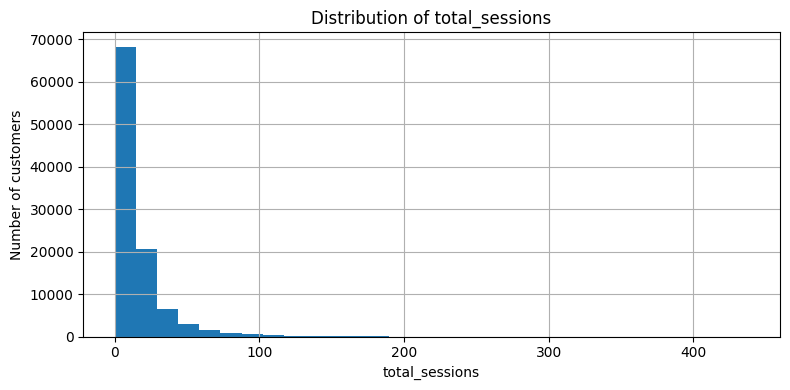

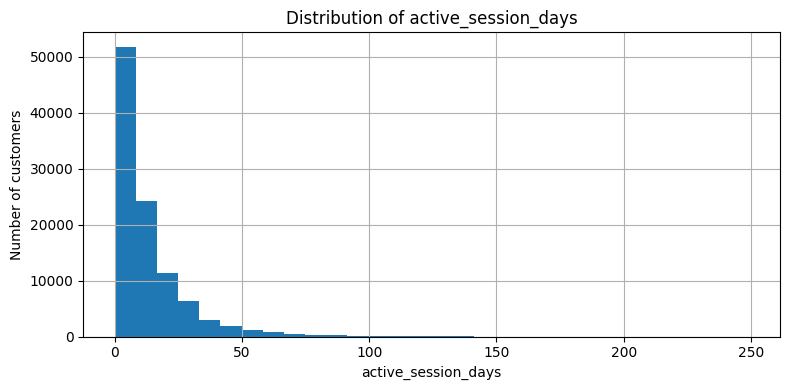

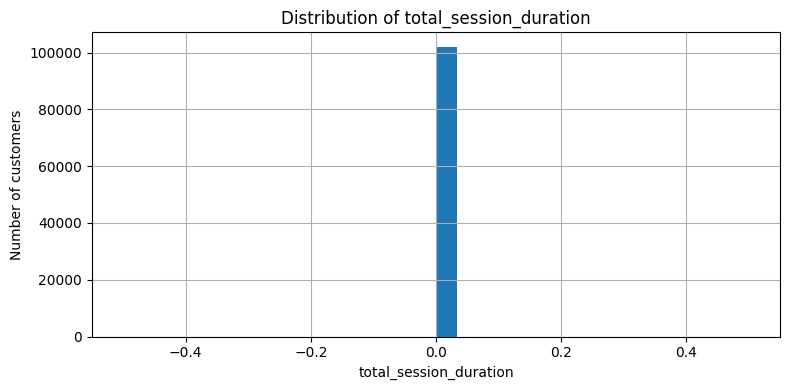

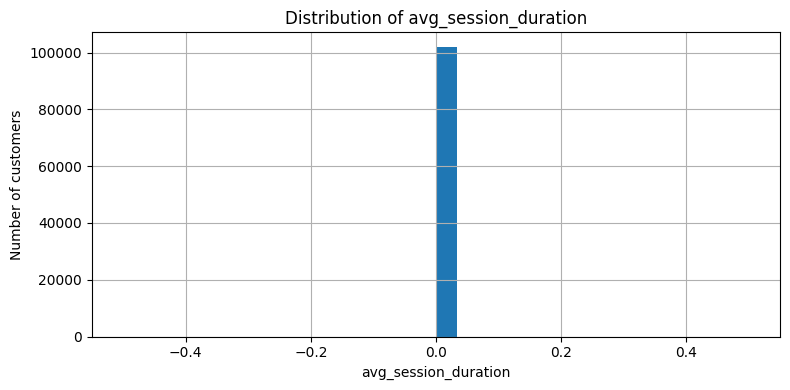

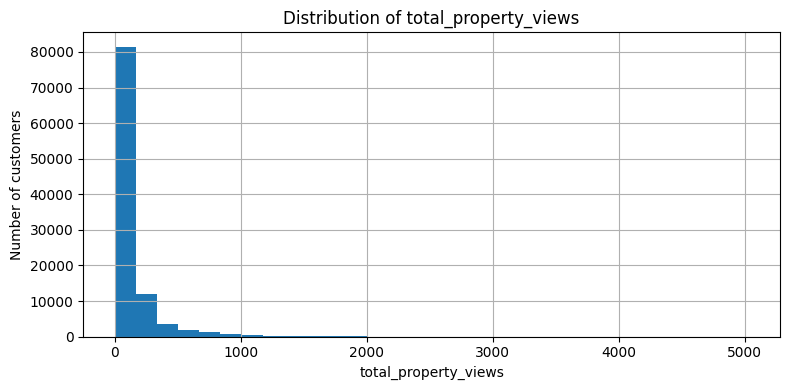

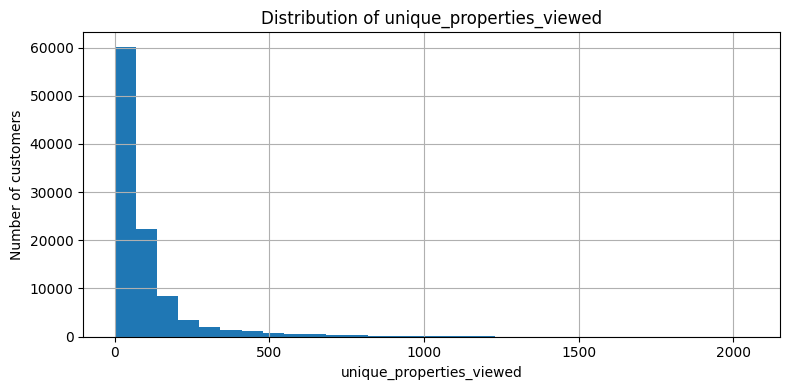

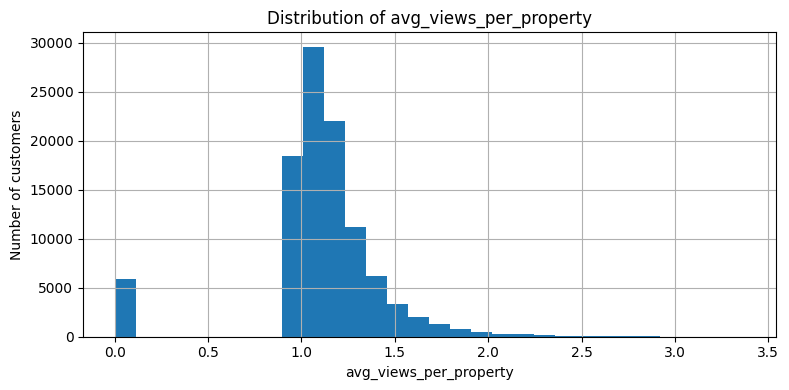

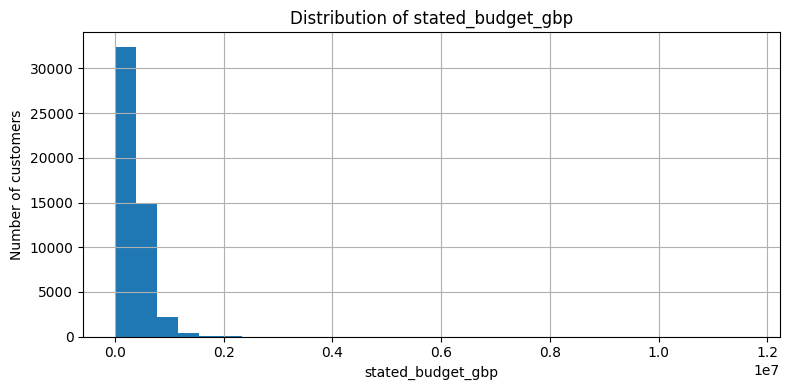

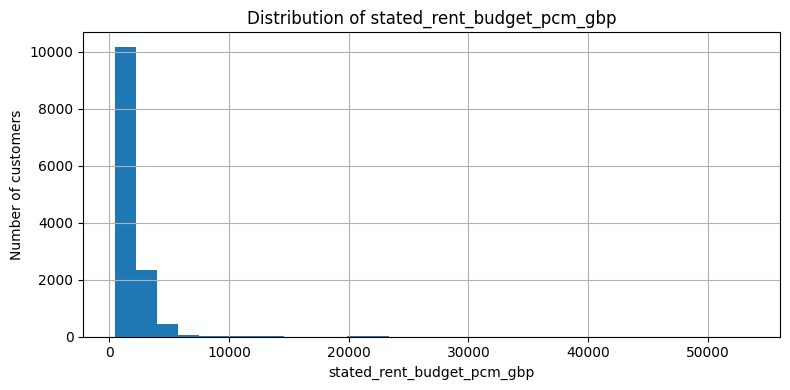

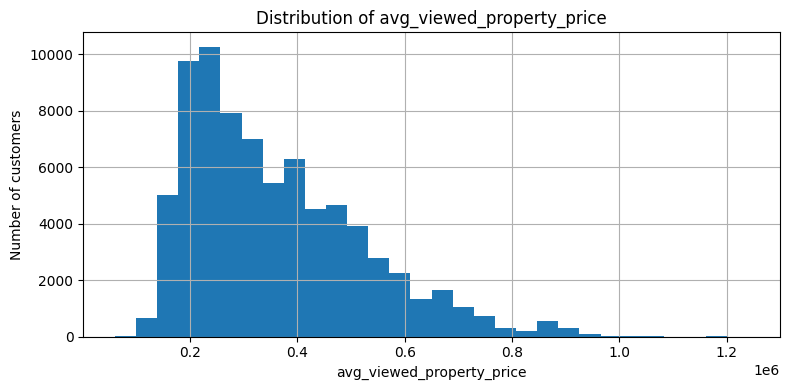

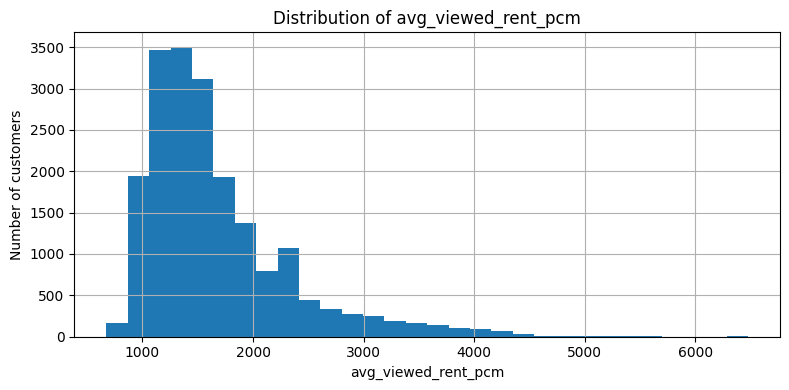

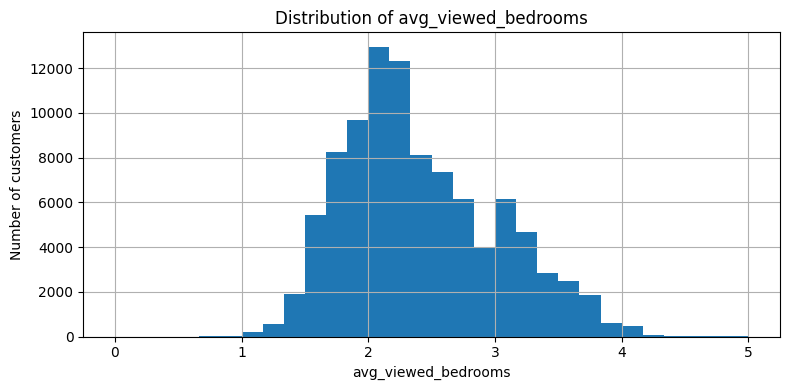

In [105]:
import matplotlib.pyplot as plt

for column in distribution_columns:

    plt.figure(figsize=(8, 4))

    customer_features[column].dropna().hist(bins=30)

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of customers")

    plt.tight_layout()
    plt.show()

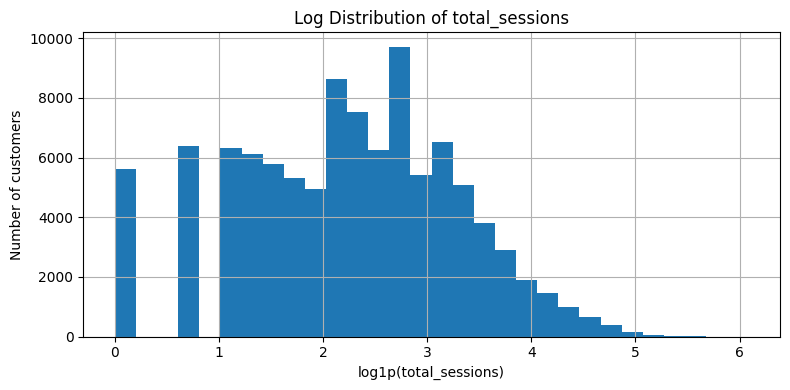

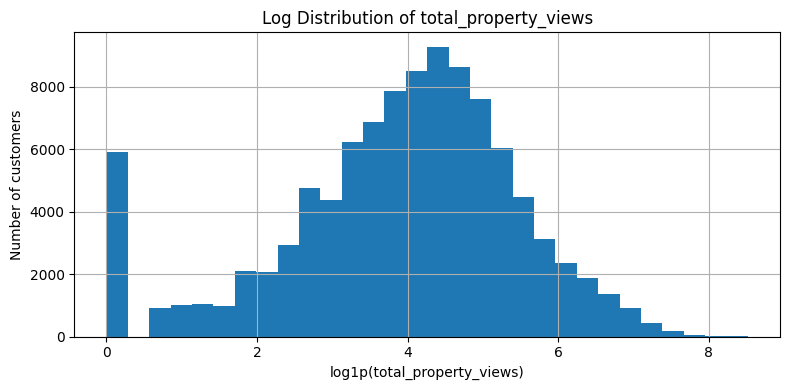

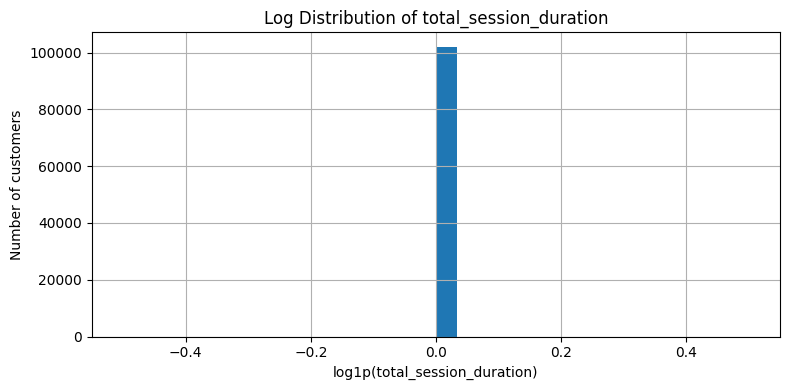

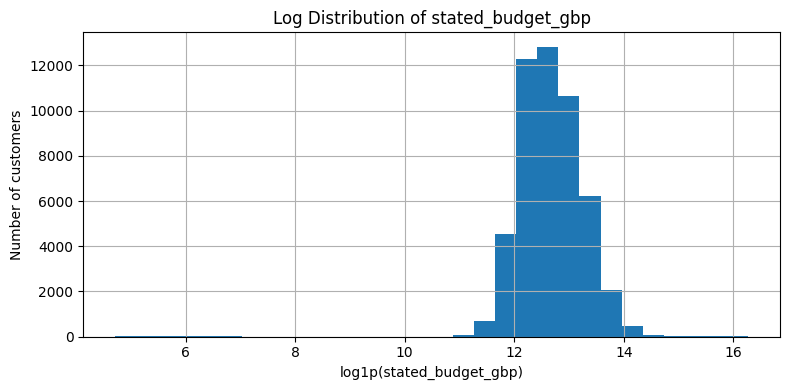

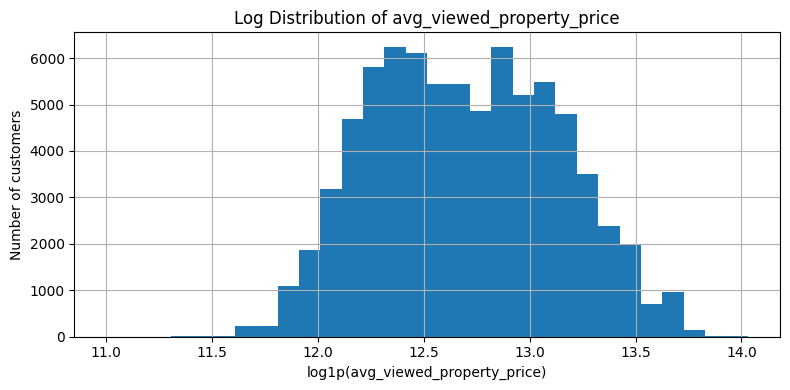

In [ ]:
#####-------> Applying Log Transformer for skwewness
skewed_columns = [
    "total_sessions",
    "total_property_views",
    "total_session_duration",
    "stated_budget_gbp",
    "avg_viewed_property_price"
]

for column in skewed_columns:

    if column in customer_features.columns:

        values = customer_features[column].dropna()

        plt.figure(figsize=(8, 4))
        np.log1p(values.clip(lower=0)).hist(bins=30)

        plt.title(f"Log Distribution of {column}")
        plt.xlabel(f"log1p({column})")
        plt.ylabel("Number of customers")

        plt.tight_layout()
        plt.show()

In [ ]:
####-----> final Validation checks
print("Customer feature dataset:", customer_features.shape)

print(
    "Duplicate customer IDs:",
    customer_features["customer_id"].duplicated().sum()
)

print(
    "Missing customer IDs:",
    customer_features["customer_id"].isna().sum()
)

print(
    "Customers with no sessions:",
    (customer_features["total_sessions"] == 0).sum()
)

print(
    "Customers with no property views:",
    (customer_features["total_property_views"] == 0).sum()
)

print(
    "Customers with missing stated budgets:",
    customer_features["stated_budget_gbp"].isna().sum()
)

Customer feature dataset: (102000, 45)
Duplicate customer IDs: 0
Missing customer IDs: 0
Customers with no sessions: 5632
Customers with no property views: 5904
Customers with missing stated budgets: 51986


#### Feature data segmentation preparation

In [113]:
# Inspect the tables needed for feature engineering

tables_to_check = [
    "customers",
    "properties",
    "property_views",
    "web_sessions",
    "interactions",
    "site_visits",
    "leads",
    "transactions"
]

for table in tables_to_check:
    print(f"\n{table.upper()}")

    try:
        columns = con.execute(
            f'DESCRIBE "{table}"'
        ).df()["column_name"].tolist()

        print(columns)

    except Exception as e:
        print(f"Could not inspect {table}: {e}")


CUSTOMERS
['customer_id', 'email_sha256', 'phone_sha256', 'customer_type', 'gender', 'age_band', 'occupation_sector', 'country_of_residence', 'is_overseas', 'uk_region_of_residence', 'buyer_position', 'finance_type', 'primary_intent', 'stated_budget_gbp', 'stated_rent_budget_pcm_gbp', 'preferred_currency', 'first_contact_date', 'consent_marketing', 'created_at']

PROPERTIES
['property_id', 'location_id', 'development_name', 'property_type', 'bedrooms', 'size_sqm', 'listing_purpose', 'asking_price_gbp', 'rent_pcm_gbp', 'new_build', 'development_status', 'tenure', 'epc_rating', 'council_tax_band', 'service_charge_gbp_pa', 'furnishing', 'first_marketed_date', 'latitude', 'longitude']

PROPERTY_VIEWS
['view_id', 'session_id', 'property_id', 'event_type', 'event_time']

WEB_SESSIONS
['session_id', 'customer_id', 'session_start', 'device', 'ip_country', 'traffic_source', 'pages_viewed', 'duration_sec']

INTERACTIONS
Could not inspect interactions: Catalog Error: Table with name interactions

In [ ]:
######-----> Check on existing customer feature to build other table features
# Inspect customer_features
display(
    con.execute("""
        DESCRIBE customer_features
    """).df()
)

# Check the number of customers
display(
    con.execute("""
        SELECT COUNT(*) AS total_customers
        FROM customer_features
    """).df()
)

# Check for duplicate customer IDs
display(
    con.execute("""
        SELECT
            COUNT(*) AS total_rows,
            COUNT(DISTINCT customer_id) AS unique_customers
        FROM customer_features
    """).df()
)

,column_name,column_type,null,key,default,extra
0,customer_id,VARCHAR,YES,None,None,None
1,email_sha256,VARCHAR,YES,None,None,None
2,phone_sha256,VARCHAR,YES,None,None,None
3,customer_type,VARCHAR,YES,None,None,None
4,gender,VARCHAR,YES,None,None,None
5,age_band,VARCHAR,YES,None,None,None
6,occupation_sector,VARCHAR,YES,None,None,None
7,country_of_residence,VARCHAR,YES,None,None,None
8,is_overseas,BOOLEAN,YES,None,None,None
9,uk_region_of_residence,VARCHAR,YES,None,None,None


,total_customers
0,102000


,total_rows,unique_customers
0,102000,102000


In [117]:
######-------> Inspect property-view event types
display(
    con.execute("""
        SELECT
            event_type,
            COUNT(*) AS total_events
        FROM property_views
        GROUP BY event_type
        ORDER BY total_events DESC
    """).df()
)

,event_type,total_events
0,View,12344608
1,Save,1188709
2,Virtual tour,734176
3,Share,449087
4,Floorplan download,446557


In [118]:
#####-------> Inspect Feature views
feature_views = [
    "customer_session_features",
    "customer_property_view_features",
    "customer_property_preference_features",
    "customer_viewed_property_details"
]

for view in feature_views:

    print(f"\n{view.upper()}")

    display(
        con.execute(
            f'DESCRIBE "{view}"'
        ).df()
    )


CUSTOMER_SESSION_FEATURES


,column_name,column_type,null,key,default,extra
0,customer_id,VARCHAR,YES,None,None,None
1,total_sessions,BIGINT,YES,None,None,None
2,active_session_days,BIGINT,YES,None,None,None
3,avg_session_duration,"""NULL""",YES,None,None,None
4,total_session_duration,"""NULL""",YES,None,None,None



CUSTOMER_PROPERTY_VIEW_FEATURES


,column_name,column_type,null,key,default,extra
0,customer_id,VARCHAR,YES,None,None,None
1,total_property_views,BIGINT,YES,None,None,None
2,unique_properties_viewed,BIGINT,YES,None,None,None
3,avg_views_per_property,DOUBLE,YES,None,None,None
4,avg_bedrooms_viewed,DOUBLE,YES,None,None,None
5,avg_property_price_viewed,DOUBLE,YES,None,None,None
6,avg_rent_viewed,DOUBLE,YES,None,None,None
7,property_types_explored,BIGINT,YES,None,None,None
8,countries_explored,BIGINT,YES,None,None,None
9,regions_explored,BIGINT,YES,None,None,None



CUSTOMER_PROPERTY_PREFERENCE_FEATURES


,column_name,column_type,null,key,default,extra
0,customer_id,VARCHAR,YES,None,None,None
1,avg_viewed_property_price,DOUBLE,YES,None,None,None
2,min_viewed_property_price,BIGINT,YES,None,None,None
3,max_viewed_property_price,BIGINT,YES,None,None,None
4,avg_viewed_rent_pcm,DOUBLE,YES,None,None,None
5,min_viewed_rent_pcm,BIGINT,YES,None,None,None
6,max_viewed_rent_pcm,BIGINT,YES,None,None,None
7,avg_viewed_bedrooms,DOUBLE,YES,None,None,None
8,property_types_viewed,BIGINT,YES,None,None,None
9,listing_purposes_viewed,BIGINT,YES,None,None,None



CUSTOMER_VIEWED_PROPERTY_DETAILS


,column_name,column_type,null,key,default,extra
0,customer_id,VARCHAR,YES,None,None,None
1,session_id,VARCHAR,YES,None,None,None
2,view_id,VARCHAR,YES,None,None,None
3,event_time,TIMESTAMP,YES,None,None,None
4,property_id,VARCHAR,YES,None,None,None
5,location_id,VARCHAR,YES,None,None,None
6,development_name,VARCHAR,YES,None,None,None
7,property_type,VARCHAR,YES,None,None,None
8,bedrooms,BIGINT,YES,None,None,None
9,size_sqm,BIGINT,YES,None,None,None


In [119]:
######--------> Calculate Virtual-tour share per customer
# Create customer-level virtual-tour features

con.execute("""
CREATE OR REPLACE VIEW customer_virtual_tour_features AS

SELECT
    ws.customer_id,

    COUNT(DISTINCT pv.view_id) AS total_view_events,

    COUNT(DISTINCT pv.view_id) FILTER (
        WHERE LOWER(TRIM(pv.event_type)) = 'virtual tour'
    ) AS virtual_tour_events,

    ROUND(
        COUNT(DISTINCT pv.view_id) FILTER (
            WHERE LOWER(TRIM(pv.event_type)) = 'virtual tour'
        ) * 1.0
        / NULLIF(COUNT(DISTINCT pv.view_id), 0),
        4
    ) AS virtual_tour_share

FROM property_views pv

INNER JOIN web_sessions ws
    ON pv.session_id = ws.session_id

WHERE ws.customer_id IS NOT NULL

GROUP BY ws.customer_id
""")

# Inspect the results
display(
    con.execute("""
        SELECT *
        FROM customer_virtual_tour_features
        ORDER BY virtual_tour_share DESC
        LIMIT 10
    """).df()
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,customer_id,total_view_events,virtual_tour_events,virtual_tour_share
0,VLX-C00079466,1,1,1.0
1,VLX-C00221720,1,1,1.0
2,VLX-C00163170,1,1,1.0
3,VLX-C00131733,1,1,1.0
4,VLX-C00292583,2,2,1.0
5,VLX-C00178948,1,1,1.0
6,VLX-C00271519,1,1,1.0
7,VLX-C00140496,1,1,1.0
8,VLX-C00033108,1,1,1.0
9,VLX-C00032288,1,1,1.0


In [120]:
#####-------> Add Night-Session Share
con.execute("""
CREATE OR REPLACE VIEW customer_night_session_features AS

SELECT
    customer_id,

    COUNT(DISTINCT session_id) AS total_sessions,

    COUNT(DISTINCT session_id) FILTER (
        WHERE
            EXTRACT(HOUR FROM CAST(session_start AS TIMESTAMP)) >= 20
            OR EXTRACT(HOUR FROM CAST(session_start AS TIMESTAMP)) < 6
    ) AS night_sessions,

    ROUND(
        COUNT(DISTINCT session_id) FILTER (
            WHERE
                EXTRACT(HOUR FROM CAST(session_start AS TIMESTAMP)) >= 20
                OR EXTRACT(HOUR FROM CAST(session_start AS TIMESTAMP)) < 6
        ) * 1.0
        / NULLIF(COUNT(DISTINCT session_id), 0),
        4
    ) AS night_session_share

FROM web_sessions

WHERE customer_id IS NOT NULL

GROUP BY customer_id
""")

In [121]:
#####======> Join new features to existing customer features
con.execute("""
CREATE OR REPLACE TABLE customer_features_enriched AS

SELECT
    cf.*,

    COALESCE(vt.virtual_tour_events, 0)
        AS virtual_tour_events,

    COALESCE(vt.virtual_tour_share, 0)
        AS virtual_tour_share,

    COALESCE(ns.night_sessions, 0)
        AS night_sessions,

    COALESCE(ns.night_session_share, 0)
        AS night_session_share

FROM customer_features cf

LEFT JOIN customer_virtual_tour_features vt
    ON cf.customer_id = vt.customer_id

LEFT JOIN customer_night_session_features ns
    ON cf.customer_id = ns.customer_id
""")

display(
    con.execute("""
        SELECT *
        FROM customer_features_enriched
        LIMIT 5
    """).df()
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,customer_id,email_sha256,phone_sha256,customer_type,gender,age_band,occupation_sector,country_of_residence,is_overseas,uk_region_of_residence,...,property_types_viewed,listing_purposes_viewed,areas_viewed,regions_viewed,countries_viewed,locations_viewed,virtual_tour_events,virtual_tour_share,night_sessions,night_session_share
0,VLX-C00199781,84440d16619590082580bf0dd02a0da6dedfe01ef7eb54...,None,Individual,Female,18-24,Healthcare,UK,False,North East,...,4.0,1.0,22.0,10.0,3.0,22.0,6,0.0550,4,0.2857
1,VLX-C00023243,ec00e151a25491614540a5129d7013f49ac53655b04cf7...,2c79fa7de15d65c2bfe58da61d91e8f1addfcb333d6d6e...,Individual,Male,None,Finance,United Kingdom,False,London,...,6.0,1.0,32.0,11.0,3.0,32.0,7,0.0283,8,0.4000
2,VLX-C00174207,bf2173a42d0149db5163aa7b2078f1bf5bbeac7482ae08...,None,Individual,Female,65+,Business owner,Saudi Arabia,True,None,...,6.0,1.0,22.0,9.0,2.0,22.0,47,0.2156,4,0.1429
3,VLX-C00099328,0d71515fc2a10dde63ff8407da07f659bdb83bb41c650d...,None,Individual,Female,35-44,Hospitality,United Kingdom,False,North West,...,6.0,1.0,36.0,11.0,3.0,36.0,21,0.0275,17,0.3333
4,VLX-C00165672,4f1a0233b30a5755fe5f2cc957f83514abac6568868b86...,0795be4e6785894afe20e201006cd4ff1893d9c0f867d5...,Individual,Female,25-34,None,England,False,North West,...,4.0,1.0,18.0,8.0,2.0,18.0,6,0.0397,8,0.3636


In [122]:
#######=======> Validate No duplicated feature records
display(
    con.execute("""
        SELECT
            COUNT(*) AS total_rows,
            COUNT(DISTINCT customer_id) AS unique_customers
        FROM customer_features_enriched
    """).df()
)

,total_rows,unique_customers
0,102000,102000


##### Investigate budget imputation and possible typos

In [123]:
display(
    con.execute("""
        SELECT
            listing_purpose,
            COUNT(*) AS property_count,
            MIN(asking_price_gbp) AS min_sale_price,
            MEDIAN(asking_price_gbp) AS median_sale_price,
            MAX(asking_price_gbp) AS max_sale_price,
            MIN(rent_pcm_gbp) AS min_rent,
            MEDIAN(rent_pcm_gbp) AS median_rent,
            MAX(rent_pcm_gbp) AS max_rent
        FROM properties
        GROUP BY listing_purpose
        ORDER BY property_count DESC
    """).df()
)

,listing_purpose,property_count,min_sale_price,median_sale_price,max_sale_price,min_rent,median_rent,max_rent
0,Sale,12550,40000,285000.0,2830000,<NA>,NaN,<NA>
1,Rent,4117,<NA>,NaN,<NA>,250,1225.0,7325


In [124]:
#####=========> investigating customer budget distribution:
display(
    con.execute("""
        SELECT
            COUNT(*) AS customers,

            COUNT(stated_budget_gbp) AS customers_with_purchase_budget,

            MEDIAN(stated_budget_gbp) AS median_purchase_budget,

            MIN(stated_budget_gbp) AS minimum_purchase_budget,

            MAX(stated_budget_gbp) AS maximum_purchase_budget,

            COUNT(stated_rent_budget_pcm_gbp) AS customers_with_rent_budget,

            MEDIAN(stated_rent_budget_pcm_gbp) AS median_rent_budget,

            MIN(stated_rent_budget_pcm_gbp) AS minimum_rent_budget,

            MAX(stated_rent_budget_pcm_gbp) AS maximum_rent_budget

        FROM customers
    """).df()
)

,customers,customers_with_purchase_budget,median_purchase_budget,minimum_purchase_budget,maximum_purchase_budget,customers_with_rent_budget,median_rent_budget,minimum_rent_budget,maximum_rent_budget
0,102000,50014,305000.0,110,11650000,13061,1500.0,450,53400


##### Median Agent Response Time

In [130]:
from pathlib import Path

# Project root (one level above notebooks)
ROOT = Path.cwd().parent

# Correct data directories
RAW_DIR = ROOT / "data" / "raw" / "veltrix_medium"

PROCESSED_DIR = ROOT / "data" / "processed" / "veltrix_medium"

RESULTS_DIR = ROOT / "Results" / "reports"

# Create output directories
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Raw data:", RAW_DIR)
print("Raw directory exists:", RAW_DIR.exists())



missing_tables = [
    "interactions",
    "leads",
    "site_visits",
    "transactions"
]

for table in missing_tables:

    matches = list(
        RAW_DIR.rglob(f"{table}*.parquet")
    )

    print(f"\n{table.upper()}")

    if matches:
        for file in matches:
            print(file)
    else:
        print("No Parquet files found.")

Project root: c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F
Raw data: c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\data\raw\veltrix_medium
Raw directory exists: True

INTERACTIONS
c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\data\raw\veltrix_medium\interactions.parquet

LEADS
c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\data\raw\veltrix_medium\leads.parquet

SITE_VISITS
c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\data\raw\veltrix_medium\site_visits.parquet

TRANSACTIONS
c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\data\raw\veltrix_medium\transactions.parquet


In [131]:
# Register the missing Parquet datasets in DuckDB

missing_tables = [
    "interactions",
    "leads",
    "site_visits",
    "transactions"
]

for table in missing_tables:

    file_path = RAW_DIR / f"{table}.parquet"

    con.execute(f"""
        CREATE OR REPLACE VIEW "{table}" AS
        SELECT *
        FROM read_parquet('{file_path.as_posix()}')
    """)

    print(f"{table}: registered successfully")

interactions: registered successfully
leads: registered successfully
site_visits: registered successfully
transactions: registered successfully


###### build the median agent response time feature.

The correct calculation is:
\[
\text{Response time} = \text{Agent response timestamp} - \text{Enquiry timestamp}
\]

We must match each response to the correct enquiry using a shared customer ID or lead ID. We should not calculate the difference between unrelated timestamps or use a customer’s earliest enquiry and an unrelated later interaction.

In [132]:
tables_to_inspect = [
    "interactions",
    "leads",
    "site_visits",
    "transactions"
]

for table in tables_to_inspect:
    print(f"\n{'=' * 60}")
    print(f"TABLE: {table.upper()}")
    print("=" * 60)

    schema = con.execute(
        f'DESCRIBE "{table}"'
    ).df()

    print(schema[["column_name", "column_type"]].to_string(index=False))


TABLE: INTERACTIONS
      column_name column_type
   interaction_id     VARCHAR
          lead_id     VARCHAR
         agent_id     VARCHAR
          channel     VARCHAR
        direction     VARCHAR
 interaction_time   TIMESTAMP
response_time_min      BIGINT
            topic     VARCHAR

TABLE: LEADS
 column_name column_type
     lead_id     VARCHAR
 customer_id     VARCHAR
    agent_id     VARCHAR
 lead_source     VARCHAR
 campaign_id     VARCHAR
      intent     VARCHAR
  lead_stage     VARCHAR
 lost_reason     VARCHAR
created_date   TIMESTAMP
 closed_date        DATE
   converted     BOOLEAN

TABLE: SITE_VISITS
column_name column_type
   visit_id     VARCHAR
    lead_id     VARCHAR
property_id     VARCHAR
 visit_type     VARCHAR
 visit_date        DATE
    outcome     VARCHAR

TABLE: TRANSACTIONS
               column_name column_type
            transaction_id     VARCHAR
                   lead_id     VARCHAR
               customer_id     VARCHAR
               property_id    

In [ ]:
######-----> Identify candidate columns and inspect sample records
import re

keywords = (
    r"timestamp|datetime|date|time|customer_id|lead_id|"
    r"agent_id|enquir|response|reply|contact|interaction|"
    r"created|updated|assigned"
)

for table in tables_to_inspect:

    schema = con.execute(
        f'DESCRIBE "{table}"'
    ).df()

    candidates = schema[
        schema["column_name"].str.contains(
            keywords,
            case=False,
            regex=True,
            na=False
        )
    ]

    print(f"\n{'=' * 60}")
    print(f"CANDIDATE COLUMNS: {table.upper()}")
    print("=" * 60)

    print(candidates[["column_name", "column_type"]].to_string(index=False))

    print("\nSAMPLE RECORDS:")
    sample = con.execute(
        f'SELECT * FROM "{table}" LIMIT 5'
    ).df()

    display(sample)


CANDIDATE COLUMNS: INTERACTIONS
      column_name column_type
   interaction_id     VARCHAR
          lead_id     VARCHAR
         agent_id     VARCHAR
 interaction_time   TIMESTAMP
response_time_min      BIGINT

SAMPLE RECORDS:


,interaction_id,lead_id,agent_id,channel,direction,interaction_time,response_time_min,topic
0,VLX-I0000020001,VLX-L000010001,VLX-A00001,Video call,Inbound,2023-01-01 02:46:18,214,Off-plan payment schedule
1,VLX-I0000020002,VLX-L000010002,VLX-A00067,Phone,Inbound,2023-01-01 08:32:55,34,Chain and timescales
2,VLX-I0000020003,VLX-L000010003,VLX-A00041,Phone,Inbound,2023-01-01 09:57:04,43,Viewing arrangements
3,VLX-I0000020004,VLX-L000010005,VLX-A00297,Phone,Outbound,2023-01-01 10:23:16,<NA>,Mortgage and finance
4,VLX-I0000020005,VLX-L000010004,VLX-A00042,Email,Inbound,2023-01-01 11:29:45,28,Chain and timescales



CANDIDATE COLUMNS: LEADS
 column_name column_type
     lead_id     VARCHAR
 customer_id     VARCHAR
    agent_id     VARCHAR
created_date   TIMESTAMP
 closed_date        DATE

SAMPLE RECORDS:


,lead_id,customer_id,agent_id,lead_source,campaign_id,intent,lead_stage,lost_reason,created_date,closed_date,converted
0,VLX-L000010001,VLX-C00131607,VLX-A00001,Email newsletter,None,Buy,Lost,Not ready to move,2023-01-01 02:46:18,2023-09-21,False
1,VLX-L000010002,VLX-C00020783,VLX-A00067,RightMove,None,Buy,Lost,Outbid,2023-01-01 08:32:55,2023-03-10,False
2,VLX-L000010003,VLX-C00176037,VLX-A00042,OnTheMarket,None,Buy,Lost,Mortgage declined,2023-01-01 09:57:04,2023-02-27,False
3,VLX-L000010004,VLX-C00277011,VLX-A00042,Right Move,None,Buy,Lost,Not ready to move,2023-01-01 11:29:45,2023-04-21,False
4,VLX-L000010005,VLX-C00065712,VLX-A00297,Zoopla,None,Buy,Lost,Outbid,2023-01-01 11:39:15,2023-02-07,False



CANDIDATE COLUMNS: SITE_VISITS
column_name column_type
    lead_id     VARCHAR
 visit_date        DATE

SAMPLE RECORDS:


,visit_id,lead_id,property_id,visit_type,visit_date,outcome
0,VLX-SV000001001,VLX-L000010006,VLX-P0002614,In person,2023-01-01,Interested
1,VLX-SV000001002,VLX-L000010012,VLX-P0010618,In person,2023-01-02,Second viewing requested
2,VLX-SV000001003,VLX-L000010028,VLX-P0011297,In person,2023-01-02,Application submitted
3,VLX-SV000001004,VLX-L000010027,VLX-P0016633,Virtual,2023-01-02,Second viewing requested
4,VLX-SV000001005,VLX-L000010036,VLX-P0001160,In person,2023-01-02,Not interested



CANDIDATE COLUMNS: TRANSACTIONS
               column_name column_type
                   lead_id     VARCHAR
               customer_id     VARCHAR
             contract_date        DATE
completion_or_move_in_date        DATE

SAMPLE RECORDS:


,transaction_id,lead_id,customer_id,property_id,transaction_type,finance_type,agreed_price_gbp,agreed_rent_pcm_gbp,discount_pct,contract_date,completion_or_move_in_date,tenancy_months,mortgage_ltv_pct,payment_currency
0,VLX-T00000101,VLX-L000010027,VLX-C00304824,VLX-P0016214,Company let,Company let,<NA>,2955,0.6,2023-01-13,2023-01-21,24,NaN,GBP
1,VLX-T00000102,VLX-L000010043,VLX-C00169460,VLX-P0001428,Assured shorthold tenancy,None,<NA>,3085,1.3,2023-01-14,2023-02-12,12,NaN,GBP
2,VLX-T00000103,VLX-L000010288,VLX-C00218915,VLX-P0012400,Assured shorthold tenancy,None,<NA>,980,2.0,2023-01-14,2023-02-06,12,NaN,GBP
3,VLX-T00000104,VLX-L000010158,VLX-C00036843,VLX-P0001556,Assured shorthold tenancy,None,<NA>,1335,3.0,2023-01-14,2023-01-29,24,NaN,GBP
4,VLX-T00000105,VLX-L000010212,VLX-C00243422,VLX-P0013173,Assured shorthold tenancy,None,<NA>,685,-1.5,2023-01-15,2023-02-13,12,NaN,GBP


In [134]:
######-----> check how response time are recorded
response_check = con.execute("""
    SELECT
        LOWER(TRIM(direction)) AS direction,
        COUNT(*) AS total_interactions,
        COUNT(response_time_min) AS recorded_response_times,
        ROUND(
            100.0 * COUNT(response_time_min) / COUNT(*), 2
        ) AS response_time_completeness_pct,
        MIN(response_time_min) AS minimum_response_min,
        MEDIAN(response_time_min) AS median_response_min,
        QUANTILE_CONT(response_time_min, 0.95) AS p95_response_min,
        MAX(response_time_min) AS maximum_response_min
    FROM interactions
    GROUP BY LOWER(TRIM(direction))
    ORDER BY direction
""").df()

display(response_check)

,direction,total_interactions,recorded_response_times,response_time_completeness_pct,minimum_response_min,median_response_min,p95_response_min,maximum_response_min
0,inbound,292997,287167,98.01,1,183.0,1465.0,4320
1,outbound,239792,0,0.00,<NA>,NaN,NaN,<NA>


In [135]:
#####------> how many interactions match lead:

link_check = con.execute("""
    SELECT
        COUNT(*) AS total_interactions,
        COUNT(l.lead_id) AS matched_interactions,
        COUNT(*) - COUNT(l.lead_id) AS unmatched_interactions,
        COUNT(DISTINCT i.lead_id) AS distinct_interaction_leads,
        COUNT(DISTINCT l.customer_id) AS matched_customers
    FROM interactions i
    LEFT JOIN leads l
        ON i.lead_id = l.lead_id
""").df()

display(link_check)

,total_interactions,matched_interactions,unmatched_interactions,distinct_interaction_leads,matched_customers
0,532789,532789,0,95804,61030


In [136]:
#####-----> calculate the response time using both methods
con.execute("""
CREATE OR REPLACE VIEW lead_response_time_features AS

WITH recorded_response AS (

    SELECT
        l.customer_id,
        l.lead_id,
        MEDIAN(i.response_time_min) AS median_recorded_response_min,
        COUNT(i.response_time_min) AS recorded_response_count

    FROM leads l

    INNER JOIN interactions i
        ON l.lead_id = i.lead_id

    WHERE l.customer_id IS NOT NULL
      AND i.response_time_min IS NOT NULL
      AND i.response_time_min >= 0

    GROUP BY
        l.customer_id,
        l.lead_id
),

first_outbound_response AS (

    SELECT
        l.customer_id,
        l.lead_id,

        MIN(i.interaction_time) AS first_outbound_time,

        DATE_DIFF(
            'second',
            l.created_date,
            MIN(i.interaction_time)
        ) / 60.0 AS first_outbound_response_min

    FROM leads l

    INNER JOIN interactions i
        ON l.lead_id = i.lead_id

    WHERE l.customer_id IS NOT NULL
      AND i.interaction_time IS NOT NULL
      AND LOWER(TRIM(i.direction)) = 'outbound'
      AND i.interaction_time >= l.created_date

    GROUP BY
        l.customer_id,
        l.lead_id,
        l.created_date
)

SELECT
    COALESCE(r.customer_id, o.customer_id) AS customer_id,

    MEDIAN(r.median_recorded_response_min)
        AS median_recorded_response_min,

    MEDIAN(o.first_outbound_response_min)
        AS median_first_outbound_response_min,

    SUM(COALESCE(r.recorded_response_count, 0))
        AS recorded_response_count,

    COUNT(DISTINCT r.lead_id)
        AS leads_with_recorded_response,

    COUNT(DISTINCT o.lead_id)
        AS leads_with_outbound_response

FROM recorded_response r

FULL OUTER JOIN first_outbound_response o
    ON r.customer_id = o.customer_id
   AND r.lead_id = o.lead_id

GROUP BY
    COALESCE(r.customer_id, o.customer_id)
""")

In [ ]:
######--------> Inspect customer-level results
response_features = con.execute("""
    SELECT *
    FROM lead_response_time_features
    ORDER BY median_recorded_response_min
    LIMIT 20
""").df()

display(response_features)

,customer_id,median_recorded_response_min,median_first_outbound_response_min,recorded_response_count,leads_with_recorded_response,leads_with_outbound_response
0,VLX-C00019041,2.0,23178.933333,1.0,1,1
1,VLX-C00227789,4.0,8333.550000,1.0,1,1
2,VLX-C00260706,4.0,2966.866667,1.0,1,1
3,VLX-C00065705,4.0,17680.816667,1.0,1,1
4,VLX-C00218737,4.0,28478.166667,1.0,1,1
5,VLX-C00208161,5.0,42770.683333,1.0,1,1
6,VLX-C00070970,5.0,3259.533333,2.0,1,1
7,VLX-C00192328,6.0,NaN,1.0,1,0
8,VLX-C00038818,6.0,NaN,1.0,1,0
9,VLX-C00291000,6.0,27296.000000,1.0,1,1


In [ ]:
#######-----------> Reponse time comparisons
comparison = con.execute("""
    SELECT
        COUNT(*) AS customers_with_response_data,

        COUNT(median_recorded_response_min)
            AS customers_with_recorded_response,

        COUNT(median_first_outbound_response_min)
            AS customers_with_outbound_response,

        ROUND(MEDIAN(median_recorded_response_min), 2)
            AS overall_median_recorded_min,

        ROUND(MEDIAN(median_first_outbound_response_min), 2)
            AS overall_median_outbound_min,

        ROUND(
            QUANTILE_CONT(median_recorded_response_min, 0.95), 2
        ) AS recorded_response_p95_min

    FROM lead_response_time_features
""").df()

display(comparison)

,customers_with_response_data,customers_with_recorded_response,customers_with_outbound_response,overall_median_recorded_min,overall_median_outbound_min,recorded_response_p95_min
0,60995,60882,54761,234.5,12241.28,1141.5


#### Inspect columns before cleaning

In [139]:
# Inspect the tables needed for feature engineering

tables_to_check = [
    "customers",
    "properties",
    "property_views",
    "web_sessions",
    "interactions",
    "site_visits",
    "leads",
    "transactions"
]

for table in tables_to_check:
    print(f"\n{table.upper()}")

    try:
        columns = con.execute(
            f'DESCRIBE "{table}"'
        ).df()["column_name"].tolist()

        print(columns)

    except Exception as e:
        print(f"Could not inspect {table}: {e}")


CUSTOMERS
['customer_id', 'email_sha256', 'phone_sha256', 'customer_type', 'gender', 'age_band', 'occupation_sector', 'country_of_residence', 'is_overseas', 'uk_region_of_residence', 'buyer_position', 'finance_type', 'primary_intent', 'stated_budget_gbp', 'stated_rent_budget_pcm_gbp', 'preferred_currency', 'first_contact_date', 'consent_marketing', 'created_at']

PROPERTIES
['property_id', 'location_id', 'development_name', 'property_type', 'bedrooms', 'size_sqm', 'listing_purpose', 'asking_price_gbp', 'rent_pcm_gbp', 'new_build', 'development_status', 'tenure', 'epc_rating', 'council_tax_band', 'service_charge_gbp_pa', 'furnishing', 'first_marketed_date', 'latitude', 'longitude']

PROPERTY_VIEWS
['view_id', 'session_id', 'property_id', 'event_type', 'event_time']

WEB_SESSIONS
['session_id', 'customer_id', 'session_start', 'device', 'ip_country', 'traffic_source', 'pages_viewed', 'duration_sec']

INTERACTIONS
['interaction_id', 'lead_id', 'agent_id', 'channel', 'direction', 'interact

In [141]:
######---------> Create Behavioural Features
"""define a night session as one starting between 20:00 and 05:59."""
# Create night-session features in DuckDB

con.execute("""
CREATE OR REPLACE VIEW customer_night_session_features AS
SELECT
    customer_id,

    COUNT(DISTINCT session_id) AS total_sessions,

    COUNT(DISTINCT session_id) FILTER (
        WHERE
            EXTRACT(HOUR FROM CAST(session_start AS TIMESTAMP)) >= 20
            OR EXTRACT(HOUR FROM CAST(session_start AS TIMESTAMP)) < 6
    ) AS night_sessions,

    ROUND(
        COUNT(DISTINCT session_id) FILTER (
            WHERE
                EXTRACT(HOUR FROM CAST(session_start AS TIMESTAMP)) >= 20
                OR EXTRACT(HOUR FROM CAST(session_start AS TIMESTAMP)) < 6
        ) * 1.0
        / NULLIF(COUNT(DISTINCT session_id), 0),
        4
    ) AS night_session_share

FROM web_sessions
WHERE customer_id IS NOT NULL
GROUP BY customer_id
""")

night_features = con.execute("""
    SELECT *
    FROM customer_night_session_features
""").df()

print("ASSUMPTIONS:night session as one starting between 20:00 and 05:59.")
print(night_features.head())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

ASSUMPTIONS:night session as one starting between 20:00 and 05:59.
     customer_id  total_sessions  night_sessions  night_session_share
0  VLX-C00063938              23               5               0.2174
1  VLX-C00251259              33              12               0.3636
2  VLX-C00182605               8               2               0.2500
3  VLX-C00228228              21               8               0.3810
4  VLX-C00219227              42              13               0.3095


In [144]:
#######=======> Add Nigt-Session features to customer features
customer_features = customer_features.merge(
    night_features[
        ["customer_id", "night_sessions", "night_session_share"]
    ],
    on="customer_id",
    how="left"
)

customer_features["night_sessions"] = (
    customer_features["night_sessions"].fillna(0)
)

customer_features["night_session_share"] = (
    customer_features["night_session_share"].fillna(0)
)

customer_features

,customer_id,email_sha256,phone_sha256,customer_type,gender,age_band,occupation_sector,country_of_residence,is_overseas,uk_region_of_residence,...,areas_viewed,regions_viewed,countries_viewed,locations_viewed,night_sessions_x,night_session_share_x,night_sessions_y,night_session_share_y,night_sessions,night_session_share
0,VLX-C00127559,cee942d4ef6870f680b2449f60b3752409a30deea7bb8f...,f25f93572ea10876a91e0c954f872681dfe44bc275af1f...,Individual,Male,18-24,Unknown,United Kingdom,False,London,...,34.0,11.0,3.0,34.0,14.0,0.2414,14.0,0.2414,14.0,0.2414
1,VLX-C00168848,1d312463c090da13d3f8e1ceeb5b9efcd8acfbf1c825d6...,34f46ff1ce0bc52cfe142176ae16aa8cf8bc86fbc9e9d2...,Individual,Male,25-34,Unknown,United Kingdom,False,South East,...,14.0,8.0,3.0,14.0,1.0,0.1667,1.0,0.1667,1.0,0.1667
2,VLX-C00155207,a89d26ac98e7b1b305848ee8acd6e519fbf302f2a05d12...,1abeda4811132a5aa955a909471d7462c27f6b8d123e84...,Individual,Female,65+,Unknown,United Kingdom,False,East Midlands,...,9.0,6.0,2.0,9.0,2.0,0.5000,2.0,0.5000,2.0,0.5000
3,VLX-C00247948,992ff440f07ec60b59ee61bb11c1849fcf992026d973fd...,9fb2f49fde40a903054b58ce406b556815de43bf82e7ec...,Individual,Female,45-54,Hospitality,United States,True,Unknown,...,9.0,6.0,2.0,9.0,2.0,0.4000,2.0,0.4000,2.0,0.4000
4,VLX-C00238325,e3f395363fc3a3ed6bd295c50cb64e4e26e6b8add80e74...,a659636e76f9e2f8a3e681de30fc5c37eb262b087f0fac...,Individual,Male,Unknown,Technology,United Kingdom,False,South East,...,7.0,5.0,1.0,7.0,0.0,0.0000,0.0,0.0000,0.0,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101995,VLX-C00204242,79c2d8740677842897b96ae39b037994e44ecb0623bc7d...,0d14086f07b4fcc9a1bf9232a2d9cd61c2b2927e459665...,Individual,Male,55-64,Public sector,United Kingdom,False,London,...,0.0,0.0,0.0,0.0,0.0,0.0000,NaN,NaN,0.0,0.0000
101996,VLX-C00093513,27dffc053a1c8d43e90a2ddbc4d5a7b76ccc04f296967a...,None,Individual,Not stated,Unknown,Finance,Canada,True,Unknown,...,0.0,0.0,0.0,0.0,0.0,0.0000,NaN,NaN,0.0,0.0000
101997,VLX-C00229346,cb25fe2bf293b002744448b36a16b0181f16b73c5c6cf4...,None,Individual,Not stated,Unknown,Finance,United Kingdom,False,South East,...,9.0,6.0,1.0,9.0,1.0,0.3333,1.0,0.3333,1.0,0.3333
101998,VLX-C00299892,a3ad97b0ffbda34a4944fd233c32966d0d03e7a23c65ba...,27256047d99b8ac9873ed427ec881d1172e0a4daa26679...,Individual,Female,35-44,Education,United Kingdom,False,Scotland,...,8.0,5.0,2.0,8.0,0.0,0.0000,0.0,0.0000,0.0,0.0000


In [145]:
# Inspect customer budget columns
customer_columns = con.execute(
    "DESCRIBE customers"
).df()["column_name"].tolist()

print("Customer columns:", customer_columns)

# Inspect property columns
property_columns = con.execute(
    "DESCRIBE properties"
).df()["column_name"].tolist()

print("Property columns:", property_columns)

Customer columns: ['customer_id', 'email_sha256', 'phone_sha256', 'customer_type', 'gender', 'age_band', 'occupation_sector', 'country_of_residence', 'is_overseas', 'uk_region_of_residence', 'buyer_position', 'finance_type', 'primary_intent', 'stated_budget_gbp', 'stated_rent_budget_pcm_gbp', 'preferred_currency', 'first_contact_date', 'consent_marketing', 'created_at']
Property columns: ['property_id', 'location_id', 'development_name', 'property_type', 'bedrooms', 'size_sqm', 'listing_purpose', 'asking_price_gbp', 'rent_pcm_gbp', 'new_build', 'development_status', 'tenure', 'epc_rating', 'council_tax_band', 'service_charge_gbp_pa', 'furnishing', 'first_marketed_date', 'latitude', 'longitude']


In [ ]:
#######=======> imput customer budget
median_viewed_price = con.execute("""
    SELECT
        ws.customer_id,

        MEDIAN(p.asking_price_gbp) AS median_viewed_property_price

    FROM main.property_views AS pv

    INNER JOIN main.web_sessions AS ws
        ON pv.session_id = ws.session_id

    INNER JOIN main.properties AS p
        ON pv.property_id = p.property_id

    WHERE ws.customer_id IS NOT NULL
      AND p.asking_price_gbp IS NOT NULL

    GROUP BY ws.customer_id

    ORDER BY ws.customer_id
""").df()

display(median_viewed_price.head(10))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,customer_id,median_viewed_property_price
0,VLX-C00010000,447500.0
1,VLX-C00010006,300000.0
2,VLX-C00010009,205000.0
3,VLX-C00010010,685000.0
4,VLX-C00010011,170000.0
5,VLX-C00010015,255000.0
6,VLX-C00010020,455000.0
7,VLX-C00010021,342500.0
8,VLX-C00010032,145000.0
9,VLX-C00010037,205000.0


In [148]:
#####----Add median price to customer feature
customer_features = customer_features.merge(
    median_viewed_price,
    on="customer_id",
    how="left"
)

### validate results
print(
    "Customers with median viewed property price:",
    customer_features["median_viewed_property_price"].notna().sum()
)

print(
    "Customers without median viewed property price:",
    customer_features["median_viewed_property_price"].isna().sum()
)

display(
    customer_features["median_viewed_property_price"].describe()
)

Customers with median viewed property price: 76610
Customers without median viewed property price: 25390


count    7.661000e+04
mean     3.446011e+05
std      1.609274e+05
min      6.000000e+04
25%      2.200000e+05
50%      3.000000e+05
75%      4.400000e+05
max      1.240000e+06
Name: median_viewed_property_price, dtype: float64

##### Log-transform money features

In [149]:
import numpy as np

money_columns = [
    "budget",
    "avg_viewed_property_price",
    "median_viewed_property_price"
]

# Keep only columns that exist
money_columns = [
    col for col in money_columns
    if col in customer_features.columns
]

for col in money_columns:

    # Convert to numeric
    customer_features[col] = pd.to_numeric(
        customer_features[col],
        errors="coerce"
    )

    # Log-transform non-negative values
    invalid = customer_features[col] < 0

    if invalid.any():
        print(f"{col}: {invalid.sum()} negative values need investigation.")

    valid = customer_features[col].notna() & ~invalid

    customer_features.loc[valid, col] = np.log1p(
        customer_features.loc[valid, col]
    )

In [ ]:
# Identify numerical columns
numeric_features = customer_features.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

# Exclude identifiers and outcomes
excluded_columns = [
    "customer_id",
    "converted",
    "conversion_status",
    "conversion_date",
    "transaction_id",
    "lead_id"
]

numeric_features = [
    col for col in numeric_features
    if col not in excluded_columns
]

# Calculate correlation matrix
correlation_matrix = customer_features[
    numeric_features
].corr().abs()

# Get upper triangle
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

# Identify features to remove
high_correlation_features = [
    column
    for column in upper_triangle.columns
    if any(upper_triangle[column] > 0.80)
]

print("Features removed due to high correlation:")
print(high_correlation_features)

# Drop redundant features
customer_features_reduced = customer_features.drop(
    columns=high_correlation_features,
    errors="ignore"
)

print("Original feature count:", len(numeric_features))
print("Removed feature count:", len(high_correlation_features))
print("Remaining feature count:", len(numeric_features) - len(high_correlation_features))


Features removed due to high correlation:
['active_session_days', 'total_property_views', 'unique_properties_viewed', 'regions_explored', 'avg_viewed_property_price', 'avg_viewed_rent_pcm', 'min_viewed_rent_pcm', 'avg_viewed_bedrooms', 'property_types_viewed', 'listing_purposes_viewed', 'areas_viewed', 'regions_viewed', 'countries_viewed', 'locations_viewed', 'night_sessions_x', 'night_sessions_y', 'night_session_share_y', 'night_sessions', 'night_session_share', 'median_viewed_property_price']
Original feature count: 35
Removed feature count: 20
Remaining feature count: 15


In [ ]:
#######========> Summary of Featured Dataset for Transformation
print("Original feature count:", (numeric_features))
print("Removed feature count:", (high_correlation_features))
remain_feat = len(numeric_features) - len(high_correlation_features)
print("Remaining feature count:", remain_feat)

Original feature count: ['stated_budget_gbp', 'stated_rent_budget_pcm_gbp', 'total_sessions', 'active_session_days', 'avg_session_duration', 'total_session_duration', 'total_property_views', 'unique_properties_viewed', 'avg_views_per_property', 'avg_bedrooms_viewed', 'avg_property_price_viewed', 'avg_rent_viewed', 'property_types_explored', 'countries_explored', 'regions_explored', 'avg_viewed_property_price', 'min_viewed_property_price', 'max_viewed_property_price', 'avg_viewed_rent_pcm', 'min_viewed_rent_pcm', 'max_viewed_rent_pcm', 'avg_viewed_bedrooms', 'property_types_viewed', 'listing_purposes_viewed', 'areas_viewed', 'regions_viewed', 'countries_viewed', 'locations_viewed', 'night_sessions_x', 'night_session_share_x', 'night_sessions_y', 'night_session_share_y', 'night_sessions', 'night_session_share', 'median_viewed_property_price']
Removed feature count: ['active_session_days', 'total_property_views', 'unique_properties_viewed', 'regions_explored', 'avg_viewed_property_price',

#### Scale Numerical Features
Use StandardScaler so that variables with large numerical ranges do not dominate the segmentation model.

In [152]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Columns that must never enter the clustering model
excluded_columns = [
    "customer_id",
    "converted",
    "conversion_status",
    "conversion_date",
    "transaction_id",
    "lead_id"
]

# Select numerical model features
model_features = customer_features_reduced.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

model_features = [
    col for col in model_features
    if col not in excluded_columns
]

# Create model dataset
X = customer_features_reduced[model_features].copy()

# Replace infinite values
X = X.replace([np.inf, -np.inf], np.nan)

# Impute remaining missing numerical features
imputer = SimpleImputer(strategy="median")

X_imputed = imputer.fit_transform(X)

# Scale features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_imputed)

# Convert back to DataFrame
X_model = pd.DataFrame(
    X_scaled,
    columns=model_features,
    index=customer_features_reduced.index
)

print("Final model dataset shape:", X_model.shape)

display(X_model.head())

Final model dataset shape: (102000, 15)


,stated_budget_gbp,stated_rent_budget_pcm_gbp,total_sessions,avg_session_duration,total_session_duration,avg_views_per_property,avg_bedrooms_viewed,avg_property_price_viewed,avg_rent_viewed,property_types_explored,countries_explored,min_viewed_property_price,max_viewed_property_price,max_viewed_rent_pcm,night_session_share_x
0,-0.167595,2.060513,2.336679,0.0,0.0,2.130847,-0.591161,-0.215961,1.595245,0.583140,1.029165,-0.212558,-0.204833,3.407358,-0.285141
1,-0.625589,-0.080618,-0.471526,0.0,0.0,0.157393,-1.290998,-0.762688,-0.116001,-0.047422,1.029165,-0.793855,-0.972430,-0.075597,-0.626962
2,3.063808,-0.080618,-0.579534,0.0,0.0,0.070329,1.252310,0.980642,-0.116001,0.583140,-0.055275,1.079213,0.099309,-0.075597,0.898189
3,-0.803698,-0.080618,-0.525530,0.0,0.0,-0.335970,-1.103237,-1.222328,-0.116001,-0.047422,-0.055275,-0.664677,-1.117259,-0.075597,0.440598
4,-0.167595,-0.452989,-0.687542,0.0,0.0,-0.335970,-0.454608,-0.215961,-0.587185,-0.047422,-1.139714,-0.212558,-0.204833,-2.111786,-1.389766


In [153]:
#####========> Keep Conversion outcomes outside the model
## Check that outcome columns are excluded
outcome_columns = [
    "converted",
    "conversion_status",
    "conversion_date",
    "transaction_id"
]

print("Outcome columns in model:")
print([
    col for col in outcome_columns
    if col in X_model.columns
])

# Keep customer IDs separately for later interpretation
customer_ids = customer_features_reduced["customer_id"].copy()

# Final model-ready dataset
segmentation_dataset = X_model.copy()

print("Final segmentation dataset:", segmentation_dataset.shape)

Outcome columns in model:
[]
Final segmentation dataset: (102000, 15)


#### Save the final Datasets for model

In [157]:
from pathlib import Path
import os

# Use the current working directory
BASE_DIR = Path.cwd().parent

# Output folders
CSV_DIR = BASE_DIR /"data" /"csv"/ "segment_csv"
RESULTS_DIR = BASE_DIR / "Results"/ "segment_parquet_copy"

# Create folders if they do not exist
CSV_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# 1. MODEL-READY SCALED SEGMENTATION FEATURES
# --------------------------------------------------

# CSV
segmentation_dataset.to_csv(
    CSV_DIR / "customer_segmentation_features.csv",
    index=False
)

# Parquet
segmentation_dataset.to_parquet(
    RESULTS_DIR / "customer_segmentation_features.parquet",
    index=False
)


# --------------------------------------------------
# 2. CUSTOMER IDS
# --------------------------------------------------

# CSV
customer_ids.to_frame().to_csv(
    CSV_DIR / "customer_segmentation_ids.csv",
    index=False
)

# Parquet
customer_ids.to_frame().to_parquet(
    RESULTS_DIR / "customer_segmentation_ids.parquet",
    index=False
)


# --------------------------------------------------
# 3. UN SCALED ENGINEERED CUSTOMER FEATURES
# --------------------------------------------------

# CSV
customer_features_reduced.to_csv(
    CSV_DIR / "customer_features_engineered.csv",
    index=False
)

# Parquet
customer_features_reduced.to_parquet(
    RESULTS_DIR / "customer_features_engineered.parquet",
    index=False
)


# --------------------------------------------------
# 4. CONFIRM SAVED FILES
# --------------------------------------------------

print("Customer segmentation datasets saved successfully!")

print("\nCSV folder:")
for file in CSV_DIR.glob("*.csv"):
    print(file.resolve())

print("\nResults folder:")
for file in RESULTS_DIR.glob("*.parquet"):
    print(file.resolve())

Customer segmentation datasets saved successfully!

CSV folder:
C:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\data\csv\segment_csv\customer_features_engineered.csv
C:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\data\csv\segment_csv\customer_segmentation_features.csv
C:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\data\csv\segment_csv\customer_segmentation_ids.csv

Results folder:
C:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\Results\segment_parquet_copy\customer_features_engineered.parquet
C:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\Results\segment_parquet_copy\customer_segmentation_features.parquet
C:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\Results\segment_parquet_copy\customer_segmentation_ids.parquet


# Segmentation Model

In [160]:
# Inspect available DuckDB tables and views

available_tables = con.execute("""
    SHOW TABLES
""").df()["name"].tolist()

print("AVAILABLE TABLES:")
print(available_tables)


# Inspect relevant schemas
tables_to_check = [
    "customer_features",
    "customer_features_enriched",
    "leads",
    "transactions",
    "payments"
]

for table in tables_to_check:

    if table in available_tables:

        print(f"\n{'=' * 60}")
        print(f"{table.upper()}")
        print("=" * 60)

        schema = con.execute(
            f'DESCRIBE "{table}"'
        ).df()

        print(
            schema[["column_name", "column_type"]]
            .to_string(index=False)
        )

    else:
        print(f"\n{table}: NOT AVAILABLE")

AVAILABLE TABLES:
['customer_features', 'customer_features_enriched', 'customer_night_session_features', 'customer_property_preference_features', 'customer_property_view_features', 'customer_session_features', 'customer_viewed_property_details', 'customer_virtual_tour_features', 'customers', 'interactions', 'lead_response_time_features', 'leads', 'locations', 'properties', 'property_views', 'site_visits', 'transactions', 'web_sessions']

CUSTOMER_FEATURES
               column_name column_type
               customer_id     VARCHAR
              email_sha256     VARCHAR
              phone_sha256     VARCHAR
             customer_type     VARCHAR
                    gender     VARCHAR
                  age_band     VARCHAR
         occupation_sector     VARCHAR
      country_of_residence     VARCHAR
               is_overseas     BOOLEAN
    uk_region_of_residence     VARCHAR
            buyer_position     VARCHAR
              finance_type     VARCHAR
            primary_intent     VA

##### create customer-level modelling dataset

In [161]:
# Build customer-level segmentation dataset

con.execute("""
CREATE OR REPLACE TABLE customer_segmentation_base AS

WITH lead_features AS (

    SELECT
        customer_id,
        COUNT(DISTINCT lead_id) AS enquiries_total,

        MODE(lead_source) FILTER (
            WHERE lead_source IS NOT NULL
              AND TRIM(lead_source) <> ''
        ) AS lead_source_primary

    FROM leads
    WHERE customer_id IS NOT NULL
    GROUP BY customer_id
),

customer_activity AS (

    SELECT
        l.customer_id,
        MAX(i.interaction_time) AS last_interaction_time

    FROM leads l
    INNER JOIN interactions i
        ON l.lead_id = i.lead_id

    WHERE l.customer_id IS NOT NULL
    GROUP BY l.customer_id
),

session_activity AS (

    SELECT
        customer_id,
        MAX(session_start) AS last_session_time

    FROM web_sessions
    WHERE customer_id IS NOT NULL
    GROUP BY customer_id
),

last_activity AS (

    SELECT
        c.customer_id,

        GREATEST(
            c.created_at,
            s.last_session_time,
            a.last_interaction_time
        ) AS last_activity_time

    FROM customer_features_enriched c

    LEFT JOIN session_activity s
        ON c.customer_id = s.customer_id

    LEFT JOIN customer_activity a
        ON c.customer_id = a.customer_id
),

data_cutoff AS (

    SELECT MAX(activity_time) AS cutoff_date
    FROM (
        SELECT session_start AS activity_time
        FROM web_sessions

        UNION ALL

        SELECT interaction_time
        FROM interactions

        UNION ALL

        SELECT created_date
        FROM leads
    ) activity_dates
)

SELECT
    cf.*,

    COALESCE(lf.enquiries_total, 0) AS enquiries_total,
    lf.lead_source_primary,

    DATE_DIFF(
        'day',
        CAST(la.last_activity_time AS DATE),
        CAST(dc.cutoff_date AS DATE)
    ) AS days_since_last_activity

FROM customer_features_enriched cf

LEFT JOIN lead_features lf
    ON cf.customer_id = lf.customer_id

LEFT JOIN last_activity la
    ON cf.customer_id = la.customer_id

CROSS JOIN data_cutoff dc
""")

print("Customer segmentation dataset created.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Customer segmentation dataset created.


In [ ]:
######--------> Validate Model dataset
# Check number of customers and duplicate IDs

validation = con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT customer_id) AS unique_customers,
        COUNT(*) - COUNT(DISTINCT customer_id) AS duplicate_customers
    FROM customer_segmentation_base
""").df()

display(validation)


# Preview the dataset

preview = con.execute("""
    SELECT
        customer_id,
        stated_budget_gbp,
        stated_rent_budget_pcm_gbp,
        total_sessions,
        night_session_share,
        unique_properties_viewed,
        virtual_tour_share,
        enquiries_total,
        lead_source_primary,
        days_since_last_activity
    FROM customer_segmentation_base
    LIMIT 10
""").df()

display(preview)

,total_rows,unique_customers,duplicate_customers
0,102000,102000,0


,customer_id,stated_budget_gbp,stated_rent_budget_pcm_gbp,total_sessions,night_session_share,unique_properties_viewed,virtual_tour_share,enquiries_total,lead_source_primary,days_since_last_activity
0,VLX-C00199781,155000,<NA>,14.0,0.2857,90.0,0.0550,1,Google Ads,946
1,VLX-C00023243,<NA>,<NA>,20.0,0.4000,230.0,0.0283,0,None,769
2,VLX-C00174207,<NA>,<NA>,28.0,0.1429,122.0,0.2156,0,None,769
3,VLX-C00099328,<NA>,<NA>,51.0,0.3333,530.0,0.0275,0,None,1068
4,VLX-C00165672,<NA>,<NA>,22.0,0.3636,89.0,0.0397,1,Zoopla,1057
5,VLX-C00037892,<NA>,<NA>,88.0,0.3864,526.0,0.0192,0,None,878
6,VLX-C00220444,<NA>,<NA>,21.0,0.2857,60.0,0.0745,0,None,1083
7,VLX-C00227871,<NA>,<NA>,57.0,0.4386,486.0,0.0247,0,None,984
8,VLX-C00181756,250000,<NA>,25.0,0.3200,156.0,0.0396,5,Zoopla,765
9,VLX-C00197396,<NA>,3900,4.0,0.5000,19.0,0.0690,1,Relocation partner,1059


#### defining the candidate features

In [164]:
import pandas as pd
import numpy as np

# Load the validated customer-level dataset
df = con.execute("""
    SELECT *
    FROM customer_segmentation_base
""").df()

# Numeric clustering features
numeric_features = [
    "stated_budget_gbp",
    "stated_rent_budget_pcm_gbp",
    "total_sessions",
    "active_session_days",
    "night_session_share",
    "unique_properties_viewed",
    "virtual_tour_share",
    "total_property_views",
    "avg_bedrooms_viewed",
    "avg_viewed_property_price",
    "avg_viewed_rent_pcm",
    "property_types_viewed",
    "locations_viewed",
    "enquiries_total",
    "days_since_last_activity"
]

# Categorical clustering features
categorical_features = [
    "customer_type",
    "gender",
    "age_band",
    "occupation_sector",
    "country_of_residence",
    "buyer_position",
    "finance_type",
    "primary_intent",
    "is_overseas",
    "lead_source_primary"
]

# Keep only features available in the dataset
numeric_features = [
    col for col in numeric_features if col in df.columns
]

categorical_features = [
    col for col in categorical_features if col in df.columns
]

print("Numeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

print("\nDataset shape:", df.shape)

Numeric features: ['stated_budget_gbp', 'stated_rent_budget_pcm_gbp', 'total_sessions', 'active_session_days', 'night_session_share', 'unique_properties_viewed', 'virtual_tour_share', 'total_property_views', 'avg_bedrooms_viewed', 'avg_viewed_property_price', 'avg_viewed_rent_pcm', 'property_types_viewed', 'locations_viewed', 'enquiries_total', 'days_since_last_activity']

Categorical features: ['customer_type', 'gender', 'age_band', 'occupation_sector', 'country_of_residence', 'buyer_position', 'finance_type', 'primary_intent', 'is_overseas', 'lead_source_primary']

Dataset shape: (102000, 52)


In [165]:
######=========> Inspect budget distributions and suspicious value
# Financial distribution checks

money_features = [
    "stated_budget_gbp",
    "stated_rent_budget_pcm_gbp",
    "avg_viewed_property_price",
    "avg_viewed_rent_pcm"
]

for col in money_features:

    if col not in df.columns:
        continue

    print(f"\n{col.upper()}")

    print(
        df[col].describe(
            percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
        )
    )

    print("Missing:", df[col].isna().sum())
    print("Zero values:", (df[col] == 0).sum())
    print("Negative values:", (df[col] < 0).sum())


STATED_BUDGET_GBP
count          50014.0
mean       372166.4302
std      276507.649381
min              110.0
1%            100000.0
5%            140000.0
25%           215000.0
50%           305000.0
75%           460000.0
95%           795000.0
99%          1190000.0
max         11650000.0
Name: stated_budget_gbp, dtype: Float64
Missing: 51986
Zero values: 0
Negative values: 0

STATED_RENT_BUDGET_PCM_GBP
count        13061.0
mean     1838.151749
std       1467.41702
min            450.0
1%             700.0
5%             850.0
25%           1150.0
50%           1500.0
75%           2100.0
95%           3750.0
99%           5650.0
max          53400.0
Name: stated_rent_budget_pcm_gbp, dtype: Float64
Missing: 88939
Zero values: 0
Negative values: 0

AVG_VIEWED_PROPERTY_PRICE
count    7.661000e+04
mean     3.591754e+05
std      1.614216e+05
min      6.000000e+04
1%       1.403961e+05
5%       1.679268e+05
25%      2.301160e+05
50%      3.186364e+05
75%      4.587500e+05
95%      6.75

##### This helps distinguish genuine high-value customers from possible data-entry errors. Do not cap or delete high values automatically: a high property budget may be legitimate.

We will use log1p for the financial amounts and heavily skewed count/activity features. We will not log-transform proportions such as night_session_share or virtual_tour_share.

In [166]:
######========> Check distributions & data validity
# Check invalid financial values
for col in money_features:

    if col in df.columns:

        invalid_count = (df[col] < 0).sum()

        print(
            f"{col}: {invalid_count:,} negative values"
        )


# Check behavioural proportions
share_features = [
    "night_session_share",
    "virtual_tour_share"
]

for col in share_features:

    if col in df.columns:

        print(f"\n{col}")

        print("Minimum:", df[col].min())
        print("Maximum:", df[col].max())

        invalid = (
            (df[col] < 0) |
            (df[col] > 1)
        ).sum()

        print("Values outside 0–1:", invalid)

stated_budget_gbp: 0 negative values
stated_rent_budget_pcm_gbp: 0 negative values
avg_viewed_property_price: 0 negative values
avg_viewed_rent_pcm: 0 negative values

night_session_share
Minimum: 0.0
Maximum: 1.0
Values outside 0–1: 0

virtual_tour_share
Minimum: 0.0
Maximum: 1.0
Values outside 0–1: 0


##### Negative financial amounts and proportions outside the 0–1 range will be treated as invalid and converted to missing values. We will not silently change legitimate high values.

#### Prepare Num and Cat values 

In [167]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Work on a separate copy
model_df = df[["customer_id"] + numeric_features + categorical_features].copy()

# Convert numeric columns to numeric values
for col in numeric_features:
    model_df[col] = pd.to_numeric(
        model_df[col],
        errors="coerce"
    )

    model_df[col] = model_df[col].replace(
        [np.inf, -np.inf],
        np.nan
    )

# Negative financial values are invalid for these features
for col in money_features:
    if col in numeric_features:
        model_df.loc[model_df[col] < 0, col] = np.nan

# Negative activity counts are invalid
count_features = [
    "total_sessions",
    "active_session_days",
    "unique_properties_viewed",
    "total_property_views",
    "property_types_viewed",
    "locations_viewed",
    "enquiries_total",
    "days_since_last_activity"
]

for col in count_features:
    if col in numeric_features:
        model_df.loc[model_df[col] < 0, col] = np.nan

# Invalid proportions become missing
for col in share_features:
    if col in numeric_features:
        invalid = (
            (model_df[col] < 0) |
            (model_df[col] > 1)
        )
        model_df.loc[invalid, col] = np.nan

# Log-transform financial amounts and skew-prone counts
log_features = [
    "stated_budget_gbp",
    "stated_rent_budget_pcm_gbp",
    "avg_viewed_property_price",
    "avg_viewed_rent_pcm",
    "total_sessions",
    "active_session_days",
    "unique_properties_viewed",
    "total_property_views",
    "enquiries_total",
    "days_since_last_activity"
]

log_features = [
    col for col in log_features
    if col in numeric_features
]

# Apply log1p
for col in log_features:
    model_df[col] = np.log1p(model_df[col])

print("Log-transformed features:")
print(log_features)

Log-transformed features:
['stated_budget_gbp', 'stated_rent_budget_pcm_gbp', 'avg_viewed_property_price', 'avg_viewed_rent_pcm', 'total_sessions', 'active_session_days', 'unique_properties_viewed', 'total_property_views', 'enquiries_total', 'days_since_last_activity']


In [168]:
#####========> inpute missing values using ref median
# Numeric median imputation
numeric_imputer = SimpleImputer(strategy="median")

numeric_imputed = pd.DataFrame(
    numeric_imputer.fit_transform(
        model_df[numeric_features]
    ),
    columns=numeric_features,
    index=model_df.index
)

# Categorical missing-value treatment
categorical_data = model_df[categorical_features].copy()

for col in categorical_features:
    categorical_data[col] = (
        categorical_data[col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
    )

print("Numeric missing values after imputation:")
print(numeric_imputed.isna().sum().sum())

print("\nCategorical missing values after treatment:")
print(categorical_data.isna().sum().sum())

Numeric missing values after imputation:
0

Categorical missing values after treatment:
0


In [171]:
# Correlation matrix
correlation_matrix = numeric_imputed.corr().abs()

# Extract highly correlated pairs
correlation_pairs = []

for i in range(len(correlation_matrix.columns)):

    for j in range(i + 1, len(correlation_matrix.columns)):

        feature_1 = correlation_matrix.columns[i]
        feature_2 = correlation_matrix.columns[j]

        correlation_value = correlation_matrix.iloc[i, j]

        if correlation_value > 0.80:

            correlation_pairs.append({
                "feature_1": feature_1,
                "feature_2": feature_2,
                "absolute_correlation": round(
                    correlation_value, 3
                )
            })

correlation_report = pd.DataFrame(correlation_pairs)

print("Highly correlated feature pairs:")

if not correlation_report.empty:
    display(
        correlation_report.sort_values(
            "absolute_correlation",
            ascending=False
        )
    )
else:
    print("No feature pairs exceeded 0.80.")

Highly correlated feature pairs:


,feature_1,feature_2,absolute_correlation
7,unique_properties_viewed,total_property_views,0.997
0,total_sessions,active_session_days,0.987
2,total_sessions,total_property_views,0.954
5,active_session_days,total_property_views,0.947
1,total_sessions,unique_properties_viewed,0.944
4,active_session_days,unique_properties_viewed,0.939
11,total_property_views,locations_viewed,0.917
9,unique_properties_viewed,locations_viewed,0.912
3,total_sessions,locations_viewed,0.908
6,active_session_days,locations_viewed,0.897


In [172]:
# Remove redundant features using the declared feature priority
features_to_drop = set()

for pair in correlation_pairs:

    feature_1 = pair["feature_1"]
    feature_2 = pair["feature_2"]

    # Keep the earlier feature in numeric_features
    if numeric_features.index(feature_1) < numeric_features.index(feature_2):
        features_to_drop.add(feature_2)
    else:
        features_to_drop.add(feature_1)

selected_numeric_features = [
    col for col in numeric_features
    if col not in features_to_drop
]

print("Original numeric features:", len(numeric_features))
print("Removed redundant features:", sorted(features_to_drop))
print("Selected numeric features:", selected_numeric_features)

Original numeric features: 15
Removed redundant features: ['active_session_days', 'locations_viewed', 'property_types_viewed', 'total_property_views', 'unique_properties_viewed']
Selected numeric features: ['stated_budget_gbp', 'stated_rent_budget_pcm_gbp', 'total_sessions', 'night_session_share', 'virtual_tour_share', 'avg_bedrooms_viewed', 'avg_viewed_property_price', 'avg_viewed_rent_pcm', 'enquiries_total', 'days_since_last_activity']


In [173]:
#######==========> Stanadardise the selected numeric features
# Keep only selected numeric features
numeric_selected = numeric_imputed[
    selected_numeric_features
].copy()

# Fit scaler on reference population
scaler = StandardScaler()

numeric_scaled = pd.DataFrame(
    scaler.fit_transform(numeric_selected),
    columns=selected_numeric_features,
    index=model_df.index
)

print("Scaled numeric dataset:", numeric_scaled.shape)

display(numeric_scaled.head())

Scaled numeric dataset: (102000, 10)


,stated_budget_gbp,stated_rent_budget_pcm_gbp,total_sessions,night_session_share,virtual_tour_share,avg_bedrooms_viewed,avg_viewed_property_price,avg_viewed_rent_pcm,enquiries_total,days_since_last_activity
0,-1.669499,-0.055106,0.444691,-0.082428,0.084809,-0.403400,-1.621145,-0.064559,0.315023,0.815372
1,-0.040472,-0.055106,0.763633,0.440598,-0.324710,-0.557023,0.960448,-0.064559,-1.092307,0.706568
2,-0.040472,-0.055106,1.069590,-0.735869,2.548052,-0.352193,0.944093,-0.064559,-1.092307,0.706568
3,-0.040472,-0.055106,1.623114,0.135385,-0.336980,-1.103237,-0.908482,-0.064559,-1.092307,0.879095
4,-0.040472,-0.055106,0.849865,0.274035,-0.149859,-1.564105,-0.048381,-2.886089,0.315023,0.873655


#### Build K-means and K-prototypes input dataset
K-means receives only the standardised numeric features.

K-prototypes receives the standardised numeric features followed by the categorical features. We will also record the categorical column positions because K-prototypes requires them.

In [174]:
# K-means input
X_kmeans = numeric_scaled.copy()

# K-prototypes input
X_kprototypes = pd.concat(
    [
        numeric_scaled.reset_index(drop=True),
        categorical_data.reset_index(drop=True)
    ],
    axis=1
)

# K-prototypes categorical column positions
categorical_indices = list(
    range(
        len(selected_numeric_features),
        len(selected_numeric_features) + len(categorical_features)
    )
)

# Convert mixed dataset to NumPy array
X_kprototypes_array = X_kprototypes.to_numpy(dtype=object)

print("K-means input shape:", X_kmeans.shape)
print("K-prototypes input shape:", X_kprototypes_array.shape)
print("Categorical column positions:", categorical_indices)

print("\nK-prototypes categorical features:")
print(categorical_features)

K-means input shape: (102000, 10)
K-prototypes input shape: (102000, 20)
Categorical column positions: [10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

K-prototypes categorical features:
['customer_type', 'gender', 'age_band', 'occupation_sector', 'country_of_residence', 'buyer_position', 'finance_type', 'primary_intent', 'is_overseas', 'lead_source_primary']


In [175]:
#####=======> Separate held-out business outcomes
# Customer-level conversion outcomes
lead_outcomes = con.execute("""
    SELECT
        customer_id,
        COUNT(DISTINCT lead_id) AS total_leads,
        COUNT(DISTINCT lead_id) FILTER (
            WHERE converted = TRUE
        ) AS converted_leads,

        AVG(
            CASE
                WHEN converted = TRUE THEN 1.0
                WHEN converted = FALSE THEN 0.0
            END
        ) AS conversion_rate

    FROM leads
    WHERE customer_id IS NOT NULL
    GROUP BY customer_id
""").df()


# Customer-level transaction outcomes
transaction_outcomes = con.execute("""
    SELECT
        customer_id,
        COUNT(DISTINCT transaction_id) AS total_transactions,

        SUM(agreed_price_gbp) AS sale_revenue_gbp,

        SUM(agreed_rent_pcm_gbp) AS rental_revenue_pcm_gbp

    FROM transactions
    WHERE customer_id IS NOT NULL
    GROUP BY customer_id
""").df()


# Combine outcomes separately
outcome_df = lead_outcomes.merge(
    transaction_outcomes,
    on="customer_id",
    how="outer"
)

print("Outcome dataset:", outcome_df.shape)

display(outcome_df.head())

Outcome dataset: (61030, 7)


,customer_id,total_leads,converted_leads,conversion_rate,total_transactions,sale_revenue_gbp,rental_revenue_pcm_gbp
0,VLX-C00010000,1,0,0.0,NaN,NaN,NaN
1,VLX-C00010006,2,1,0.5,1.0,226500.0,NaN
2,VLX-C00010009,2,0,0.0,NaN,NaN,NaN
3,VLX-C00010010,3,0,0.0,NaN,NaN,NaN
4,VLX-C00010015,1,0,0.0,NaN,NaN,NaN


In [176]:
######=======> Save prepared datasets and preprocessing objects
from pathlib import Path
import joblib

# Project directories
ROOT = Path.cwd().parent

PROCESSED_DIR = ROOT / "data" / "processed" / "veltrix_medium"
RESULTS_DIR = ROOT / "Results" / "reports"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# Customer IDs corresponding to the model rows
customer_ids = df["customer_id"].reset_index(drop=True)


# Save K-means input
kmeans_output = pd.concat(
    [
        customer_ids,
        X_kmeans.reset_index(drop=True)
    ],
    axis=1
)


# Save K-prototypes input
kprototypes_output = pd.concat(
    [
        customer_ids,
        X_kprototypes.reset_index(drop=True)
    ],
    axis=1
)


# Save outcomes separately
kmeans_output.to_parquet(
    PROCESSED_DIR / "customer_kmeans_input.parquet",
    index=False
)

kprototypes_output.to_parquet(
    PROCESSED_DIR / "customer_kprototypes_input.parquet",
    index=False
)

outcome_df.to_parquet(
    PROCESSED_DIR / "customer_held_out_outcomes.parquet",
    index=False
)


# Save preprocessing objects and feature configuration
joblib.dump(
    {
        "numeric_imputer": numeric_imputer,
        "scaler": scaler,
        "log_features": log_features,
        "selected_numeric_features": selected_numeric_features,
        "categorical_features": categorical_features,
        "dropped_correlated_features": sorted(features_to_drop),
        "categorical_indices": categorical_indices
    },
    PROCESSED_DIR / "segmentation_preprocessing.joblib"
)


# Save feature correlation report
correlation_report.to_csv(
    RESULTS_DIR / "feature_correlation_report.csv",
    index=False
)

print("SEGMENTATION PREPROCESSING COMPLETE")
print("Processed data:", PROCESSED_DIR)
print("Validation reports:", RESULTS_DIR)

SEGMENTATION PREPROCESSING COMPLETE
Processed data: c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\data\processed\veltrix_medium
Validation reports: c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\Results\reports


In [177]:
######========> Final Preprocessing checks
print("CUSTOMER COUNT")
print(len(customer_ids))

print("\nK-MEANS FEATURES")
print(X_kmeans.shape)

print("\nK-PROTOTYPES FEATURES")
print(X_kprototypes.shape)

print("\nMISSING NUMERIC VALUES")
print(X_kmeans.isna().sum().sum())

print("\nMISSING CATEGORICAL VALUES")
print(X_kprototypes[categorical_features].isna().sum().sum())

print("\nDUPLICATE CUSTOMER IDS")
print(customer_ids.duplicated().sum())

print("\nOUTCOME FEATURES")
print(outcome_df.columns.tolist())

CUSTOMER COUNT
102000

K-MEANS FEATURES
(102000, 10)

K-PROTOTYPES FEATURES
(102000, 20)

MISSING NUMERIC VALUES
0

MISSING CATEGORICAL VALUES
0

DUPLICATE CUSTOMER IDS
0

OUTCOME FEATURES
['customer_id', 'total_leads', 'converted_leads', 'conversion_rate', 'total_transactions', 'sale_revenue_gbp', 'rental_revenue_pcm_gbp']


##### Building K-means baseline & K-prototype  experiments

In [179]:
%pip install scikit-learn kmodes mlflow gower joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [180]:
# Check whether the required packages are installed

packages = ["sklearn", "kmodes", "mlflow", "gower", "joblib"]

for package in packages:
    try:
        __import__(package)
        print(f"{package}: installed")
    except ImportError:
        print(f"{package}: NOT installed")

sklearn: installed
kmodes: installed
mlflow: installed
gower: installed
joblib: installed


In [181]:
#####=======> Load prepared dataset
from pathlib import Path
import pandas as pd
import numpy as np
import joblib

# Project directories
ROOT = Path.cwd().parent

PROCESSED_DIR = ROOT / "data" / "processed" / "veltrix_medium"
RESULTS_DIR = ROOT / "Results"
REPORT_DIR = RESULTS_DIR / "reports"
MODEL_DIR = RESULTS_DIR / "models"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Load prepared datasets
kmeans_df = pd.read_parquet(
    PROCESSED_DIR / "customer_kmeans_input.parquet"
)

kproto_df = pd.read_parquet(
    PROCESSED_DIR / "customer_kprototypes_input.parquet"
)

# Load preprocessing settings
preprocessing = joblib.load(
    PROCESSED_DIR / "segmentation_preprocessing.joblib"
)

# Recover feature names
numeric_cols = preprocessing["selected_numeric_features"]
categorical_cols = preprocessing["categorical_features"]

# Customer IDs
customer_ids = kmeans_df["customer_id"].reset_index(drop=True)

# Check customer alignment
assert customer_ids.equals(
    kproto_df["customer_id"].reset_index(drop=True)
), "Customer IDs do not match between datasets."

# Extract numeric data
X_kmeans = kmeans_df[numeric_cols].astype(float)

# Extract mixed data in the correct order
X_kprototypes = kproto_df[
    numeric_cols + categorical_cols
].copy()

# Ensure categorical values are strings
for col in categorical_cols:
    X_kprototypes[col] = (
        X_kprototypes[col]
        .fillna("Unknown")
        .astype(str)
    )

# Convert to object array for K-prototypes
X_kprototypes_array = X_kprototypes.to_numpy(dtype=object)

# Categorical column positions
categorical_indices = list(
    range(len(numeric_cols), len(numeric_cols) + len(categorical_cols))
)

print("Customers:", len(customer_ids))
print("Numeric features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))
print("K-means shape:", X_kmeans.shape)
print("K-prototypes shape:", X_kprototypes_array.shape)

Customers: 102000
Numeric features: 10
Categorical features: 10
K-means shape: (102000, 10)
K-prototypes shape: (102000, 20)


In [182]:
######==========> Prepare the Evaluation Sample
from sklearn.metrics import silhouette_score
import gower

# Reproducible evaluation sample
RANDOM_STATE = 42
SILHOUETTE_SAMPLE_SIZE = min(2000, len(customer_ids))

rng = np.random.default_rng(RANDOM_STATE)

sample_indices = np.sort(
    rng.choice(
        len(customer_ids),
        size=SILHOUETTE_SAMPLE_SIZE,
        replace=False
    )
)

# Prepare the mixed-data sample
gower_sample = X_kprototypes.iloc[sample_indices].copy()

# Calculate Gower distance once and reuse it for each k
gower_distance_matrix = gower.gower_matrix(gower_sample)

print("Gower matrix shape:", gower_distance_matrix.shape)

Gower matrix shape: (2000, 2000)


In [185]:
#######========> set up MLflow Tracking
from pathlib import Path
import mlflow
from mlflow.tracking import MlflowClient

# Project directories
ROOT = Path.cwd().parent

RESULTS_DIR = ROOT / "Results"

# SQLite database for experiment tracking
MLFLOW_DB = RESULTS_DIR / "mlflow.db"

# Store model artifacts inside Results
MLFLOW_ARTIFACTS = RESULTS_DIR / "mlartifacts"

# Create directories
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MLFLOW_ARTIFACTS.mkdir(parents=True, exist_ok=True)

# Configure SQLite tracking backend
tracking_uri = f"sqlite:///{MLFLOW_DB.resolve().as_posix()}"

mlflow.set_tracking_uri(tracking_uri)

# Create MLflow client
client = MlflowClient()

# Experiment name
EXPERIMENT_NAME = "Veltrix_Customer_Segmentation"

# Check whether experiment already exists
experiment = client.get_experiment_by_name(EXPERIMENT_NAME)

if experiment is None:

    experiment_id = client.create_experiment(
        name=EXPERIMENT_NAME,
        artifact_location=MLFLOW_ARTIFACTS.resolve().as_uri()
    )

else:
    experiment_id = experiment.experiment_id

# Activate experiment
mlflow.set_experiment(experiment_id=experiment_id)

print("MLflow configured successfully.")
print("Experiment:", EXPERIMENT_NAME)
print("Experiment ID:", experiment_id)
print("Tracking database:", MLFLOW_DB)
print("Artifact directory:", MLFLOW_ARTIFACTS)

2026/11/07 19:39:48 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/07 19:39:48 INFO mlflow.store.db.utils: Updating database tables


MLflow configured successfully.
Experiment: Veltrix_Customer_Segmentation
Experiment ID: 1
Tracking database: c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\Results\mlflow.db
Artifact directory: c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\Results\mlartifacts


In [186]:
######========> Run K-means & K-prototypes for k = 2 to 10
from sklearn.cluster import KMeans
from kmodes.kprototypes import KPrototypes
from sklearn.metrics import silhouette_score
import joblib

experiment_results = []

k_values = range(2, 11)

for k in k_values:

    print(f"\nRunning experiments for k = {k}")

    # =====================================================
    # A. K-MEANS BASELINE
    # =====================================================

    with mlflow.start_run(run_name=f"KMeans_k{k}"):

        kmeans_model = KMeans(
            n_clusters=k,
            n_init=10,
            random_state=RANDOM_STATE
        )

        kmeans_labels = kmeans_model.fit_predict(X_kmeans)

        # Silhouette score on the consistent sample
        kmeans_silhouette = silhouette_score(
            X_kmeans.iloc[sample_indices],
            kmeans_labels[sample_indices],
            metric="euclidean"
        )

        kmeans_inertia = kmeans_model.inertia_

        # Log parameters
        mlflow.log_param("algorithm", "KMeans")
        mlflow.log_param("k", k)
        mlflow.log_param("numeric_features", len(numeric_cols))
        mlflow.log_param("random_state", RANDOM_STATE)

        # Log metrics
        mlflow.log_metric("inertia", kmeans_inertia)
        mlflow.log_metric("silhouette_score", kmeans_silhouette)

        # Save customer assignments
        kmeans_assignments = pd.DataFrame({
            "customer_id": customer_ids,
            "cluster": kmeans_labels
        })

        assignment_path = MODEL_DIR / f"kmeans_k{k}_assignments.csv"
        kmeans_assignments.to_csv(assignment_path, index=False)

        # Save model
        model_path = MODEL_DIR / f"kmeans_k{k}.joblib"
        joblib.dump(kmeans_model, model_path)

        # Log artifacts
        mlflow.log_artifact(str(assignment_path))
        mlflow.log_artifact(str(model_path))

        experiment_results.append({
            "algorithm": "KMeans",
            "k": k,
            "inertia": kmeans_inertia,
            "cost": np.nan,
            "silhouette_score": kmeans_silhouette
        })

    # =====================================================
    # B. K-PROTOTYPES MIXED-DATA MODEL
    # =====================================================

    with mlflow.start_run(run_name=f"KPrototypes_k{k}"):

        kproto_model = KPrototypes(
            n_clusters=k,
            init="Cao",
            n_init=5,
            max_iter=100,
            random_state=RANDOM_STATE,
            verbose=0
        )

        kproto_labels = kproto_model.fit_predict(
            X_kprototypes_array,
            categorical=categorical_indices
        )

        # Gower-based silhouette score
        kproto_silhouette = silhouette_score(
            gower_distance_matrix,
            kproto_labels[sample_indices],
            metric="precomputed"
        )

        kproto_cost = kproto_model.cost_

        # Log parameters
        mlflow.log_param("algorithm", "KPrototypes")
        mlflow.log_param("k", k)
        mlflow.log_param("numeric_features", len(numeric_cols))
        mlflow.log_param("categorical_features", len(categorical_cols))
        mlflow.log_param("initialisation", "Cao")
        mlflow.log_param("random_state", RANDOM_STATE)

        # Log metrics
        mlflow.log_metric("cost", kproto_cost)
        mlflow.log_metric("silhouette_score", kproto_silhouette)

        # Save customer assignments
        kproto_assignments = pd.DataFrame({
            "customer_id": customer_ids,
            "cluster": kproto_labels
        })

        assignment_path = MODEL_DIR / f"kprototypes_k{k}_assignments.csv"
        kproto_assignments.to_csv(assignment_path, index=False)

        # Save model
        model_path = MODEL_DIR / f"kprototypes_k{k}.joblib"
        joblib.dump(kproto_model, model_path)

        # Log artifacts
        mlflow.log_artifact(str(assignment_path))
        mlflow.log_artifact(str(model_path))

        experiment_results.append({
            "algorithm": "KPrototypes",
            "k": k,
            "inertia": np.nan,
            "cost": kproto_cost,
            "silhouette_score": kproto_silhouette
        })

    print(f"K-means silhouette: {kmeans_silhouette:.4f}")
    print(f"K-prototypes silhouette: {kproto_silhouette:.4f}")


Running experiments for k = 2
K-means silhouette: 0.1618
K-prototypes silhouette: 0.0664

Running experiments for k = 3
K-means silhouette: 0.1722
K-prototypes silhouette: 0.0612

Running experiments for k = 4
K-means silhouette: 0.1597
K-prototypes silhouette: 0.0613

Running experiments for k = 5
K-means silhouette: 0.1697
K-prototypes silhouette: 0.0498

Running experiments for k = 6
K-means silhouette: 0.1832
K-prototypes silhouette: 0.0673

Running experiments for k = 7
K-means silhouette: 0.1766
K-prototypes silhouette: 0.0547

Running experiments for k = 8
K-means silhouette: 0.1788
K-prototypes silhouette: 0.0441

Running experiments for k = 9
K-means silhouette: 0.1844
K-prototypes silhouette: 0.0410

Running experiments for k = 10
K-means silhouette: 0.1884
K-prototypes silhouette: 0.0345


##### Overall interpretation
Your results show that K-means is currently producing better-separated clusters than K-prototypes, according to the silhouette scores.

However, neither algorithm has produced particularly strong separation yet. The scores are generally low, which suggests that your customers have overlapping characteristics rather than naturally distinct groups.

This is an important finding: it means we should not automatically select the model with the highest score and declare the segmentation successful.

2. K-means results:
What this tells us:
- The score generally improves as the number of clusters increases.
- The best score is 0.1884 at \(k=10\).
- There is a noticeable improvement between \(k=5\) and \(k=6\).
- The improvement from \(k=9\) to \(k=10\) is relatively small.
The result suggests that K-means is finding some structure in your numeric customer behaviour, but the clusters are not strongly separated.

3. K-prototypes results:
What this tells us:
- K-prototypes has consistently lower silhouette scores.
- Its best result is 0.0673 at \(k=6\).
- The scores generally deteriorate as the number of clusters increases beyond six.
- Adding more clusters does not appear to improve the separation of the mixed customer groups.
This suggests that the current combination of numeric and categorical features is not producing clearly separated mixed-data segments.

5. What I recommend
Do not select \(k=10\) simply because it has the highest K-means silhouette score.

I would initially shortlist:
Model	Candidate k	Reason
K-means	6	Noticeable improvement and fewer segments
K-means	9	Strong silhouette with fewer clusters than 10
K-means	10	Highest K-means silhouette
K-prototypes	6	Best K-prototypes silhouette

These are candidates for further validation, not final selections.


6. What we need to investigate next
Before proceeding to bootstrap stability, I recommend three checks.
1. Cluster size distribution: Are some clusters too small to be commercially useful?
2. Cluster profiling: Do the groups represent meaningful differences in customer budgets, property preferences, overseas status, browsing behaviour and engagement?
3. K-prototypes distance configuration: Investigate whether the categorical variables and the gamma weighting are affecting the mixed-data separation.
Also, remember that a silhouette score around 0.19 does not automatically mean the model has failed. Customer segmentation data often contains overlapping behaviours. Business usefulness and stability matter alongside geometric separation.




In [187]:
######=========> CREATE THE EXPERIMENT COMPARISON REPORT 
# Convert experiment results into a DataFrame
results_df = pd.DataFrame(experiment_results)

# Sort results
results_df = results_df.sort_values(
    ["algorithm", "k"]
).reset_index(drop=True)

# Save results
results_path = REPORT_DIR / "clustering_experiment_results.csv"

results_df.to_csv(results_path, index=False)

print("Experiment comparison:")
display(results_df)

print("Saved to:", results_path)


Experiment comparison:


,algorithm,k,inertia,cost,silhouette_score
0,KMeans,2,873024.921372,NaN,0.161754
1,KMeans,3,787202.972953,NaN,0.172180
2,KMeans,4,718955.066007,NaN,0.159726
3,KMeans,5,662447.980790,NaN,0.169666
4,KMeans,6,610868.644200,NaN,0.183202
5,KMeans,7,567554.286355,NaN,0.176612
6,KMeans,8,532367.423445,NaN,0.178768
7,KMeans,9,505641.244971,NaN,0.184375
8,KMeans,10,483689.116840,NaN,0.188443
9,KPrototypes,2,NaN,1.113116e+06,0.066438


Saved to: c:\Users\User\Documents\AMDARI_IMS\veltrix_customer_segmentation\veltrix-segmentation_F\Results\reports\clustering_experiment_results.csv


<>:2: SyntaxWarning: invalid escape sequence '\('
<>:2: SyntaxWarning: invalid escape sequence '\('
C:\Users\User\AppData\Local\Temp\ipykernel_28652\3977576702.py:2: SyntaxWarning: invalid escape sequence '\('
  """These plots help identify promising values of \(k\). They do not independently determine the final number of segments."""


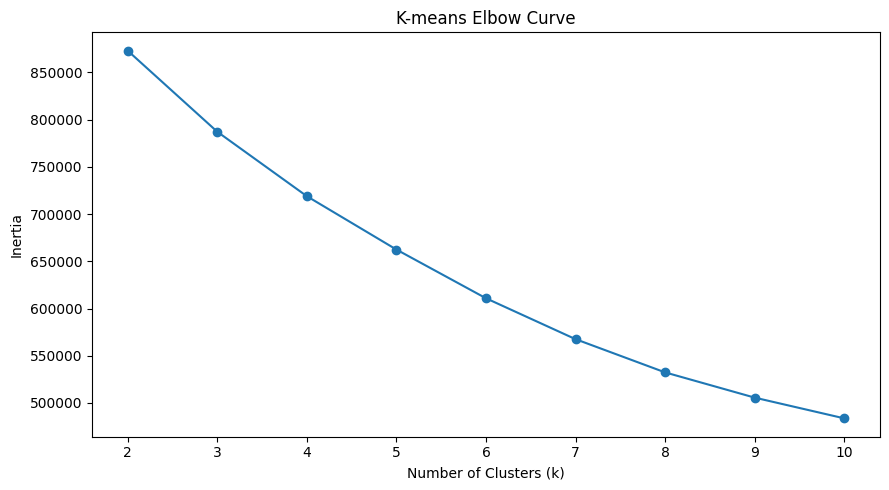

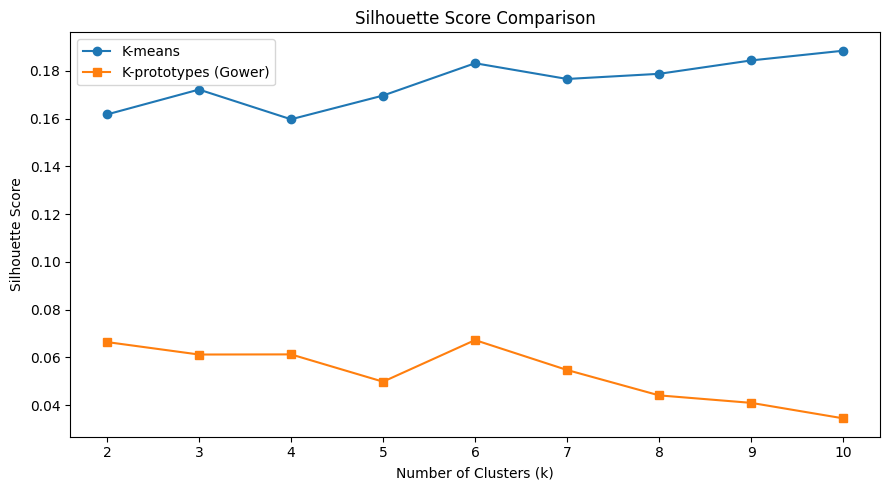

In [188]:
########========> PLOT THE ELBOW & SILHOUETTE CURVES
"""These plots help identify promising values of \(k\). They do not independently determine the final number of segments."""

import matplotlib.pyplot as plt

# Separate results
kmeans_results = results_df[
    results_df["algorithm"] == "KMeans"
]

kproto_results = results_df[
    results_df["algorithm"] == "KPrototypes"
]

# ---------------------------------------
# K-means elbow curve
# ---------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    kmeans_results["k"],
    kmeans_results["inertia"],
    marker="o"
)

plt.title("K-means Elbow Curve")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(range(2, 11))
plt.grid(False)
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "kmeans_elbow_curve.png",
    dpi=300
)

plt.show()


# ---------------------------------------
# Silhouette comparison
# ---------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    kmeans_results["k"],
    kmeans_results["silhouette_score"],
    marker="o",
    label="K-means"
)

plt.plot(
    kproto_results["k"],
    kproto_results["silhouette_score"],
    marker="s",
    label="K-prototypes (Gower)"
)

plt.title("Silhouette Score Comparison")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.legend()
plt.grid(False)
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "clustering_silhouette_comparison.png",
    dpi=300
)

plt.show()

In [189]:
###### Inspect cluster Sizes 
"""A high silhouette score is not enough if the model creates very small or commercially meaningless segments."""
cluster_size_results = []

for algorithm in ["KMeans", "KPrototypes"]:

    for k in range(2, 11):

        assignment_path = MODEL_DIR / f"{algorithm.lower()}_k{k}_assignments.csv"

        assignments = pd.read_csv(assignment_path)

        sizes = (
            assignments["cluster"]
            .value_counts()
            .sort_index()
        )

        for cluster, size in sizes.items():

            cluster_size_results.append({
                "algorithm": algorithm,
                "k": k,
                "cluster": cluster,
                "customer_count": size,
                "customer_percentage": (
                    size / len(assignments) * 100
                )
            })

cluster_sizes_df = pd.DataFrame(cluster_size_results)

cluster_sizes_df.to_csv(
    REPORT_DIR / "cluster_size_comparison.csv",
    index=False
)

display(cluster_sizes_df.head(20))

,algorithm,k,cluster,customer_count,customer_percentage
0,KMeans,2,0,42624,41.788235
1,KMeans,2,1,59376,58.211765
2,KMeans,3,0,60853,59.659804
3,KMeans,3,1,35657,34.957843
4,KMeans,3,2,5490,5.382353
5,KMeans,4,0,16317,15.997059
6,KMeans,4,1,31751,31.128431
7,KMeans,4,2,5110,5.009804
8,KMeans,4,3,48822,47.864706
9,KMeans,5,0,4995,4.897059


In [ ]:
#####======> Investigating cluster size
# Shortlisted candidate models
candidates = [
    ("kmeans", 6),
    ("kmeans", 9),
    ("kmeans", 10),
    ("kprototypes", 6)
]

for algorithm, k in candidates:

    file_path = (
        MODEL_DIR /
        f"{algorithm}_k{k}_assignments.csv"
    )

    assignments = pd.read_csv(file_path)

    print(f"\n{algorithm.upper()} - k={k}")

    cluster_summary = (
        assignments.groupby("cluster")
        .size()
        .reset_index(name="customer_count")
    )

    cluster_summary["percentage"] = (
        cluster_summary["customer_count"]
        / len(assignments) * 100
    )

    display(cluster_summary.round(2))


KMEANS - k=6


,cluster,customer_count,percentage
0,0,38780,38.02
1,1,13747,13.48
2,2,7536,7.39
3,3,13653,13.39
4,4,23425,22.97
5,5,4859,4.76



KMEANS - k=9


,cluster,customer_count,percentage
0,0,11288,11.07
1,1,12602,12.35
2,2,20528,20.13
3,3,7145,7.00
4,4,16614,16.29
5,5,4044,3.96
6,6,18653,18.29
7,7,4541,4.45
8,8,6585,6.46



KMEANS - k=10


,cluster,customer_count,percentage
0,0,4495,4.41
1,1,16638,16.31
2,2,7079,6.94
3,3,11258,11.04
4,4,6411,6.29
5,5,18646,18.28
6,6,2739,2.69
7,7,12507,12.26
8,8,1786,1.75
9,9,20441,20.04



KPROTOTYPES - k=6


,cluster,customer_count,percentage
0,0,22815,22.37
1,1,13281,13.02
2,2,7635,7.49
3,3,26023,25.51
4,4,5061,4.96
5,5,27185,26.65


#### Customer Segmentation profiling and customer Percona